# v15 — BRCA bone metastasis: classical statistics, Graph-CNN evaluation and explanation reliability

One notebook, three parts, run top to bottom ("Run all"):

| Part | What it does | Reviewer comments |
|---|---|---|
| **1** | Data, STRING graph, DEGs, tissue-composition scores, every survival analysis, external cohorts | #4, #6, #7 |
| **2** | Graph-CNN evaluation: one protocol, topology and filter-order tests, composition-adjusted models, label-shuffle controls | #1, #2, #4, #5, #7 |
| **3** | GLRP vs Integrated Gradients: gene- and pathway-level stability, deletion curves at all budgets, label-shuffle explanation controls, composition attribution, complementary datasets | #3, #4, #5, #6, #7 |

**Runtime.** Part 1 takes a few minutes. Part 2 trains about 2,000 small Graph-CNNs (roughly 1–3 h on CPU the first time). Part 3 takes about 20–40 min.
Every expensive step is checkpointed to disk, so after a disconnect, **Run all** continues where it stopped.

**Colab:** Google Drive is mounted and everything is stored in `My Drive/BRCA_GLRP_project_v15`. Copy your `data/` folder there to skip the downloads (~180 MB); otherwise they happen automatically.
**Local Jupyter:** the folder this notebook sits in is used.

Every number in the text cells is printed by the code; nothing in the markdown is hard-coded.

## Install packages (Colab or a fresh environment)
Run once per runtime. Packages that are already installed are skipped.

In [1]:
%pip install -q lifelines statsmodels networkx seaborn requests

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


## 0. Setup

In [2]:
import os, io, csv, gzip, json, time, re, pickle, warnings, hashlib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import hypergeom, mannwhitneyu, fisher_exact, chi2_contingency, spearmanr
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from lifelines import CoxPHFitter, KaplanMeierFitter, CoxTimeVaryingFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from lifelines.utils import concordance_index, to_episodic_format

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
np.random.seed(0)

# ---------------- paths ----------------
# PROJECT_ROOT is the folder this notebook sits in ("version 15"). Inputs live in data/,
# results in output/ and figures/. Nothing outside PROJECT_ROOT is written.
# ---------------- paths ----------------
# In Colab, everything lives in a Google Drive folder, so the three notebooks can hand results to each other across
# sessions (a Colab runtime's local disk is wiped when it disconnects). Locally, the folder this notebook sits in is used.
DRIVE_PROJECT_FOLDER = "BRCA_GLRP_project_v15"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = os.path.join("/content/drive/My Drive", DRIVE_PROJECT_FOLDER)
    IN_COLAB = True
except ImportError:
    PROJECT_ROOT = os.path.abspath(".")
    IN_COLAB = False
os.makedirs(PROJECT_ROOT, exist_ok=True)
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
OUT_DIR = os.path.join(PROJECT_ROOT, "output", "nb1")
FIG_DIR = os.path.join(PROJECT_ROOT, "figures", "nb1")
ART_DIR = os.path.join(PROJECT_ROOT, "output", "artifacts")
for d in (DATA_DIR, OUT_DIR, FIG_DIR, ART_DIR):
    os.makedirs(d, exist_ok=True)
print("Project root:", PROJECT_ROOT)

# ---------------- figure style (reviewer comment 7: figures were too small) ----------------
def set_style():
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight",
        "font.size": 14, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 15,
        "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12, "legend.title_fontsize": 13,
        "figure.titlesize": 18, "figure.titleweight": "bold", "lines.linewidth": 2.2, "lines.markersize": 7,
        "pdf.fonttype": 42, "ps.fonttype": 42,   # editable text in Illustrator / journal systems
    })
set_style()

def save_fig(fig, name):
    """Save every figure twice: 300-dpi PNG for slides/Word and vector PDF for the journal."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    plt.show()
    plt.close(fig)

def save_table(df, name, index=False):
    df.to_csv(os.path.join(OUT_DIR, name + ".csv"), index=index)
    return df

def download(url, dest, timeout=300):
    """Use the local copy in data/ when it exists; download only when it is missing."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return dest
    import requests
    print("Downloading", url)
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    with open(dest, "wb") as f:
        f.write(r.content)
    return dest

def place_labels(ax, xs, ys, labels, bold=(), fontsize=12, min_dy_frac=0.035, min_dx_frac=0.09):
    """Label points without overlap: labels that would collide are pushed vertically and joined to their point by a
    thin line (no extra package needed)."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    dy, dx = min_dy_frac * (y1 - y0), min_dx_frac * (x1 - x0)
    placed = []
    for i in np.argsort(-np.asarray(ys)):
        x, y = xs[i], ys[i]; ty = y
        for _ in range(60):
            if all(abs(ty - py) >= dy or abs(x - px) >= dx for px, py in placed):
                break
            ty -= dy
        placed.append((x, ty))
        ax.annotate(labels[i], (x, y), xytext=(x + 0.012 * (x1 - x0), ty), fontsize=fontsize, va="center",
                    fontweight="bold" if labels[i] in bold else "normal",
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="grey") if abs(ty - y) > 1e-9 else None)

def bh(p):
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.any():
        out[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return out

HUB_GENES = ["MMP9", "ITGB3", "BMP2", "CCL2", "PROM1"]   # Paper 1's five reported hub genes
T0_NOTEBOOK = time.time()

Project root: /Users/soumyasriperepu/researchAgent/version 15


## 1. Data

GSE175692 (NanoString, 184 metastatic biopsies) is the discovery cohort. GSE14020, GSE124647 and GSE11121 are the complementary cohorts used in Paper 1. Files already in `data/` are read directly.

In [3]:
def parse_series_matrix(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="latin-1") as f:
        lines = f.read().splitlines()
    meta, table_start, table_end = {}, None, None
    for i, line in enumerate(lines):
        if line.startswith("!series_matrix_table_begin"):
            table_start = i + 1
        elif line.startswith("!series_matrix_table_end"):
            table_end = i
        elif line.startswith("!"):
            parts = next(csv.reader([line], delimiter="\t"))
            meta.setdefault(parts[0].lstrip("!"), []).append(parts[1:])
    geo_acc = meta["Sample_geo_accession"][0]
    records = {s: {} for s in geo_acc}
    for row in meta.get("Sample_characteristics_ch1", []):
        for j, cell in enumerate(row):
            if j >= len(geo_acc):
                continue
            if ":" in cell:
                field, val = cell.split(":", 1)
                field, val = field.strip(), val.strip()
            else:
                field, val = "characteristic", cell.strip()
            records[geo_acc[j]].setdefault(field, val)
    clinical = pd.DataFrame.from_dict(records, orient="index").reindex(geo_acc)
    if "Sample_source_name_ch1" in meta:
        clinical.insert(0, "source_name", meta["Sample_source_name_ch1"][0])
    if "Sample_title" in meta:
        clinical.insert(0, "title", meta["Sample_title"][0])
    expr = pd.read_csv(io.StringIO("\n".join(lines[table_start:table_end])), sep="\t", index_col=0)
    expr.columns = [c.strip('"') for c in expr.columns]
    expr.index = [str(i).strip('"') for i in expr.index]
    return expr, clinical

GEO_FILES = {
    "GSE175692": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE175nnn/GSE175692/matrix/GSE175692_series_matrix.txt.gz",
    "GSE14020-GPL96": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14020/matrix/GSE14020-GPL96_series_matrix.txt.gz",
    "GSE14020-GPL570": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14020/matrix/GSE14020-GPL570_series_matrix.txt.gz",
    "GSE124647": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE124nnn/GSE124647/matrix/GSE124647_series_matrix.txt.gz",
    "GSE11121": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE11nnn/GSE11121/matrix/GSE11121_series_matrix.txt.gz",
}
geo_data = {}
for name, url in GEO_FILES.items():
    expr_, clin_ = parse_series_matrix(download(url, os.path.join(DATA_DIR, name + ".txt.gz")))
    geo_data[name] = (expr_, clin_)

expr175, clin175 = geo_data["GSE175692"]
expr175 = expr175.astype(float)
dataset_table = pd.DataFrame([
    ("GSE175692", "NanoString Breast Cancer 360", "metastatic biopsies (11 sites)", "discovery; Graph-CNN tasks; OS",
     expr175.shape[1], expr175.shape[0]),
    ("GSE14020 (GPL96 + GPL570)", "Affymetrix U133A / U133 Plus 2", "metastases (bone, brain, lung, liver)",
     "bone vs non-bone expression replication", geo_data["GSE14020-GPL96"][0].shape[1] + geo_data["GSE14020-GPL570"][0].shape[1],
     np.nan),
    ("GSE124647", "Affymetrix U133A", "metastatic biopsies, ER+ trial cohort", "OS replication",
     geo_data["GSE124647"][0].shape[1], geo_data["GSE124647"][0].shape[0]),
    ("GSE11121", "Affymetrix U133A", "node-negative untreated PRIMARY tumors", "DMFS (different endpoint)",
     geo_data["GSE11121"][0].shape[1], geo_data["GSE11121"][0].shape[0]),
], columns=["dataset", "platform", "material", "used for", "n_samples", "n_features"])
save_table(dataset_table, "datasets_overview")
display(dataset_table)

,dataset,platform,material,used for,n_samples,n_features
0,GSE175692,NanoString Breast Cancer 360,metastatic biopsies (11 sites),discovery; Graph-CNN tasks; OS,184,771.0
1,GSE14020 (GPL96 + GPL570),Affymetrix U133A / U133 Plus 2,"metastases (bone, brain, lung, liver)",bone vs non-bone expression replication,65,NaN
2,GSE124647,Affymetrix U133A,"metastatic biopsies, ER+ trial cohort",OS replication,140,22283.0
3,GSE11121,Affymetrix U133A,node-negative untreated PRIMARY tumors,DMFS (different endpoint),200,22283.0


## 2. STRING v12 protein–protein interaction graph

Same construction as v14: combined score ≥ 400, restricted to the 771-gene panel, largest connected component (737 genes). All STRING edges among panel genes are also saved with their scores, so Part 2 can build the ≥ 700 and ≥ 900 graphs on the same node set.

In [4]:
STRING_LINKS_URL = "https://stringdb-downloads.org/download/protein.links.v12.0/9606.protein.links.v12.0.txt.gz"
STRING_INFO_URL = "https://stringdb-downloads.org/download/protein.info.v12.0/9606.protein.info.v12.0.txt.gz"
links_path = download(STRING_LINKS_URL, os.path.join(DATA_DIR, "string_links.txt.gz"))
info_path = download(STRING_INFO_URL, os.path.join(DATA_DIR, "string_info.txt.gz"))

info = pd.read_csv(info_path, sep="\t", compression="gzip")
ensp2sym = dict(zip(info["#string_protein_id"], info["preferred_name"]))
links = pd.read_csv(links_path, sep=" ", compression="gzip")
links_hc = links[links["combined_score"] >= 400].copy()
links_hc["sym1"] = links_hc["protein1"].map(ensp2sym)
links_hc["sym2"] = links_hc["protein2"].map(ensp2sym)
links_hc = links_hc.dropna(subset=["sym1", "sym2"])
del links

array_genes = set(expr175.index)
edges_restricted = links_hc[links_hc["sym1"].isin(array_genes) & links_hc["sym2"].isin(array_genes)]
G_full = nx.from_pandas_edgelist(edges_restricted, "sym1", "sym2")
G_full.add_nodes_from(array_genes)
G_main = G_full.subgraph(max(nx.connected_components(G_full), key=len)).copy()
gene_list = sorted(G_main.nodes())
A = nx.to_scipy_sparse_array(G_main, nodelist=gene_list, format="csr")
string_panel_edges = edges_restricted[["sym1", "sym2", "combined_score"]].reset_index(drop=True)

print(f"STRING edges with combined score >= 400 (all human proteins): {len(links_hc):,}")
print(f"Graph on the {len(array_genes)}-gene panel; main connected component: "
      f"{G_main.number_of_nodes()} genes, {G_main.number_of_edges():,} edges")
print("Hub genes in graph:", [g for g in HUB_GENES if g in gene_list])
sp.save_npz(os.path.join(DATA_DIR, "ppi_adjacency.npz"), A)

STRING edges with combined score >= 400 (all human proteins): 1,858,944
Graph on the 771-gene panel; main connected component: 737 genes, 19,902 edges
Hub genes in graph: ['MMP9', 'ITGB3', 'BMP2', 'CCL2', 'PROM1']


## 3. Cohort, labels and the patient-identity limitation

* **Task 1** — bone vs non-bone metastatic biopsy site.
* **Task 2** — death within 36 months of metastatic diagnosis vs alive at 36 months (landmark label; patients censored at or before 36 months are excluded because their status is unknown).

GSE175692 has 184 samples from 176 patients, but its public metadata does not identify which samples share a patient. Matching identical patient-level clinical profiles gives 178 profiles, not 176, so the inferred grouping is **not** used and all cross-validation is sample-level. This is stated as a limitation.

In [5]:
bone_mask = clin175["organ"] == "Bone"
gl_expr = expr175.loc[gene_list]
clin175_model = clin175.reindex(gl_expr.columns).copy()
assert clin175_model.index.equals(gl_expr.columns)

y_task1 = (clin175_model["organ"] == "Bone").astype(int).to_numpy()
ev = pd.to_numeric(clin175_model["ose"], errors="coerce")
t_months = pd.to_numeric(clin175_model["os (months) since dxmet"], errors="coerce")
died_within_36 = (ev == 1) & (t_months <= 36)
alive_after_36 = t_months > 36
task2_mask = (died_within_36 | alive_after_36).to_numpy()
y_task2 = np.where(died_within_36.to_numpy(), 1, 0)[task2_mask]

TASK_INFO = {
    "bone_metastasis": {"ids": list(gl_expr.columns), "y": y_task1,
                        "label": "Task 1: bone vs non-bone metastatic biopsy"},
    "survival_outcome": {"ids": list(gl_expr.columns[task2_mask]), "y": y_task2,
                         "label": "Task 2: death within 36 months vs alive at 36 months"},
}
for k, v in TASK_INFO.items():
    print(f"{v['label']}: n={len(v['y'])}, positives={int(v['y'].sum())}, negatives={int((1 - v['y']).sum())}")

profile_cols = [c for c in ["age (years)", "ose", "os (months) since dxmet", "pre-post menopausal",
                            "de novo metastasis vs relapsed", "hr", "her2"] if c in clin175.columns]
prof_key = clin175[profile_cols].astype(str).apply(lambda s: s.str.strip().str.upper()).agg("|".join, axis=1)
n_profiles = prof_key.nunique()
print(f"\nIdentical patient-level clinical profiles: {n_profiles} for {len(prof_key)} samples "
      f"(published: 176 patients) -> patient grouping NOT used; CV is sample-level.")
PATIENT_GROUPING = "none (sample-level CV; 184 samples from 176 patients, mapping not recoverable)"
site_counts = clin175["organ"].value_counts().rename_axis("site").reset_index(name="n_samples")
save_table(site_counts, "metastatic_site_counts")
display(site_counts.T)

Task 1: bone vs non-bone metastatic biopsy: n=184, positives=33, negatives=151
Task 2: death within 36 months vs alive at 36 months: n=152, positives=68, negatives=84

Identical patient-level clinical profiles: 178 for 184 samples (published: 176 patients) -> patient grouping NOT used; CV is sample-level.


,0,1,2,3,4,5,6,7,8,9,10
site,Bone,Liver,Skin,Breast,Brain,Lymph node,Lung,Pleura,Ovary,Muscle,Peritoneum
n_samples,33,31,27,24,22,16,13,10,4,2,2


## 4. Differential expression (bone vs non-bone) and KEGG enrichment

Welch t-test per gene, Benjamini–Hochberg FDR across all 771 genes, significance = FDR < 0.05 and |log2FC| > 1.

KEGG enrichment is computed **locally** (hypergeometric test, BH-adjusted) against the 737-gene panel as background, using the KEGG_2021_Human library cached in `data/`. The panel is a curated cancer panel, so a genome-wide background would overstate enrichment. The library is downloaded once through gseapy and then reused offline by all three notebooks.

Bone n=33, non-bone n=151; significant DEGs: 68 (up 55, down 13)


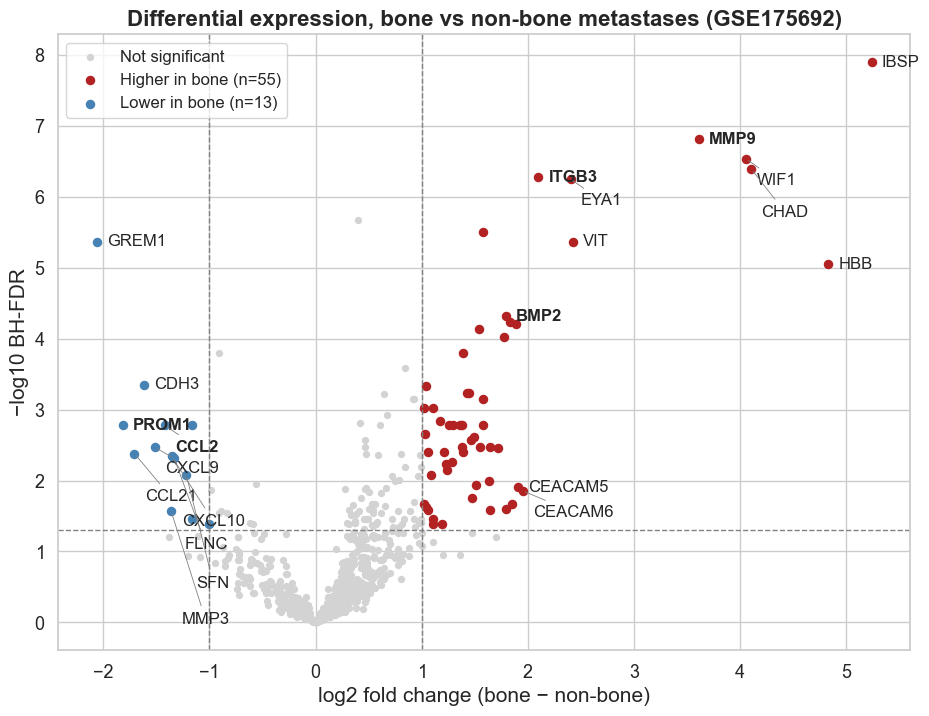

In [6]:
def welch_deg(expr, group_a, group_b):
    rows = []
    for gene in expr.index:
        a = pd.to_numeric(expr.loc[gene, group_a], errors="coerce").dropna()
        b = pd.to_numeric(expr.loc[gene, group_b], errors="coerce").dropna()
        _, p = stats.ttest_ind(a, b, equal_var=False, nan_policy="omit")
        rows.append((gene, a.mean() - b.mean(), p, len(a), len(b)))
    d = pd.DataFrame(rows, columns=["gene", "logFC", "pvalue", "n_bone", "n_nonbone"]).dropna(subset=["pvalue"])
    d["FDR"] = bh(d["pvalue"])
    return d

DEG_FDR_CUTOFF, DEG_LOGFC_CUTOFF = 0.05, 1.0
bone_samples, other_samples = clin175.index[bone_mask], clin175.index[~bone_mask]
deg = welch_deg(expr175, bone_samples, other_samples)
deg_sig = deg[(deg.FDR < DEG_FDR_CUTOFF) & (deg.logFC.abs() > DEG_LOGFC_CUTOFF)].copy()
top20 = pd.concat([deg_sig.sort_values("logFC", ascending=False).head(10), deg_sig.sort_values("logFC").head(10)])
save_table(deg.sort_values("pvalue"), "DEG_all_genes_GSE175692")
save_table(deg_sig.sort_values("pvalue"), "DEGs_significant_GSE175692")
print(f"Bone n={bone_mask.sum()}, non-bone n={(~bone_mask).sum()}; significant DEGs: {len(deg_sig)} "
      f"(up {int((deg_sig.logFC > 0).sum())}, down {int((deg_sig.logFC < 0).sum())})")

fig, ax = plt.subplots(figsize=(11, 8))
deg["neglogFDR"] = -np.log10(deg["FDR"].clip(lower=1e-300))
ns_ = deg[~deg.gene.isin(deg_sig.gene)]
ax.scatter(ns_.logFC, ns_.neglogFDR, s=18, color="lightgrey", label="Not significant")
up_, dn_ = deg[deg.gene.isin(deg_sig[deg_sig.logFC > 0].gene)], deg[deg.gene.isin(deg_sig[deg_sig.logFC < 0].gene)]
ax.scatter(up_.logFC, up_.neglogFDR, s=34, color="firebrick", label=f"Higher in bone (n={len(up_)})")
ax.scatter(dn_.logFC, dn_.neglogFDR, s=34, color="steelblue", label=f"Lower in bone (n={len(dn_)})")
lab_ = deg[deg.gene.isin(top20.gene) | deg.gene.isin(HUB_GENES)]
place_labels(ax, lab_.logFC.values, lab_.neglogFDR.values, lab_.gene.values, bold=set(HUB_GENES))
for x in (DEG_LOGFC_CUTOFF, -DEG_LOGFC_CUTOFF):
    ax.axvline(x, ls="--", color="grey", lw=1)
ax.axhline(-np.log10(DEG_FDR_CUTOFF), ls="--", color="grey", lw=1)
ax.set_xlabel("log2 fold change (bone − non-bone)")
ax.set_ylabel("−log10 BH-FDR")
ax.set_title("Differential expression, bone vs non-bone metastases (GSE175692)")
ax.legend(loc="upper left", frameon=True)
save_fig(fig, "01_volcano")

Downloaded KEGG_2021_Human from Enrichr (320 pathways) and cached it in data/.
KEGG_2021_Human: 320 pathways; 212 have >= 5 genes in the 737-gene panel


,Term,Overlap,P-value,Adjusted P-value,Genes
0,ECM-receptor interaction,6/24,0.015182,0.998147,CD36;CHAD;COMP;IBSP;ITGB3;SPP1
1,Cholesterol metabolism,2/4,0.042121,0.998147,CD36;LPL
2,PPAR signaling pathway,2/4,0.042121,0.998147,CD36;LPL
3,IL-17 signaling pathway,4/18,0.068796,0.998147,CCL2;CXCL10;MMP3;MMP9
4,Caffeine metabolism,1/1,0.089552,0.998147,NAT1
5,Glycerolipid metabolism,1/1,0.089552,0.998147,LPL
6,Retinol metabolism,1/1,0.089552,0.998147,ALDH1A1
7,Malaria,4/21,0.109892,0.998147,CCL2;CD36;COMP;HBB
8,Phagosome,5/30,0.121416,0.998147,CD36;COLEC12;COMP;ITGB3;MARCO
9,Cytokine-cytokine receptor interaction,9/67,0.132481,0.998147,BMP2;BMP5;BMP8A;CCL2;CCL21;CXCL10;CXCL9;LEPR;LIFR


KEGG pathways with BH-FDR < 0.05 against the panel background: 0


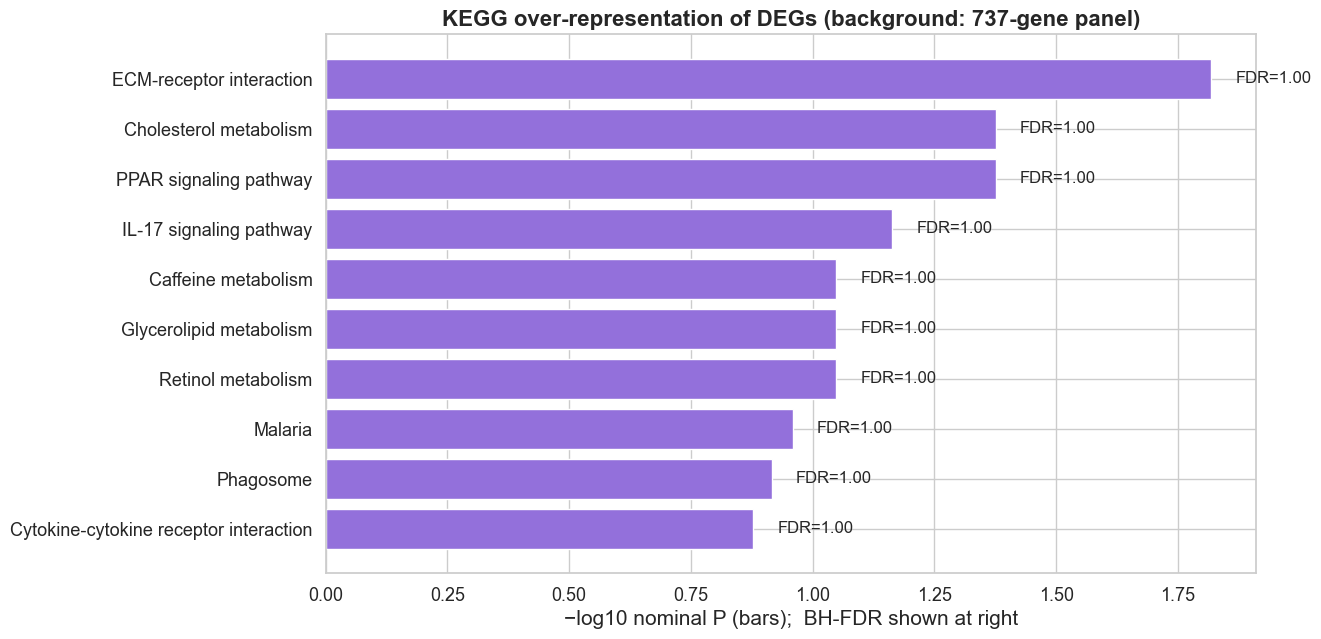

In [7]:
KEGG_LIBRARY_NAME = "KEGG_2021_Human"
KEGG_CACHE = os.path.join(DATA_DIR, KEGG_LIBRARY_NAME + ".json")

def load_kegg_library():
    """KEGG library as {term: [genes]}; cached in data/ so later runs (and notebooks 2-3) work offline."""
    if os.path.exists(KEGG_CACHE):
        with open(KEGG_CACHE) as f:
            return json.load(f)
    import requests
    url = f"https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName={KEGG_LIBRARY_NAME}"
    for attempt in range(5):
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            lib = {}
            for line in r.text.splitlines():
                parts = line.split("\t")
                if len(parts) > 2:
                    lib[parts[0]] = [g.split(",")[0].strip() for g in parts[2:] if g.strip()]
            if len(lib) < 100:
                raise ValueError(f"only {len(lib)} terms received")
            with open(KEGG_CACHE, "w") as f:
                json.dump(lib, f)
            print(f"Downloaded {KEGG_LIBRARY_NAME} from Enrichr ({len(lib)} pathways) and cached it in data/.")
            return lib
        except Exception as e:
            print(f"Direct Enrichr download failed ({e}); retry {attempt + 1}/5")
            time.sleep(5 * (attempt + 1))
    try:                                    # fallback: gseapy, if installed
        import gseapy as gp
        lib = gp.get_library(name=KEGG_LIBRARY_NAME, organism="Human")
        with open(KEGG_CACHE, "w") as f:
            json.dump(lib, f)
        return lib
    except Exception as e:
        print(f"gseapy fallback failed ({e})")
    raise RuntimeError("Could not obtain the KEGG library. Copy KEGG_2021_Human.json into data/ and rerun.")

def enrich_local(genes, library, background, min_overlap=1):
    """Hypergeometric over-representation against `background`; BH across tested terms (overlap >= min_overlap).
    Same test as gseapy.enrich(); implemented locally so it is fast and needs no web API."""
    bg = set(background)
    q = set(genes) & bg
    M, Nq = len(bg), len(q)
    rows = []
    for term, tg in library.items():
        ts = set(tg) & bg
        k = len(ts & q)
        if k < min_overlap or not ts:
            continue
        rows.append((term, k, len(ts), hypergeom.sf(k - 1, M, len(ts), Nq), ";".join(sorted(ts & q))))
    out = pd.DataFrame(rows, columns=["Term", "k", "term_size_in_background", "P-value", "Genes"])
    if len(out):
        out["Adjusted P-value"] = bh(out["P-value"])
        out["Overlap"] = out["k"].astype(str) + "/" + out["term_size_in_background"].astype(str)
        out = out.sort_values(["Adjusted P-value", "P-value"]).reset_index(drop=True)
    return out

kegg_lib = load_kegg_library()
print(f"{KEGG_LIBRARY_NAME}: {len(kegg_lib)} pathways; "
      f"{sum(1 for t in kegg_lib.values() if len(set(t) & set(gene_list)) >= 5)} have >= 5 genes in the 737-gene panel")
kegg_deg = enrich_local(deg_sig.gene, kegg_lib, gene_list)
save_table(kegg_deg, "KEGG_enrichment_DEGs_panel_background")
display(kegg_deg[["Term", "Overlap", "P-value", "Adjusted P-value", "Genes"]].head(10))
n_sig_terms = int((kegg_deg["Adjusted P-value"] < 0.05).sum()) if len(kegg_deg) else 0
print(f"KEGG pathways with BH-FDR < 0.05 against the panel background: {n_sig_terms}")

fig, ax = plt.subplots(figsize=(12, 7))
pdf_ = kegg_deg.head(10).iloc[::-1]
ax.barh(pdf_.Term.str.slice(0, 50), -np.log10(pdf_["P-value"]), color="mediumpurple")
ax.set_xlabel("−log10 nominal P (bars);  BH-FDR shown at right")
for i, (_, r) in enumerate(pdf_.iterrows()):
    ax.text(-np.log10(r["P-value"]) + 0.05, i, f"FDR={r['Adjusted P-value']:.2f}", va="center", fontsize=12)
ax.set_title("KEGG over-representation of DEGs (background: 737-gene panel)")
save_fig(fig, "02_kegg_DEGs")

## 5. Tissue composition (reviewer comment 4, statistical part)

A metastatic biopsy contains the host tissue around the tumor. In a bone biopsy that can mean bone matrix, osteoclasts, marrow (erythroid and myeloid precursors, megakaryocytes) and immune cells. Several of the strongest "bone" DEGs (IBSP, HBB, CHAD) are classic markers of these compartments, so the bone-vs-non-bone signal could partly reflect what was sampled rather than tumor biology.

**Approach (all unsupervised, label-free scores):**
1. Curated canonical markers for each compartment, restricted to genes on the panel. The NanoString panel has few pure host-tissue markers, so single-gene compartments are kept for description. One of them, HBB (erythroid marrow), is pre-specified for adjustment because carcinoma cells do not express it. MMP9 (osteoclast) is described but never used for adjustment, because it is a Paper 1 hub gene and is also expressed by tumor cells.
2. Composition score per sample = mean z-score of the compartment's markers. Marker coherence (mean pairwise Spearman correlation) is reported. A score whose markers do not co-vary is flagged as unreliable and is not used for adjustment.
3. Do the scores differ by site?
4. Do the DEGs survive adjustment for the reliable scores? Two adjustment sets are used: (A) all reliable scores, including the bone-matrix score, which is a conservative lower bound because that score also captures genuine tumor osteomimicry; (B) host immune, stromal and marrow scores only. Each marker gene is adjusted with a leave-gene-out score, so no gene is adjusted for itself.

Part 2 then asks whether **classification** depends on these compartments: it neutralizes or residualizes them and trains a composition-only classifier. Part 3 asks whether the **attributions** concentrate on them.

In [8]:
# Canonical marker genes. Sources: standard cell-type marker panels (LM22 / xCell / PanglaoDB canonical markers,
# bone-biology reviews). Deliberately conservative and pre-specified; only genes present on the panel are used.
COMPARTMENT_MARKERS = {
    "Bone matrix / osteoblast": ["IBSP", "SPP1", "BGLAP", "RUNX2", "SP7", "ALPL", "PHEX", "DMP1", "MEPE", "SOST",
                                 "CHAD", "OMD", "PTH1R", "COL11A1"],
    "Osteoclast": ["ACP5", "CTSK", "OSCAR", "CALCR", "TNFRSF11A", "DCSTAMP", "OCSTAMP", "MMP9"],
    "Erythroid (marrow)": ["HBB", "HBA1", "HBA2", "HBD", "HBG1", "HBG2", "ALAS2", "GYPA", "CA1", "AHSP", "SLC4A1"],
    "Myeloid precursor (marrow)": ["MPO", "ELANE", "PRTN3", "AZU1", "CTSG", "LTF", "CAMP", "DEFA4", "CEACAM8", "MS4A3"],
    "Megakaryocyte / platelet": ["PF4", "PPBP", "ITGA2B", "GP9", "GP1BA"],
    "T cell": ["CD3D", "CD3E", "CD3G", "CD2", "CD8A", "CD8B", "CD247", "LCK", "CD6", "TRAT1"],
    "B cell": ["MS4A1", "CD19", "CD79A", "CD79B", "CD22", "BLK", "PAX5"],
    "Plasma cell": ["MZB1", "JCHAIN", "IGKC", "TNFRSF17"],
    "NK / cytotoxic": ["NKG7", "GNLY", "KLRD1", "KLRB1", "PRF1", "GZMB", "GZMA", "GZMH", "KLRK1"],
    "Macrophage / monocyte": ["CD68", "CD163", "CD14", "MRC1", "MSR1", "MARCO", "C1QA", "C1QB", "CSF1R"],
    "Endothelial": ["PECAM1", "CDH5", "VWF", "KDR", "TEK", "CLDN5", "ESAM", "EMCN"],
    "Fibroblast / stroma": ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM", "FAP", "PDGFRA", "PDGFRB", "FBLN1"],
    "Hepatocyte (liver site)": ["ALB", "APOA1", "APOH", "TF", "HP", "FGB", "SERPINA1"],
    "Lung alveolar (lung site)": ["SFTPC", "SFTPB", "SFTPA1", "NAPSA", "AGER"],
    "Keratinocyte (skin site)": ["KRT1", "KRT10", "LOR", "FLG"],
    "Glia / neuron (brain site)": ["GFAP", "OLIG2", "MBP", "PLP1", "SNAP25"],
}
BONE_RELATED_COMPARTMENTS = ["Bone matrix / osteoblast", "Osteoclast", "Erythroid (marrow)",
                             "Myeloid precursor (marrow)", "Megakaryocyte / platelet"]
MIN_MARKERS = 1
COHERENCE_MIN = 0.20   # mean pairwise Spearman among markers; below this a multi-marker score is flagged "unreliable"
# The NanoString panel carries few pure host-tissue markers. A single-gene compartment is used for ADJUSTMENT only when
# that gene is a canonical lineage marker not expressed by carcinoma cells (pre-specified here). MMP9 (osteoclast) is
# shown descriptively but never used for adjustment: it is a Paper 1 hub gene and is also expressed by tumor and stroma.
SINGLE_MARKER_PROXIES_FOR_ADJUSTMENT = ["Erythroid (marrow)"]

expr_gl = expr175.loc[gene_list]
marker_rows, comp_markers = [], {}
for comp, genes in COMPARTMENT_MARKERS.items():
    present = [g for g in genes if g in gene_list]
    marker_rows += [{"compartment": comp, "gene": g, "on_panel": g in gene_list} for g in genes]
    if len(present) >= MIN_MARKERS:
        comp_markers[comp] = present
marker_table = pd.DataFrame(marker_rows)
save_table(marker_table, "composition_marker_genes_all")

def zscore_rows(df):
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1).replace(0, np.nan), axis=0)

z_gl = zscore_rows(expr_gl)
comp_scores = pd.DataFrame({c: z_gl.loc[g].mean(axis=0, skipna=True) for c, g in comp_markers.items()})
coh_rows = []
for c, g in comp_markers.items():
    if len(g) >= 2:
        R = expr_gl.loc[g].T.corr(method="spearman").to_numpy()
        coh = float(np.nanmean(R[np.triu_indices(len(g), 1)]))
        reliable = coh >= COHERENCE_MIN
    else:
        coh, reliable = np.nan, c in SINGLE_MARKER_PROXIES_FOR_ADJUSTMENT
    coh_rows.append({"compartment": c, "n_markers_on_panel": len(g), "markers_on_panel": ", ".join(g),
                     "mean_pairwise_spearman": coh, "reliable_score": reliable,
                     "score_type": "multi-marker" if len(g) >= 2 else "single-gene proxy",
                     "bone_related": c in BONE_RELATED_COMPARTMENTS})
composition_coherence = pd.DataFrame(coh_rows)
dropped = [c for c in COMPARTMENT_MARKERS if c not in comp_markers]
save_table(composition_coherence, "composition_compartments_markers_and_coherence")
display(composition_coherence)
print("Compartments with no marker on the 737-gene panel:", dropped)
RELIABLE_COMPARTMENTS = composition_coherence.loc[composition_coherence.reliable_score, "compartment"].tolist()
print("Reliable composition scores used for adjustment:", RELIABLE_COMPARTMENTS)

,compartment,n_markers_on_panel,markers_on_panel,mean_pairwise_spearman,reliable_score,score_type,bone_related
0,Bone matrix / osteoblast,4,"IBSP, SPP1, CHAD, COL11A1",0.318042,True,multi-marker,True
1,Osteoclast,1,MMP9,NaN,False,single-gene proxy,True
2,Erythroid (marrow),1,HBB,NaN,True,single-gene proxy,True
3,T cell,2,"CD8A, CD8B",0.729934,True,multi-marker,False
4,B cell,2,"CD19, PAX5",0.720452,True,multi-marker,False
5,NK / cytotoxic,7,"NKG7, GNLY, PRF1, GZMB, GZMA, GZMH, KLRK1",0.700017,True,multi-marker,False
6,Macrophage / monocyte,4,"CD68, CD163, MSR1, MARCO",0.436541,True,multi-marker,False
7,Endothelial,5,"PECAM1, CDH5, KDR, TEK, EMCN",0.712760,True,multi-marker,False
8,Fibroblast / stroma,4,"DCN, FAP, PDGFRA, PDGFRB",0.687499,True,multi-marker,False


Compartments with no marker on the 737-gene panel: ['Myeloid precursor (marrow)', 'Megakaryocyte / platelet', 'Plasma cell', 'Hepatocyte (liver site)', 'Lung alveolar (lung site)', 'Keratinocyte (skin site)', 'Glia / neuron (brain site)']
Reliable composition scores used for adjustment: ['Bone matrix / osteoblast', 'Erythroid (marrow)', 'T cell', 'B cell', 'NK / cytotoxic', 'Macrophage / monocyte', 'Endothelial', 'Fibroblast / stroma']


,compartment,median_bone,median_nonbone,rank_biserial_r,P,reliable_score,FDR
0,Bone matrix / osteoblast,1.1918,-0.2174,0.7572,0.0000,True,0.0000
1,Osteoclast,1.4469,-0.2883,0.7331,0.0000,False,0.0000
2,Erythroid (marrow),1.3061,-0.3248,0.6592,0.0000,True,0.0000
4,B cell,0.0899,-0.2172,0.1824,0.1014,True,0.2282
7,Endothelial,0.2460,0.0317,0.1615,0.1469,True,0.2645
3,T cell,-0.0881,-0.0222,-0.1274,0.2527,True,0.3486
6,Macrophage / monocyte,-0.0223,0.0655,-0.1226,0.2711,True,0.3486
8,Fibroblast / stroma,0.1768,0.0455,0.1005,0.3671,True,0.4129
5,NK / cytotoxic,0.2456,-0.1241,0.0901,0.4190,True,0.4190


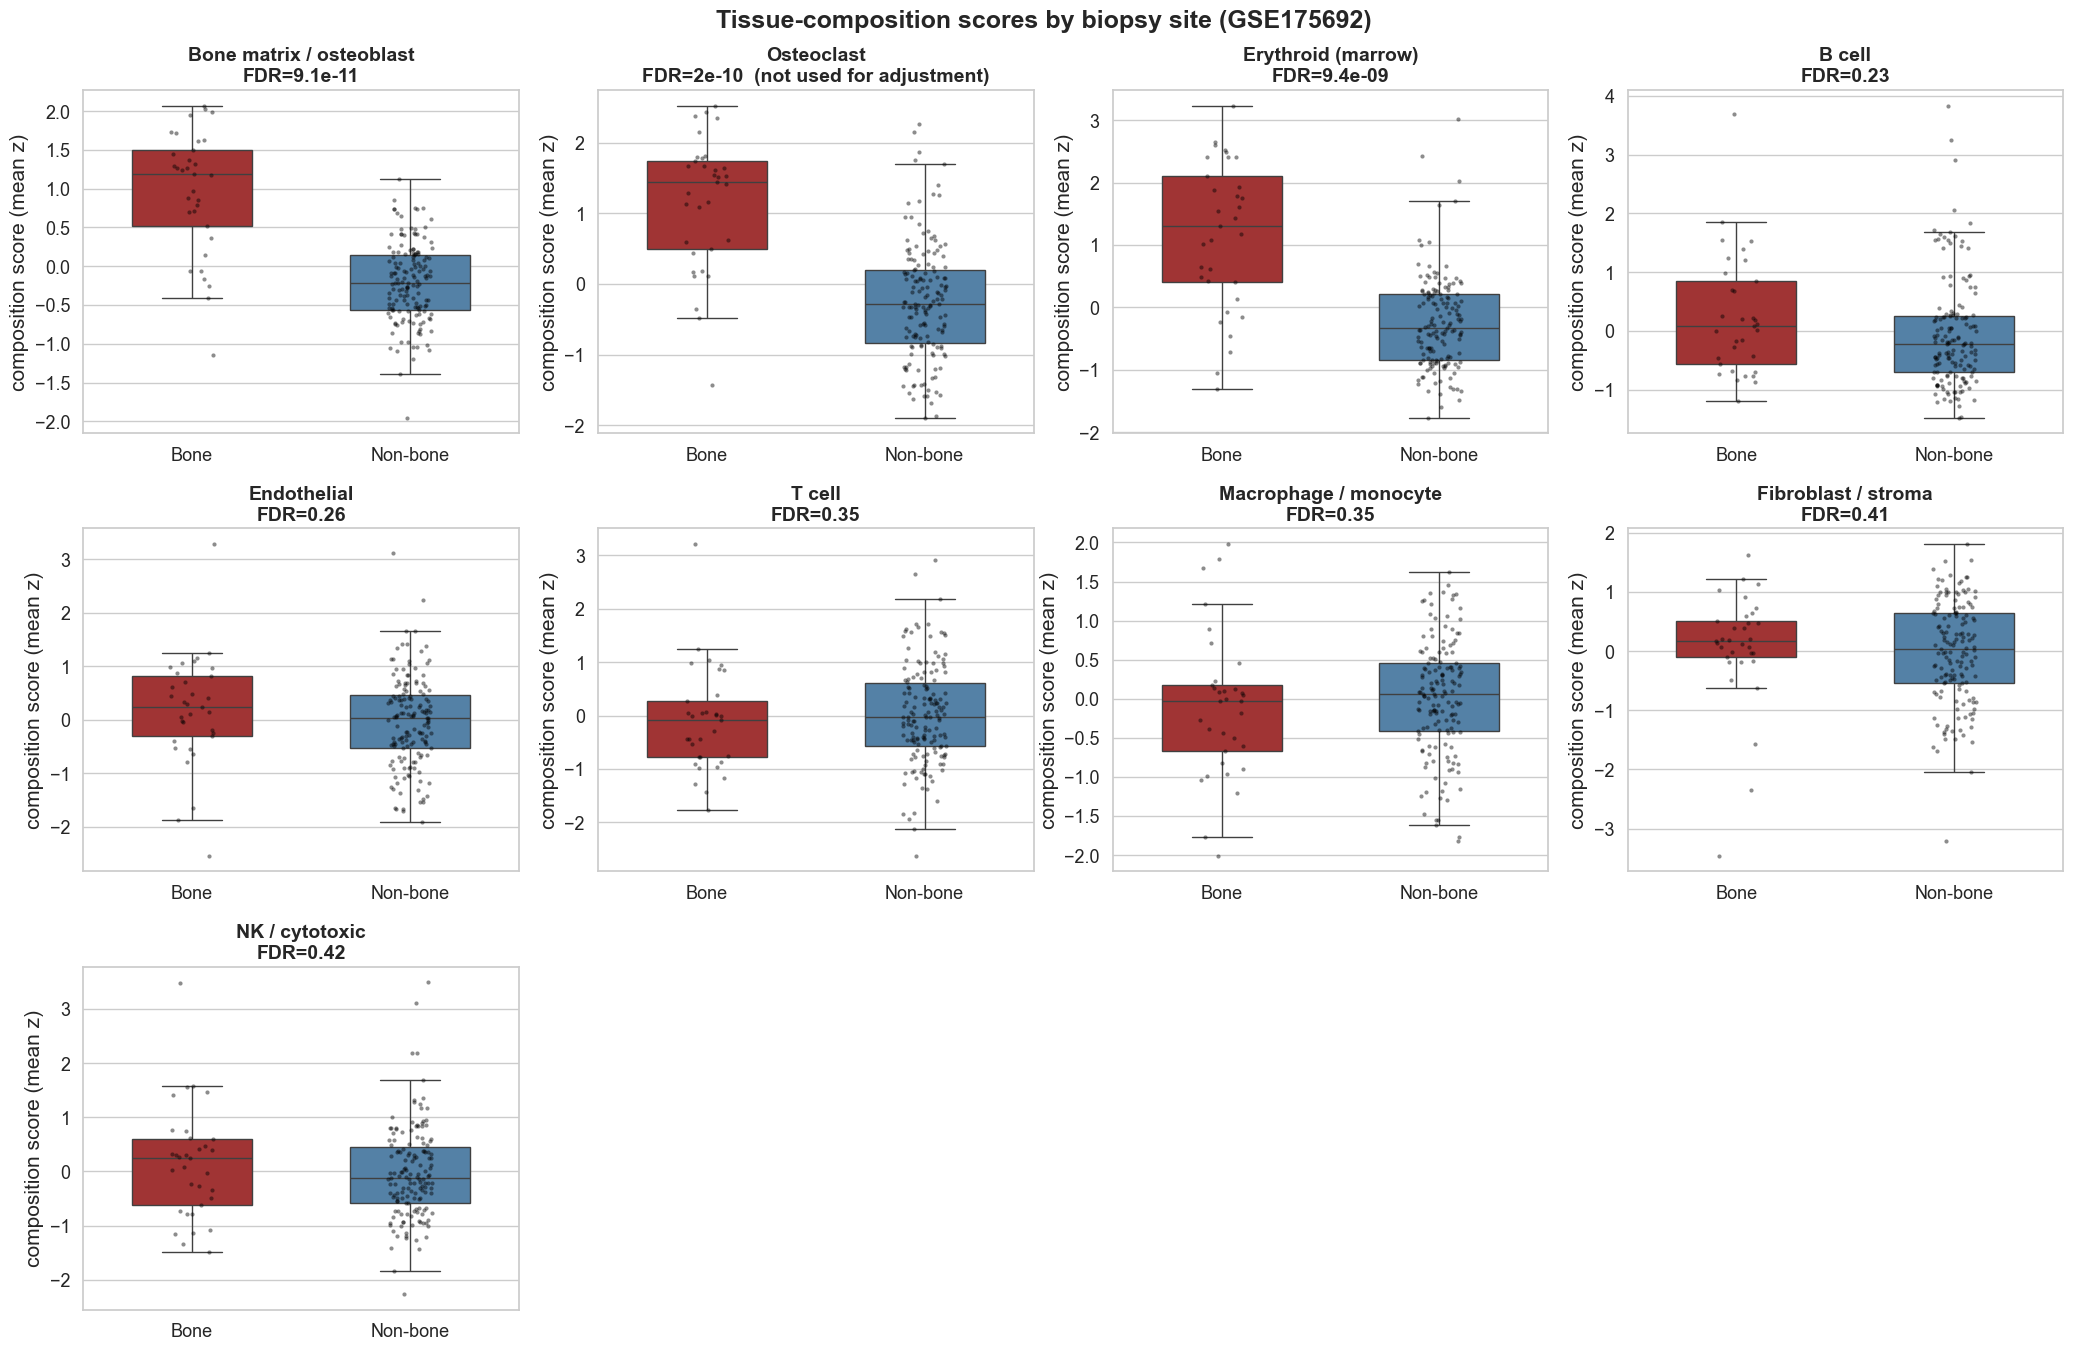

In [9]:
# Do the composition scores differ between bone and non-bone biopsies?
cs = comp_scores.reindex(clin175.index)
site_rows = []
for c in comp_scores.columns:
    a, b = cs.loc[bone_mask, c].dropna(), cs.loc[~bone_mask, c].dropna()
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    site_rows.append({"compartment": c, "median_bone": a.median(), "median_nonbone": b.median(),
                      "rank_biserial_r": 2 * u / (len(a) * len(b)) - 1, "P": p,
                      "reliable_score": c in RELIABLE_COMPARTMENTS})
composition_by_site = pd.DataFrame(site_rows)
composition_by_site["FDR"] = bh(composition_by_site.P)
composition_by_site = composition_by_site.sort_values("P")
save_table(composition_by_site, "composition_scores_bone_vs_nonbone")
display(composition_by_site.round(4))

n_c = len(comp_scores.columns)
ncols = 4
nrows = int(np.ceil(n_c / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.6 * nrows), squeeze=False)
for ax, (_, r) in zip(axes.ravel(), composition_by_site.iterrows()):
    d_ = pd.DataFrame({"score": cs[r.compartment], "site": np.where(bone_mask, "Bone", "Non-bone")})
    sns.boxplot(data=d_, x="site", y="score", order=["Bone", "Non-bone"], palette=["firebrick", "steelblue"],
                ax=ax, showfliers=False, width=0.55)
    sns.stripplot(data=d_, x="site", y="score", order=["Bone", "Non-bone"], color="black", size=3, alpha=0.45, ax=ax)
    ax.set_title(f"{r.compartment}\nFDR={r.FDR:.2g}" + ("" if r.reliable_score else "  (not used for adjustment)"), fontsize=14)
    ax.set_xlabel(""); ax.set_ylabel("composition score (mean z)")
for ax in axes.ravel()[n_c:]:
    ax.axis("off")
fig.suptitle("Tissue-composition scores by biopsy site (GSE175692)")
fig.tight_layout()
save_fig(fig, "03_composition_scores_by_site")

,adjustment,scores,DEGs_unadjusted,still_significant_same_direction,median_effect_retained
0,A: all reliable scores,"Bone matrix / osteoblast, Erythroid (marrow), T cell, B cell, NK / cytotoxic...",66,9,0.363089
1,B: host immune/stroma/marrow only (bone-matrix score excluded),"Erythroid (marrow), T cell, B cell, NK / cytotoxic, Macrophage / monocyte, E...",66,24,0.681769


Of the 66 DEGs on the graph panel, 7 are composition markers themselves.
Note: adjustment A includes the bone-matrix score, which is itself strongly bone-associated (it captures both sampled bone tissue and tumor osteomimicry), so A is a conservative lower bound; B removes only host immune, stromal and marrow signal.

Hub genes before vs after composition adjustment:


,gene,logFC,FDR,logFC_adj_A,FDR_adj_A,logFC_adj_B,FDR_adj_B,is_composition_marker
51,BMP2,1.7930,0.0000,0.6055,0.1943,1.0560,0.0015,False
77,CCL2,-1.4198,0.0017,-0.8073,0.1350,-0.9396,0.0183,False
377,ITGB3,2.1000,0.0000,0.0558,0.9154,1.1633,0.0002,False
448,MMP9,3.6099,0.0000,1.4614,0.0920,2.9212,0.0000,True
559,PROM1,-1.8181,0.0017,-1.3870,0.2609,-1.3100,0.1586,False


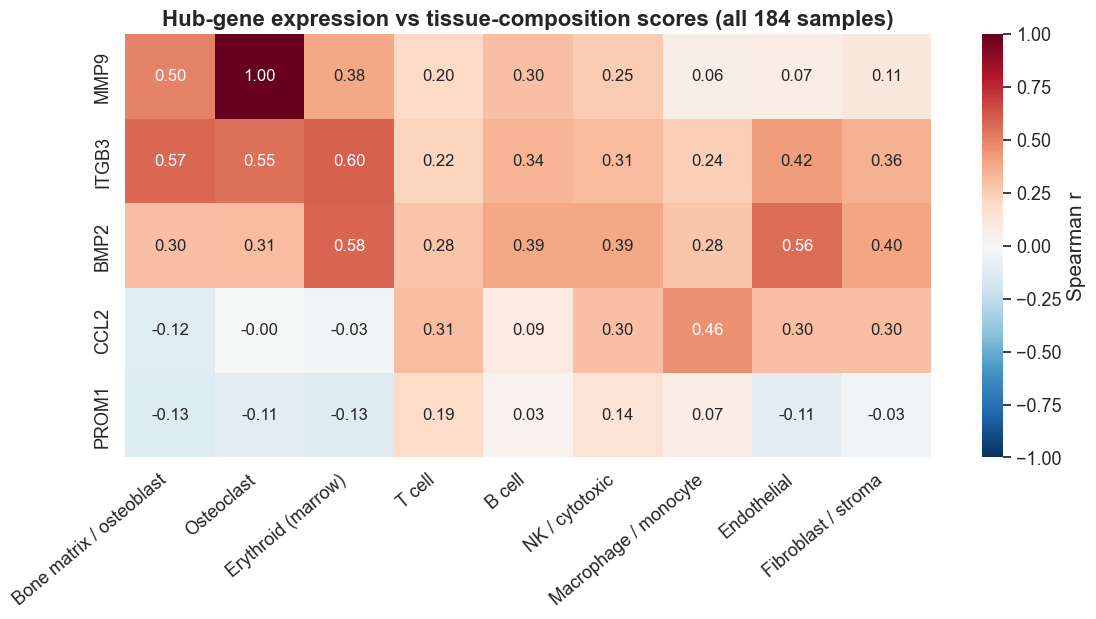

In [10]:
# Do the DEGs survive adjustment for composition?  expr ~ bone + reliable composition scores.
# For a gene that is itself a marker, its own compartment score is recomputed without it (leave-gene-out).
def comp_score_without(comp, gene):
    g = [x for x in comp_markers[comp] if x != gene]
    return z_gl.loc[g].mean(axis=0) if len(g) else None

bone_ind = bone_mask.reindex(expr_gl.columns).astype(int)
ADJUSTMENT_SETS = {
    "all reliable scores": RELIABLE_COMPARTMENTS,
    "host immune/stroma/marrow only (bone-matrix score excluded)": [c for c in RELIABLE_COMPARTMENTS if c != "Bone matrix / osteoblast"],
}
def composition_adjusted_deg(comps):
    rows = []
    for gene in gene_list:
        d_ = pd.DataFrame({"expr": expr_gl.loc[gene], "bone": bone_ind})
        covs = []
        for j, c in enumerate(comps):
            s_ = comp_score_without(c, gene) if gene in comp_markers[c] else comp_scores[c]
            if s_ is None:
                continue
            d_[f"c{j}"] = s_.reindex(d_.index); covs.append(f"c{j}")
        d_ = d_.dropna()
        fit = smf.ols("expr ~ bone" + "".join(" + " + c for c in covs), data=d_).fit()
        rows.append({"gene": gene, "logFC_adjusted": fit.params["bone"], "P_adjusted": fit.pvalues["bone"]})
    out = pd.DataFrame(rows); out["FDR_adjusted"] = bh(out.P_adjusted)
    return out

deg_cmp = deg[deg.gene.isin(gene_list)][["gene", "logFC", "pvalue", "FDR"]].copy()
deg_cmp["is_composition_marker"] = deg_cmp.gene.isin({g for gs in comp_markers.values() for g in gs})
deg_cmp["significant_unadjusted"] = (deg_cmp.FDR < DEG_FDR_CUTOFF) & (deg_cmp.logFC.abs() > DEG_LOGFC_CUTOFF)
adj_summary = []
for tag, (label, comps) in zip(["A", "B"], ADJUSTMENT_SETS.items()):
    a_ = composition_adjusted_deg(comps).rename(columns={"logFC_adjusted": f"logFC_adj_{tag}", "P_adjusted": f"P_adj_{tag}",
                                                         "FDR_adjusted": f"FDR_adj_{tag}"})
    deg_cmp = deg_cmp.merge(a_, on="gene")
    deg_cmp[f"significant_adj_{tag}"] = ((deg_cmp[f"FDR_adj_{tag}"] < DEG_FDR_CUTOFF) & (deg_cmp[f"logFC_adj_{tag}"].abs() > DEG_LOGFC_CUTOFF)
                                         & (np.sign(deg_cmp[f"logFC_adj_{tag}"]) == np.sign(deg_cmp.logFC)))
    deg_cmp[f"effect_retained_{tag}"] = deg_cmp[f"logFC_adj_{tag}"] / deg_cmp.logFC
    su = deg_cmp[deg_cmp.significant_unadjusted]
    adj_summary.append({"adjustment": f"{tag}: {label}", "scores": ", ".join(comps), "DEGs_unadjusted": len(su),
                        "still_significant_same_direction": int(su[f"significant_adj_{tag}"].sum()),
                        "median_effect_retained": su[f"effect_retained_{tag}"].median()})
deg_adjustment_summary = save_table(pd.DataFrame(adj_summary), "DEG_composition_adjustment_summary")
display(deg_adjustment_summary)
print(f"Of the {int(deg_cmp.significant_unadjusted.sum())} DEGs on the graph panel, "
      f"{int(deg_cmp[deg_cmp.significant_unadjusted].is_composition_marker.sum())} are composition markers themselves.")
print("Note: adjustment A includes the bone-matrix score, which is itself strongly bone-associated (it captures both "
      "sampled bone tissue and tumor osteomimicry), so A is a conservative lower bound; B removes only host immune, "
      "stromal and marrow signal.")
save_table(deg_cmp.sort_values("pvalue"), "DEG_composition_adjusted_comparison")

print("\nHub genes before vs after composition adjustment:")
display(deg_cmp[deg_cmp.gene.isin(HUB_GENES)][["gene", "logFC", "FDR", "logFC_adj_A", "FDR_adj_A", "logFC_adj_B", "FDR_adj_B",
                                                "is_composition_marker"]].round(4))

# Correlation of hub genes with composition scores (which compartment does each hub gene travel with?)
hub_comp_corr = pd.DataFrame({c: [spearmanr(expr_gl.loc[g], comp_scores[c]).correlation for g in HUB_GENES]
                              for c in comp_scores.columns}, index=HUB_GENES)
save_table(hub_comp_corr.reset_index().rename(columns={"index": "gene"}), "hub_gene_vs_composition_spearman")
fig, ax = plt.subplots(figsize=(1.0 * len(comp_scores.columns) + 4, 5.5))
sns.heatmap(hub_comp_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            annot_kws={"fontsize": 12}, cbar_kws={"label": "Spearman r"})
ax.set_title("Hub-gene expression vs tissue-composition scores (all 184 samples)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
save_fig(fig, "04_hubgenes_vs_composition")

## 6. PPI hub genes among the DEGs

The STRING edges among DEGs come from the local STRING v12 file (score ≥ 400), which is the same database and threshold as the v14 API call but needs no web request.

DEG PPI network: 68 genes, 165 edges


,0,1,2,3,4,5,6,7,8,9
gene,MMP9,ESR1,SPP1,BMP2,MMP3,PROM1,CCL2,ITGB3,CXCL10,CD36
degree,24,20,17,15,15,12,12,11,11,11


Data-driven hub shortlist (top-10 degree ∩ top-20 |logFC|): ['CCL2', 'CXCL10', 'ITGB3', 'MMP3', 'MMP9', 'PROM1']


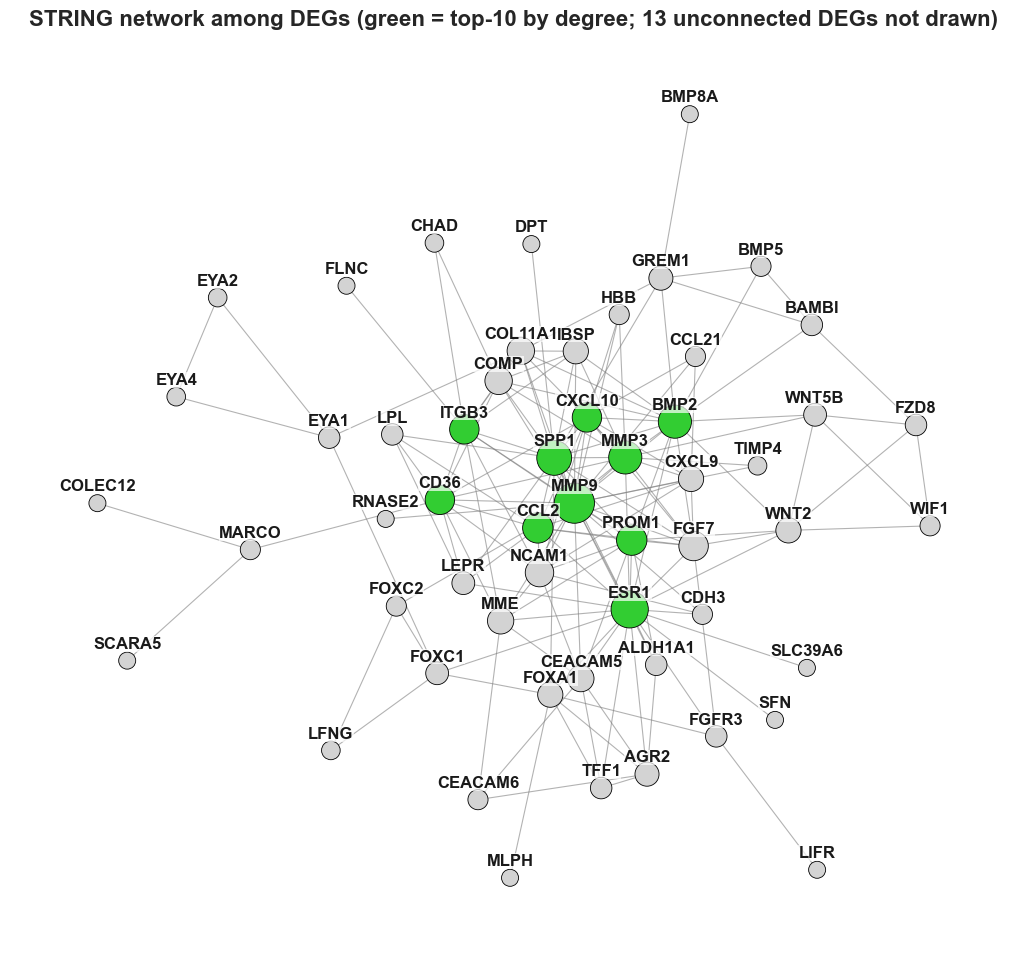

In [11]:
deg_gene_list = deg_sig.gene.tolist()
dl_ = links_hc[links_hc.sym1.isin(deg_gene_list) & links_hc.sym2.isin(deg_gene_list)]
G_deg = nx.Graph(); G_deg.add_nodes_from(deg_gene_list)
G_deg.add_edges_from(zip(dl_.sym1, dl_.sym2))
degree_rank = pd.Series(dict(G_deg.degree())).sort_values(ascending=False)
top10_hub = degree_rank.head(10)
data_driven_hub = sorted(set(top10_hub.index) & set(top20.gene))
print(f"DEG PPI network: {G_deg.number_of_nodes()} genes, {G_deg.number_of_edges()} edges")
display(top10_hub.rename("degree").reset_index().rename(columns={"index": "gene"}).T)
print("Data-driven hub shortlist (top-10 degree ∩ top-20 |logFC|):", data_driven_hub)

fig, ax = plt.subplots(figsize=(13, 12))
sub_nodes = [n for n in G_deg.nodes() if G_deg.degree(n) > 0]
H = G_deg.subgraph(sub_nodes)
pos = nx.kamada_kawai_layout(H)
nx.draw_networkx_edges(H, pos, ax=ax, edge_color="grey", width=0.8, alpha=0.6)
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=[120 + 30 * H.degree(n) for n in H.nodes()],
                       node_color=["limegreen" if n in top10_hub.index else "lightgrey" for n in H.nodes()],
                       edgecolors="black", linewidths=0.6)
nx.draw_networkx_labels(H, {n: (x, y + 0.035) for n, (x, y) in pos.items()}, ax=ax, font_size=12,
                        labels={n: n for n in H.nodes()}, font_weight="bold",
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.3))
ax.set_title(f"STRING network among DEGs (green = top-10 by degree; {len(G_deg) - len(H)} unconnected DEGs not drawn)")
ax.axis("off")
save_fig(fig, "05_DEG_PPI_network")

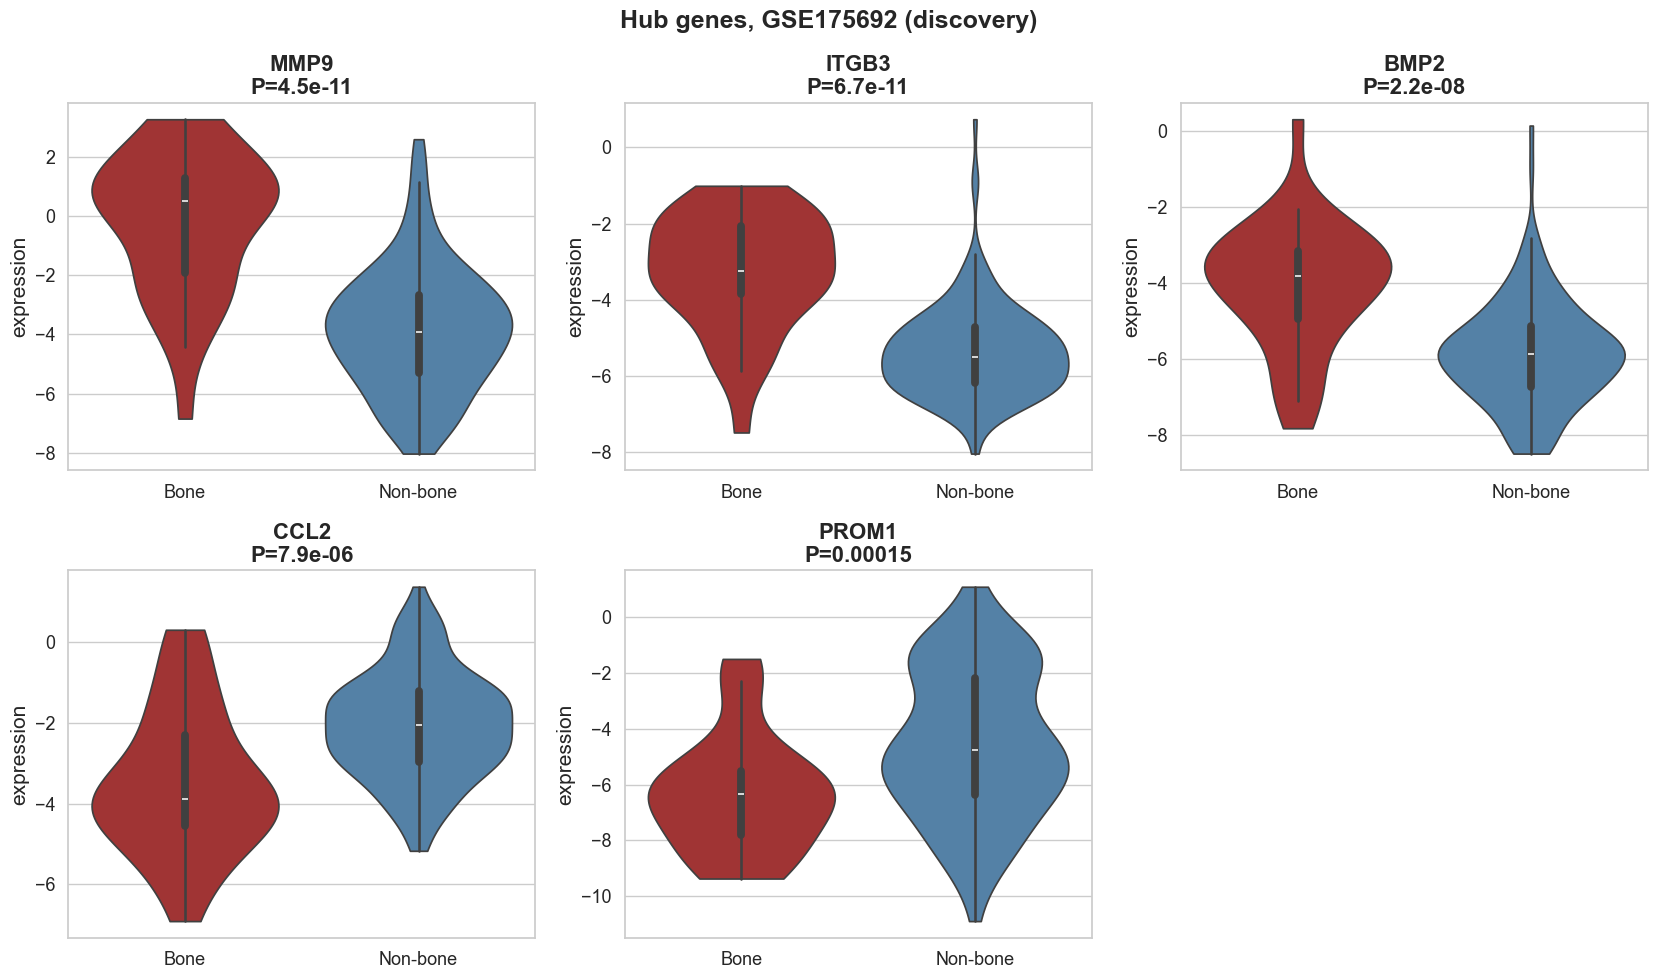

,gene,mean_Bone,mean_Non-bone,difference,MannWhitney_P,n_Bone,n_Non-bone
0,MMP9,-0.22139,-3.83130,3.60991,0.00000,33,151
1,ITGB3,-3.25303,-5.35307,2.10004,0.00000,33,151
2,BMP2,-4.06664,-5.85965,1.79301,0.00000,33,151
3,CCL2,-3.48103,-2.06126,-1.41977,0.00001,33,151
4,PROM1,-6.33609,-4.51797,-1.81812,0.00015,33,151


In [12]:
def violin_row(df, genes, group_col, order, title, fname):
    ncol = 3; nrow = int(np.ceil(len(genes) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.6 * ncol, 5.0 * nrow), squeeze=False)
    for ax in axes.ravel()[len(genes):]:
        ax.axis("off")
    rows = []
    for ax, gene in zip(axes.ravel(), genes):
        sub = df[[gene, group_col]].dropna()
        sns.violinplot(data=sub, x=group_col, y=gene, order=order, palette=["firebrick", "steelblue"],
                       inner="box", ax=ax, cut=0)
        a, b = sub.loc[sub[group_col] == order[0], gene], sub.loc[sub[group_col] == order[1], gene]
        p = mannwhitneyu(a, b, alternative="two-sided").pvalue
        ax.set_title(f"{gene}\nP={p:.2g}"); ax.set_xlabel(""); ax.set_ylabel("expression")
        rows.append((gene, a.mean(), b.mean(), a.mean() - b.mean(), p, len(a), len(b)))
    fig.suptitle(title); fig.tight_layout()
    save_fig(fig, fname)
    return pd.DataFrame(rows, columns=["gene", f"mean_{order[0]}", f"mean_{order[1]}", "difference",
                                       "MannWhitney_P", f"n_{order[0]}", f"n_{order[1]}"])

df175 = expr175.loc[HUB_GENES].T.join(bone_mask.map({True: "Bone", False: "Non-bone"}).rename("group"))
val_175 = violin_row(df175, HUB_GENES, "group", ["Bone", "Non-bone"],
                     "Hub genes, GSE175692 (discovery)", "06_hubgenes_GSE175692")
save_table(val_175, "hubgenes_GSE175692_bone_vs_nonbone")
display(val_175.round(5))

## 7. GSE14020 — bone vs non-bone replication with a platform audit

GSE14020 combines two Affymetrix platforms. Each result is shown within platform, after per-platform z-scoring, and with platform as a covariate. A gene counts as replicated only when the difference holds in the platform-adjusted model **and** points in the same direction as GSE175692.

In [13]:
GPL_ANNOT_URLS = {"GPL96": "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL96/annot/GPL96.annot.gz",
                  "GPL570": "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz"}

def load_probe_map(gpl, genes):
    path = download(GPL_ANNOT_URLS[gpl], os.path.join(DATA_DIR, gpl + ".annot.gz"))
    with gzip.open(path, "rt", encoding="latin-1") as f:
        lines = f.read().splitlines()
    s = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_begin")) + 1
    e = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_end"))
    df = pd.read_csv(io.StringIO("\n".join(lines[s:e])), sep="\t", low_memory=False)
    return {g: df.loc[df["Gene symbol"] == g, "ID"].tolist() for g in genes}

def probes_to_gene_level(expr, probe_map):
    out = {}
    for gene, probes in probe_map.items():
        probes = [p for p in probes if p in expr.index]
        if probes:
            out[gene] = expr.loc[probes].astype(float).mean(axis=0)
    return pd.DataFrame(out)

gpl96_map, gpl570_map = load_probe_map("GPL96", HUB_GENES), load_probe_map("GPL570", HUB_GENES)
expr96, clin96 = geo_data["GSE14020-GPL96"]
expr570, clin570 = geo_data["GSE14020-GPL570"]
g96, g570 = probes_to_gene_level(expr96, gpl96_map), probes_to_gene_level(expr570, gpl570_map)
gse14020_expr = pd.concat([g96, g570], axis=0)
gse14020_clin = pd.concat([clin96[["source_name"]], clin570[["source_name"]]], axis=0)
gse14020_clin["group"] = np.where(gse14020_clin.source_name == "Bone", "Bone", "Non-bone")
gse14020_clin["platform"] = ["GPL96"] * len(g96) + ["GPL570"] * len(g570)
df14020 = gse14020_expr.join(gse14020_clin[["group", "platform"]])
print("GSE14020:", df14020.group.value_counts().to_dict(), "| by platform:",
      pd.crosstab(df14020.platform, df14020.group).to_dict())

rows = []
for gene in HUB_GENES:
    d = df14020[[gene, "group", "platform"]].dropna().rename(columns={gene: "expr"})
    d["bone"] = (d.group == "Bone").astype(int)
    for plat in ["GPL96", "GPL570"]:
        dp = d[d.platform == plat]
        b, nb = dp.loc[dp.bone == 1, "expr"], dp.loc[dp.bone == 0, "expr"]
        rows.append({"gene": gene, "analysis": f"within {plat}", "n_bone": len(b), "n_nonbone": len(nb),
                     "effect": b.mean() - nb.mean(), "P": mannwhitneyu(b, nb).pvalue})
    fit = smf.ols("expr ~ bone + C(platform)", data=d).fit()
    rows.append({"gene": gene, "analysis": "OLS expr ~ bone + platform", "n_bone": int(d.bone.sum()),
                 "n_nonbone": int((1 - d.bone).sum()), "effect": fit.params["bone"], "P": fit.pvalues["bone"]})
gse14020_audit = pd.DataFrame(rows)
adj_ = gse14020_audit.analysis.str.startswith("OLS")
gse14020_audit.loc[adj_, "FDR_across_5_genes"] = bh(gse14020_audit.loc[adj_, "P"])
disc_dir = val_175.set_index("gene")["difference"].apply(np.sign)
gse14020_audit["direction_matches_GSE175692"] = [np.sign(r.effect) == disc_dir[r.gene] for r in gse14020_audit.itertuples()]
save_table(gse14020_audit, "GSE14020_platform_adjusted_bone_vs_nonbone")
display(gse14020_audit.round(5))
rep_ = gse14020_audit[adj_]
REPLICATED_14020 = rep_[(rep_.FDR_across_5_genes < 0.05) & rep_.direction_matches_GSE175692].gene.tolist()
print("Replicated in GSE14020 (platform-adjusted FDR<0.05, same direction as discovery):", REPLICATED_14020)

GSE14020: {'Non-bone': 47, 'Bone': 18} | by platform: {'Bone': {'GPL570': 10, 'GPL96': 8}, 'Non-bone': {'GPL570': 19, 'GPL96': 28}}


,gene,analysis,n_bone,n_nonbone,effect,P,FDR_across_5_genes,direction_matches_GSE175692
0,MMP9,within GPL96,8,28,2.63453,0.00033,NaN,True
1,MMP9,within GPL570,10,19,3.13448,0.00032,NaN,True
2,MMP9,OLS expr ~ bone + platform,18,47,2.89095,0.00000,0.00000,True
3,ITGB3,within GPL96,8,28,0.18902,0.02138,NaN,True
4,ITGB3,within GPL570,10,19,0.25750,0.00053,NaN,True
5,ITGB3,OLS expr ~ bone + platform,18,47,0.22414,0.00000,0.00000,True
6,BMP2,within GPL96,8,28,0.80663,0.04863,NaN,True
7,BMP2,within GPL570,10,19,2.17470,0.00143,NaN,True
8,BMP2,OLS expr ~ bone + platform,18,47,1.50831,0.00002,0.00003,True
9,CCL2,within GPL96,8,28,-0.20801,0.37849,NaN,True


Replicated in GSE14020 (platform-adjusted FDR<0.05, same direction as discovery): ['MMP9', 'ITGB3', 'BMP2', 'PROM1']


## 8. Survival analyses (reviewer comment 6)

The comment asks to separate **univariate** from **adjusted** associations and to verify every sample count. The sections below do that and end in one consolidated evidence table (8g) that labels each row univariate or adjusted.

### 8a. Cohort flow: one table with every survival cohort and every excluded sample

In [14]:
surv175 = clin175[["ose", "os (months) since dxmet"]].copy()
surv175.columns = ["event", "time_months"]
surv175 = surv175.apply(pd.to_numeric, errors="coerce")
clin_cox = clin175.copy()
for c in ["hr", "her2"]:
    clin_cox[c] = clin_cox[c].astype(str).str.strip().str.upper().replace({"NA": np.nan, "NAN": np.nan, "": np.nan})

surv_df = surv175.join(expr175.loc[HUB_GENES].T).dropna()
cox_base = surv175.join(expr175.loc[HUB_GENES].T).join(clin_cox[["organ", "hr", "her2"]])
flow = [("All GSE175692 samples", len(cox_base), int(np.nansum(cox_base.event)))]
cox_base = cox_base.dropna(subset=["time_months", "event"])
flow.append(("With survival time and status", len(cox_base), int(cox_base.event.sum())))
cox_base = cox_base.dropna(subset=HUB_GENES)
flow.append(("With hub-gene expression  (= univariate cohort, 8b)", len(cox_base), int(cox_base.event.sum())))
cox_base = cox_base.dropna(subset=["hr", "her2", "organ"])
flow.append(("With known HR and HER2  (= adjusted cohort, 8c)", len(cox_base), int(cox_base.event.sum())))
cox_base["bone_met"] = (cox_base.organ == "Bone").astype(int)
cox_base["hr_pos"] = (cox_base.hr == "POS").astype(int)
cox_base["her2_pos"] = (cox_base.her2 == "POS").astype(int)
t2_ = surv175.reindex(TASK_INFO["survival_outcome"]["ids"])
flow.append(("Task 2 landmark label (Graph-CNN; censored <=36 mo excluded)", len(t2_), int(t2_.event.sum())))
cox_flow = pd.DataFrame(flow, columns=["step", "n_samples", "n_events"])
save_table(cox_flow, "survival_cohort_flow")
display(cox_flow)

ex = pd.DataFrame(index=clin175.index)
ex["has_time_and_event"] = surv175[["time_months", "event"]].notna().all(axis=1)
ex["has_HR_HER2"] = clin_cox.hr.notna() & clin_cox.her2.notna()
ex["in_univariate"] = ex.index.isin(surv_df.index)
ex["in_adjusted"] = ex.index.isin(cox_base.index)
ex["in_task2"] = ex.index.isin(TASK_INFO["survival_outcome"]["ids"])
def _why(r):
    out = []
    if not r.has_time_and_event: out.append("missing survival time/status")
    if not r.has_HR_HER2: out.append("HR or HER2 unknown")
    if r.has_time_and_event and not r.in_task2: out.append("censored at/before 36 months (Task 2 only)")
    return "; ".join(out)
ex["exclusion_reasons"] = ex.apply(_why, axis=1)
save_table(ex.reset_index().rename(columns={"index": "sample_id"}), "survival_sample_exclusions")
print("Samples excluded from at least one survival analysis, by reason:")
display(ex[ex.exclusion_reasons != ""].exclusion_reasons.value_counts().rename("n_samples").to_frame())
checks = pd.DataFrame([
    ("event coded 0/1 only", set(surv175.event.dropna().unique()) <= {0, 1}),
    ("no non-positive survival times", bool((surv175.time_months.dropna() > 0).all())),
    ("max follow-up plausible for months (<360)", bool(surv175.time_months.max() < 360)),
    ("Task 2 cases = deaths <=36 mo in OS data",
     int(((t2_.event == 1) & (t2_.time_months <= 36)).sum()) == int(TASK_INFO["survival_outcome"]["y"].sum())),
], columns=["check", "passed"])
save_table(checks, "survival_data_checks")
display(checks)

,step,n_samples,n_events
0,All GSE175692 samples,184,104
1,With survival time and status,180,104
2,"With hub-gene expression (= univariate cohort, 8b)",180,104
3,"With known HR and HER2 (= adjusted cohort, 8c)",167,93
4,Task 2 landmark label (Graph-CNN; censored <=36 mo excluded),152,104


Samples excluded from at least one survival analysis, by reason:


,n_samples
exclusion_reasons,
censored at/before 36 months (Task 2 only),27
HR or HER2 unknown,12
missing survival time/status,4
HR or HER2 unknown; censored at/before 36 months (Task 2 only),1


,check,passed
0,event coded 0/1 only,True
1,no non-positive survival times,True
2,max follow-up plausible for months (<360),True
3,Task 2 cases = deaths <=36 mo in OS data,True


### 8b. Univariate Cox and Kaplan–Meier (GSE175692, overall survival from metastatic diagnosis)

,gene,n,events,HR_per_unit,CI_lower,CI_upper,P,FDR_5genes
0,MMP9,180,104,1.0431,0.9679,1.1242,0.2688,0.3360
1,ITGB3,180,104,0.9579,0.8266,1.1102,0.5681,0.5681
2,BMP2,180,104,0.9227,0.8041,1.0588,0.2518,0.3360
3,CCL2,180,104,1.2001,1.0507,1.3707,0.0072,0.0179
4,PROM1,180,104,1.1150,1.0332,1.2034,0.0051,0.0179


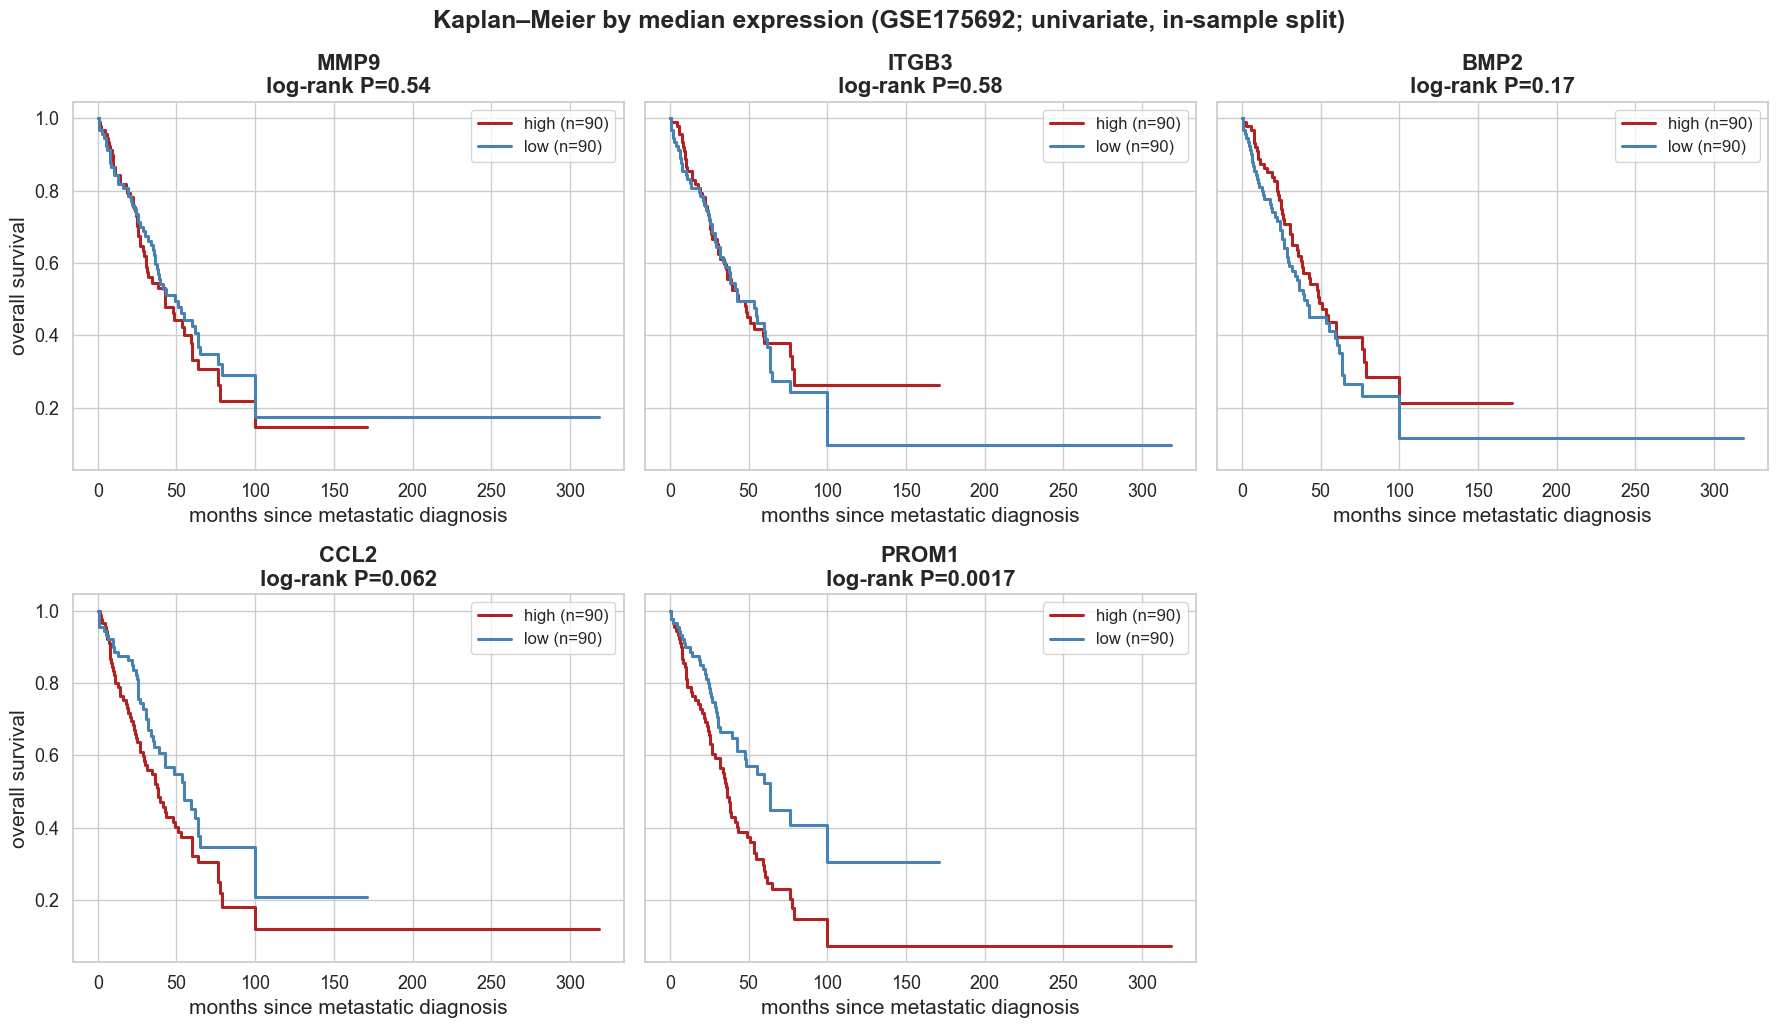

In [15]:
def cox_one(df, cols, strata=None):
    cph = CoxPHFitter().fit(df[["time_months", "event"] + cols + ([strata] if strata else [])],
                            duration_col="time_months", event_col="event", strata=[strata] if strata else None)
    return cph

uni_rows = []
for gene in HUB_GENES:
    s = cox_one(surv_df, [gene]).summary.loc[gene]
    uni_rows.append({"gene": gene, "n": len(surv_df), "events": int(surv_df.event.sum()), "HR_per_unit": s["exp(coef)"],
                     "CI_lower": s["exp(coef) lower 95%"], "CI_upper": s["exp(coef) upper 95%"], "P": s["p"]})
cox_uni = pd.DataFrame(uni_rows)
cox_uni["FDR_5genes"] = bh(cox_uni.P)
save_table(cox_uni, "cox_univariate_GSE175692")
display(cox_uni.round(4))

fig, axes = plt.subplots(2, 3, figsize=(18, 10.5), sharey=True)
axes[1, 2].axis("off")
km_rows = []
for ax, gene in zip(axes.ravel(), HUB_GENES):
    med = surv_df[gene].median()
    hi, lo = surv_df[surv_df[gene] > med], surv_df[surv_df[gene] <= med]
    KaplanMeierFitter().fit(hi.time_months, hi.event, label=f"high (n={len(hi)})").plot_survival_function(ax=ax, ci_show=False, color="firebrick")
    KaplanMeierFitter().fit(lo.time_months, lo.event, label=f"low (n={len(lo)})").plot_survival_function(ax=ax, ci_show=False, color="steelblue")
    p = logrank_test(hi.time_months, lo.time_months, hi.event, lo.event).p_value
    km_rows.append({"gene": gene, "logrank_P_median_split": p})
    ax.set_title(f"{gene}\nlog-rank P={p:.2g}"); ax.set_xlabel("months since metastatic diagnosis")
    ax.set_ylabel("overall survival"); ax.legend(loc="upper right")
fig.suptitle("Kaplan–Meier by median expression (GSE175692; univariate, in-sample split)")
fig.tight_layout()
save_fig(fig, "07_KM_hubgenes_GSE175692")
km_table = save_table(pd.DataFrame(km_rows), "km_logrank_GSE175692")

### 8c. Adjusted associations

* **Per-gene adjusted model:** gene + HR status + HER2 status + bone site, fitted separately for each hub gene. It is directly comparable with 8b.
* **M1:** PROM1 + CCL2 + bone site + HR + HER2 (the v14 specification).
* **M2:** M1 stratified by HR status, because HR status violates proportional hazards.
* **M3:** M2 plus CCL2 × log(time).

The cell also tests whether PROM1 and CCL2 differ by HR status. If they do, HR status is a confounder, which explains why a univariate association can disappear after adjustment.

Per-gene adjusted Cox (gene + HR + HER2 + bone site), with the univariate HR on the same cohort:


,gene,n,events,HR_per_unit,CI_lower,CI_upper,P,FDR_5genes,HR_univariate_same_cohort,P_univariate_same_cohort
0,MMP9,167,93,1.0638,0.9541,1.1860,0.2653,0.4796,1.0503,0.2198
1,ITGB3,167,93,0.9735,0.7940,1.1937,0.7964,0.8309,0.9602,0.6083
2,BMP2,167,93,0.9228,0.7957,1.0702,0.2878,0.4796,0.9204,0.2623
3,CCL2,167,93,1.0187,0.8597,1.2070,0.8309,0.8309,1.2448,0.0022
4,PROM1,167,93,0.9419,0.8477,1.0466,0.2660,0.4796,1.1082,0.0113


,model,covariate,HR,CI_lower,CI_upper,P
0,M1 standard,PROM1,0.9376,0.8423,1.0437,0.2390
1,M1 standard,CCL2,1.0399,0.8736,1.2378,0.6600
2,M1 standard,bone_met,0.7779,0.3948,1.5329,0.4681
3,M1 standard,hr_pos,0.2540,0.1478,0.4365,0.0000
4,M1 standard,her2_pos,1.0852,0.5829,2.0205,0.7965
5,M2 HR-stratified,PROM1,0.9428,0.8466,1.0499,0.2830
6,M2 HR-stratified,CCL2,1.0370,0.8746,1.2295,0.6762
7,M2 HR-stratified,bone_met,0.8153,0.4127,1.6107,0.5566
8,M2 HR-stratified,her2_pos,1.1351,0.6078,2.1201,0.6909
9,M3 HR-stratified + CCL2 x log(t),PROM1,0.9432,0.8479,1.0493,0.2824


model,M1,M2
covariate,,
CCL2,0.1845,0.1066
PROM1,0.6103,0.7108
bone_met,0.3044,0.2362
her2_pos,0.7619,0.0128
hr_pos,0.0339,NaN


,gene,median_HR_pos,median_HR_neg,MannWhitney_P
0,PROM1,-6.06062,-2.50441,0.0
1,CCL2,-2.77138,-1.47799,0.0


HR-positive vs HR-negative (M1): HR=0.25 (95% CI 0.15-0.44), P=7e-07


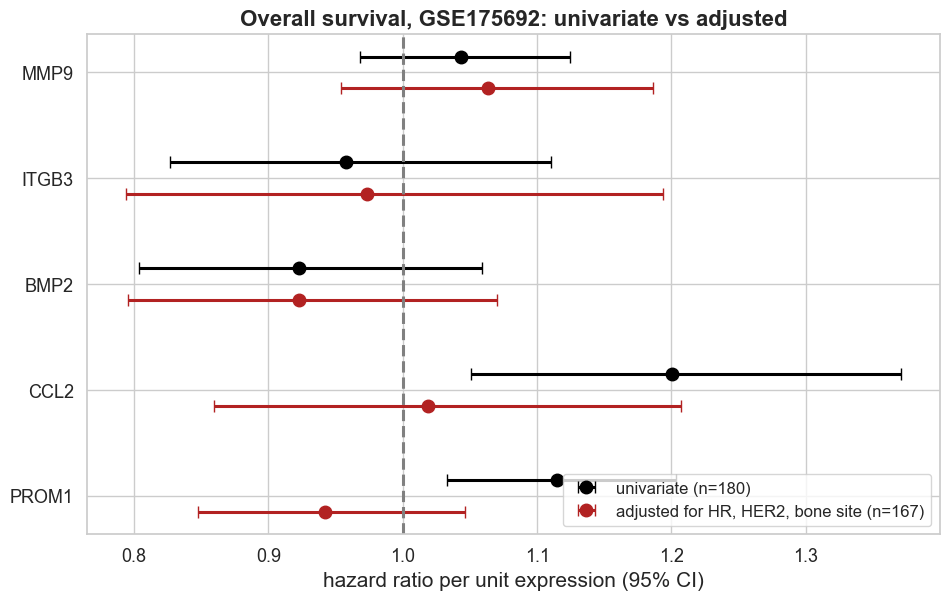

In [16]:
adj_rows = []
for gene in HUB_GENES:
    s = cox_one(cox_base, [gene, "hr_pos", "her2_pos", "bone_met"]).summary.loc[gene]
    adj_rows.append({"gene": gene, "n": len(cox_base), "events": int(cox_base.event.sum()), "HR_per_unit": s["exp(coef)"],
                     "CI_lower": s["exp(coef) lower 95%"], "CI_upper": s["exp(coef) upper 95%"], "P": s["p"]})
cox_adj_pergene = pd.DataFrame(adj_rows)
cox_adj_pergene["FDR_5genes"] = bh(cox_adj_pergene.P)
# univariate refit on the SAME 167-sample adjusted cohort, so the attenuation is not a cohort difference
uni_same = []
for gene in HUB_GENES:
    s = cox_one(cox_base, [gene]).summary.loc[gene]
    uni_same.append({"gene": gene, "HR_univariate_same_cohort": s["exp(coef)"], "P_univariate_same_cohort": s["p"]})
cox_adj_pergene = cox_adj_pergene.merge(pd.DataFrame(uni_same), on="gene")
save_table(cox_adj_pergene, "cox_adjusted_per_gene_GSE175692")
print("Per-gene adjusted Cox (gene + HR + HER2 + bone site), with the univariate HR on the same cohort:")
display(cox_adj_pergene.round(4))

def full_table(cph, label):
    s = cph.summary
    return pd.DataFrame({"model": label, "covariate": s.index, "HR": s["exp(coef)"], "CI_lower": s["exp(coef) lower 95%"],
                         "CI_upper": s["exp(coef) upper 95%"], "P": s["p"]}).reset_index(drop=True)
covars = ["PROM1", "CCL2", "bone_met", "hr_pos", "her2_pos"]
cph_m1 = cox_one(cox_base, covars)
cph_m2 = CoxPHFitter().fit(cox_base[["time_months", "event"] + covars], duration_col="time_months",
                           event_col="event", strata=["hr_pos"])
ep = to_episodic_format(cox_base[["time_months", "event"] + covars].reset_index(drop=True),
                        duration_col="time_months", event_col="event", time_gaps=1.0)
ep["CCL2_x_logt"] = ep["CCL2"] * np.log(ep["stop"])
ctv = CoxTimeVaryingFitter().fit(ep[["id", "start", "stop", "event", "PROM1", "CCL2", "CCL2_x_logt", "bone_met",
                                      "her2_pos", "hr_pos"]], id_col="id", start_col="start", stop_col="stop",
                                  event_col="event", strata=["hr_pos"])
cox_multi = pd.concat([full_table(cph_m1, "M1 standard"), full_table(cph_m2, "M2 HR-stratified"),
                       full_table(ctv, "M3 HR-stratified + CCL2 x log(t)")], ignore_index=True)
save_table(cox_multi, "cox_multivariable_M1_M2_M3")
display(cox_multi.round(4))

data_ph = cox_base[["time_months", "event"] + covars]
ph_rows = []
for label, cph in [("M1", CoxPHFitter().fit(data_ph, "time_months", "event")),
                   ("M2", CoxPHFitter().fit(data_ph, "time_months", "event", strata=["hr_pos"]))]:
    res = proportional_hazard_test(cph, data_ph, time_transform="rank")
    for cov, r in res.summary.iterrows():
        ph_rows.append({"model": label, "covariate": cov if isinstance(cov, str) else cov[0], "PH_test_P": r["p"]})
ph_table = save_table(pd.DataFrame(ph_rows), "cox_PH_tests")
display(ph_table.pivot(index="covariate", columns="model", values="PH_test_P").round(4))

conf_rows = []
for gene in ["PROM1", "CCL2"]:
    a, b = cox_base.loc[cox_base.hr_pos == 1, gene], cox_base.loc[cox_base.hr_pos == 0, gene]
    conf_rows.append({"gene": gene, "median_HR_pos": a.median(), "median_HR_neg": b.median(),
                      "MannWhitney_P": mannwhitneyu(a, b).pvalue})
hr_confounding = save_table(pd.DataFrame(conf_rows), "PROM1_CCL2_by_HR_status")
display(hr_confounding.round(5))
hr_row = cox_multi[(cox_multi.model == "M1 standard") & (cox_multi.covariate == "hr_pos")].iloc[0]
print(f"HR-positive vs HR-negative (M1): HR={hr_row.HR:.2f} (95% CI {hr_row.CI_lower:.2f}-{hr_row.CI_upper:.2f}), P={hr_row.P:.2g}")

# Forest plot: univariate vs adjusted, same genes
fig, ax = plt.subplots(figsize=(11, 6.5))
ypos = np.arange(len(HUB_GENES))
for off, df_, col, lab in [(-0.15, cox_uni, "black", f"univariate (n={len(surv_df)})"),
                           (0.15, cox_adj_pergene, "firebrick", f"adjusted for HR, HER2, bone site (n={len(cox_base)})")]:
    d_ = df_.set_index("gene").loc[HUB_GENES]
    ax.errorbar(d_.HR_per_unit, ypos + off, xerr=[d_.HR_per_unit - d_.CI_lower, d_.CI_upper - d_.HR_per_unit],
                fmt="o", color=col, capsize=4, label=lab, markersize=9)
ax.axvline(1, color="grey", ls="--")
ax.set_yticks(ypos); ax.set_yticklabels(HUB_GENES); ax.invert_yaxis()
ax.set_xlabel("hazard ratio per unit expression (95% CI)")
ax.set_title("Overall survival, GSE175692: univariate vs adjusted")
ax.legend(loc="lower right")
save_fig(fig, "08_forest_univariate_vs_adjusted")

### 8d. PROM1 + CCL2 risk score: apparent vs cross-validated, then frozen external application

The v14 Section 7 risk score was fitted and evaluated on the same samples, so its numbers are **apparent** (optimistic). Here the whole recipe is cross-validated: standardize, fit Cox, then split at the training median. The frozen coefficients are then applied, without refitting, to the external cohorts after z-scoring within each cohort.

In [17]:
RS_GENES, RS_HORIZON, N_RS_REPEATS, N_RS_FOLDS = ["PROM1", "CCL2"], 36, 20, 5
rs_data = surv_df[["time_months", "event"] + RS_GENES].copy()

def fixed_horizon_auc(df, score, horizon):
    cases = (df.event == 1) & (df.time_months <= horizon)
    ctrls = df.time_months > horizon
    keep = cases | ctrls
    y_ = cases[keep].astype(int)
    return roc_auc_score(y_, score[keep]) if y_.nunique() == 2 else np.nan

def fit_rs(train):
    mu, sd = train[RS_GENES].mean(), train[RS_GENES].std(ddof=0)
    z = (train[RS_GENES] - mu) / sd
    beta = CoxPHFitter().fit(pd.concat([train[["time_months", "event"]], z], axis=1), "time_months", "event").params_[RS_GENES]
    return mu, sd, beta

mu_all, sd_all, beta_all = fit_rs(rs_data)
lp_all = ((rs_data[RS_GENES] - mu_all) / sd_all) @ beta_all
hi_ = lp_all > lp_all.median()
apparent = {"C_index": concordance_index(rs_data.time_months, -lp_all, rs_data.event),
            "AUC_36mo": fixed_horizon_auc(rs_data, lp_all, RS_HORIZON),
            "logrank_P": logrank_test(rs_data.time_months[hi_], rs_data.time_months[~hi_],
                                      rs_data.event[hi_], rs_data.event[~hi_]).p_value}
cv_rows = []
for rep in range(N_RS_REPEATS):
    oof_lp = pd.Series(np.nan, index=rs_data.index); oof_hi = pd.Series(False, index=rs_data.index)
    for tr_i, te_i in StratifiedKFold(N_RS_FOLDS, shuffle=True, random_state=rep).split(rs_data, rs_data.event.astype(int)):
        tr_d, te_d = rs_data.iloc[tr_i], rs_data.iloc[te_i]
        mu, sd, beta = fit_rs(tr_d)
        lp_te = ((te_d[RS_GENES] - mu) / sd) @ beta
        cut = (((tr_d[RS_GENES] - mu) / sd) @ beta).median()
        oof_lp[te_d.index] = lp_te; oof_hi[te_d.index] = lp_te > cut
    cv_rows.append({"repeat": rep, "C_index": concordance_index(rs_data.time_months, -oof_lp, rs_data.event),
                    "AUC_36mo": fixed_horizon_auc(rs_data, oof_lp, RS_HORIZON),
                    "logrank_P": logrank_test(rs_data.time_months[oof_hi], rs_data.time_months[~oof_hi],
                                              rs_data.event[oof_hi], rs_data.event[~oof_hi]).p_value})
rs_cv = pd.DataFrame(cv_rows)
rs_compare = pd.DataFrame([{"metric": m, "apparent": apparent[m], "cross_validated_median": rs_cv[m].median(),
                            "cv_min": rs_cv[m].min(), "cv_max": rs_cv[m].max()} for m in ["C_index", "AUC_36mo", "logrank_P"]])
save_table(rs_compare, "risk_score_apparent_vs_crossvalidated")
print(f"Risk score on n={len(rs_data)} ({int(rs_data.event.sum())} events), {N_RS_REPEATS}x{N_RS_FOLDS}-fold CV:")
display(rs_compare.round(4))

Risk score on n=180 (104 events), 20x5-fold CV:


,metric,apparent,cross_validated_median,cv_min,cv_max
0,C_index,0.5929,0.5780,0.5308,0.5925
1,AUC_36mo,0.5797,0.5616,0.5012,0.5823
2,logrank_P,0.0051,0.0178,0.0010,0.0889


### 8e. Complementary survival cohorts: univariate and adjusted

* **GSE124647** — metastatic, ER-positive trial biopsies; endpoint OS. Adjusted for the clinical covariates deposited in GEO when they are present: PR status, visceral disease, stage IV at initial diagnosis.
* **GSE11121** — node-negative, untreated **primary** tumors; endpoint DMFS, a different endpoint in a different population. Adjusted for grade and tumor size.

Expression is used on the log2 scale throughout. v14 had a reporting error here: its GSE11121 summary row came from a Cox model on raw intensities (HR 1.000, CI 1.000–1.000, P = 1.8e-4) instead of the log2 model. Only the log2 model is reported below.

In [18]:
expr124, clin124 = geo_data["GSE124647"]
expr11121, clin11121 = geo_data["GSE11121"]
gene124 = probes_to_gene_level(expr124, gpl96_map)
gene11121 = probes_to_gene_level(expr11121, gpl96_map)

def to_log2(df):
    return df if np.nanmax(df.values) < 30 else np.log2(df.clip(lower=0) + 1)

def num(s):
    return pd.to_numeric(s.astype(str).str.strip().replace({"NA": np.nan, "": np.nan}), errors="coerce")

surv124 = pd.DataFrame({"event": num(clin124["os event"]), "time_months": num(clin124["oas months"])})
cov124 = pd.DataFrame(index=clin124.index)
for col, new in [("pr status", "pr_pos"), ("visceral disease", "visceral"), ("stage iv at initial diagnosis", "stage4_dx")]:
    if col in clin124.columns:
        cov124[new] = num(clin124[col])
surv11121 = pd.DataFrame({"event": num(clin11121["e.dmfs"]), "time_months": num(clin11121["t.dmfs"])})
cov11121 = pd.DataFrame({"grade": num(clin11121["grade"]), "size_cm": num(clin11121["size_in_cm"])}, index=clin11121.index)

ext_cohorts = {
    "GSE124647": dict(expr=to_log2(gene124), surv=surv124, cov=cov124, endpoint="OS",
                      population="metastatic ER+ trial biopsies"),
    "GSE11121": dict(expr=to_log2(gene11121), surv=surv11121, cov=cov11121, endpoint="DMFS",
                     population="node-negative untreated primary tumors"),
}
ext_rows, ext_scale_note = [], []
for cohort, c in ext_cohorts.items():
    for gene in ["PROM1", "CCL2"]:
        if gene not in c["expr"].columns:
            continue
        d = c["surv"].join(c["expr"][[gene]]).join(c["cov"]).dropna(subset=["time_months", "event", gene])
        s = cox_one(d, [gene]).summary.loc[gene]
        hi_ = d[gene] > d[gene].median()
        lr = logrank_test(d.time_months[hi_], d.time_months[~hi_], d.event[hi_], d.event[~hi_]).p_value
        ext_rows.append({"cohort": cohort, "endpoint": c["endpoint"], "population": c["population"], "gene": gene,
                         "analysis": "univariate", "covariates": "-", "n": len(d), "events": int(d.event.sum()),
                         "HR_per_log2_unit": s["exp(coef)"], "CI_lower": s["exp(coef) lower 95%"],
                         "CI_upper": s["exp(coef) upper 95%"], "P": s["p"], "median_split_logrank_P": lr})
        covs = [k for k in c["cov"].columns if d[k].notna().sum() > 0.8 * len(d) and d[k].nunique() > 1]
        da = d.dropna(subset=covs)
        if covs and da.event.sum() >= 10:
            try:
                s = cox_one(da, [gene] + covs).summary.loc[gene]
                ext_rows.append({"cohort": cohort, "endpoint": c["endpoint"], "population": c["population"], "gene": gene,
                                 "analysis": "adjusted", "covariates": ", ".join(covs), "n": len(da),
                                 "events": int(da.event.sum()), "HR_per_log2_unit": s["exp(coef)"],
                                 "CI_lower": s["exp(coef) lower 95%"], "CI_upper": s["exp(coef) upper 95%"],
                                 "P": s["p"], "median_split_logrank_P": np.nan})
            except Exception as e:
                print(f"{cohort}/{gene}: adjusted model failed ({e})")
external_survival = pd.DataFrame(ext_rows)
for (coh, an), idx in external_survival.groupby(["cohort", "analysis"]).groups.items():
    external_survival.loc[idx, "FDR_within_cohort"] = bh(external_survival.loc[idx, "P"])
save_table(external_survival, "external_cohorts_cox_univariate_and_adjusted")
display(external_survival.drop(columns=["population"]).round(4))

# frozen risk score in the external cohorts (z-scored within cohort, betas fixed)
frz_rows = []
for cohort, c in ext_cohorts.items():
    d = c["surv"].join(c["expr"].reindex(columns=RS_GENES)).dropna()
    lp = ((d[RS_GENES] - d[RS_GENES].mean()) / d[RS_GENES].std(ddof=0)) @ beta_all
    rng_ = np.random.default_rng(0); boots = []
    for _ in range(1000):
        i = rng_.integers(0, len(d), len(d))
        if d.event.iloc[i].sum() > 0:
            boots.append(concordance_index(d.time_months.iloc[i], -lp.iloc[i], d.event.iloc[i]))
    s = CoxPHFitter().fit(d[["time_months", "event"]].assign(rs_z=(lp - lp.mean()) / lp.std()), "time_months", "event").summary.loc["rs_z"]
    frz_rows.append({"cohort": cohort, "endpoint": c["endpoint"], "n": len(d), "events": int(d.event.sum()),
                     "C_index": concordance_index(d.time_months, -lp, d.event),
                     "C_CI_lower": np.percentile(boots, 2.5), "C_CI_upper": np.percentile(boots, 97.5),
                     "HR_per_SD": s["exp(coef)"], "HR_CI_lower": s["exp(coef) lower 95%"],
                     "HR_CI_upper": s["exp(coef) upper 95%"], "P": s["p"]})
risk_score_external = save_table(pd.DataFrame(frz_rows), "risk_score_frozen_external")
display(risk_score_external.round(4))

,cohort,endpoint,gene,analysis,covariates,n,events,HR_per_log2_unit,CI_lower,CI_upper,P,median_split_logrank_P,FDR_within_cohort
0,GSE124647,OS,PROM1,univariate,-,140,97,1.1613,1.0176,1.3254,0.0265,0.5396,0.0531
1,GSE124647,OS,PROM1,adjusted,"pr_pos, visceral, stage4_dx",140,97,1.2010,1.0456,1.3796,0.0096,NaN,0.0192
2,GSE124647,OS,CCL2,univariate,-,140,97,1.0734,0.9715,1.1859,0.1638,0.1944,0.1638
3,GSE124647,OS,CCL2,adjusted,"pr_pos, visceral, stage4_dx",140,97,1.1128,1.0041,1.2333,0.0415,NaN,0.0415
4,GSE11121,DMFS,PROM1,univariate,-,200,46,1.1811,1.0042,1.3891,0.0443,0.1794,0.0886
5,GSE11121,DMFS,PROM1,adjusted,"grade, size_cm",200,46,1.1192,0.9503,1.3181,0.1773,NaN,0.3547
6,GSE11121,DMFS,CCL2,univariate,-,200,46,1.0567,0.8318,1.3425,0.6514,0.6592,0.6514
7,GSE11121,DMFS,CCL2,adjusted,"grade, size_cm",200,46,1.0427,0.8195,1.3267,0.7335,NaN,0.7335


,cohort,endpoint,n,events,C_index,C_CI_lower,C_CI_upper,HR_per_SD,HR_CI_lower,HR_CI_upper,P
0,GSE124647,OS,140,97,0.5609,0.4984,0.6350,1.3521,1.0880,1.6803,0.0065
1,GSE11121,DMFS,200,46,0.5703,0.4651,0.6752,1.2989,0.9523,1.7715,0.0986


### 8f. Within-bone-metastasis survival screen (exploratory)

A Cox model is fitted per gene within the bone-metastasis subgroup only. The subgroup has few events, so these results generate hypotheses and are not reported as findings. The FDR column shows whether anything survives multiple testing.

In [19]:
bm_ids = clin175.index[bone_mask]
surv_bm = surv175.reindex(bm_ids)
bm_rows = []
for gene in gene_list:
    d = surv_bm.join(expr175.loc[gene, bm_ids].rename("g")).dropna()
    if len(d) < 15 or d.event.sum() < 5:
        continue
    try:
        s = CoxPHFitter().fit(d, "time_months", "event").summary.loc["g"]
        bm_rows.append((gene, s["exp(coef)"], s["p"], len(d), int(d.event.sum())))
    except Exception:
        pass
within_bone_cox = pd.DataFrame(bm_rows, columns=["gene", "HR", "P", "n", "events"])
within_bone_cox["FDR"] = bh(within_bone_cox.P)
within_bone_cox = within_bone_cox.sort_values("P")
save_table(within_bone_cox, "within_bonemet_cox_screen")
print(f"Within-bone screen: n={within_bone_cox.n.iloc[0]} samples, {within_bone_cox.events.iloc[0]} events; "
      f"genes with FDR<0.05: {int((within_bone_cox.FDR < 0.05).sum())}; smallest FDR={within_bone_cox.FDR.min():.3f}")
display(within_bone_cox.head(10).round(4))

Within-bone screen: n=31 samples, 11 events; genes with FDR<0.05: 0; smallest FDR=0.754


,gene,HR,P,n,events,FDR
531,PLA2G3,0.3228,0.0010,31,11,0.7540
667,TCF4,3.8466,0.0125,31,11,0.9152
181,DCN,3.1580,0.0197,31,11,0.9152
37,BAMBI,1.8641,0.0202,31,11,0.9152
628,SMAD1,4.1398,0.0246,31,11,0.9152
647,SPN,0.5097,0.0250,31,11,0.9152
249,FGFR4,1.5748,0.0261,31,11,0.9152
26,ASPN,1.8727,0.0267,31,11,0.9152
65,CA12,0.7341,0.0276,31,11,0.9152
475,NOD2,0.4721,0.0287,31,11,0.9152


### 8g. Consolidated survival evidence table and generated interpretation

This is the single table the manuscript's survival paragraph should be written from. Each row states the analysis type (univariate / adjusted / apparent / cross-validated / frozen-external), the cohort, the endpoint, n and events.

In [20]:
ev_rows = []
for r in cox_uni.itertuples():
    ev_rows.append(dict(cohort="GSE175692", endpoint="OS", analysis="univariate", term=r.gene, n=r.n, events=r.events,
                        estimate=f"HR {r.HR_per_unit:.2f} ({r.CI_lower:.2f}-{r.CI_upper:.2f})", P=r.P, FDR=r.FDR_5genes))
for r in cox_adj_pergene.itertuples():
    ev_rows.append(dict(cohort="GSE175692", endpoint="OS", analysis="adjusted (HR, HER2, bone site)", term=r.gene, n=r.n,
                        events=r.events, estimate=f"HR {r.HR_per_unit:.2f} ({r.CI_lower:.2f}-{r.CI_upper:.2f})",
                        P=r.P, FDR=r.FDR_5genes))
for r in cox_multi[cox_multi.covariate.isin(["PROM1", "CCL2", "CCL2_x_logt"])].itertuples():
    ev_rows.append(dict(cohort="GSE175692", endpoint="OS", analysis=f"adjusted, {r.model}", term=r.covariate,
                        n=len(cox_base), events=int(cox_base.event.sum()),
                        estimate=f"HR {r.HR:.2f} ({r.CI_lower:.2f}-{r.CI_upper:.2f})", P=r.P, FDR=np.nan))
for m in ["C_index", "AUC_36mo"]:
    rr = rs_compare.set_index("metric").loc[m]
    ev_rows.append(dict(cohort="GSE175692", endpoint="OS", analysis="risk score, apparent (in-sample)", term=m,
                        n=len(rs_data), events=int(rs_data.event.sum()), estimate=f"{rr.apparent:.3f}", P=np.nan, FDR=np.nan))
    ev_rows.append(dict(cohort="GSE175692", endpoint="OS", analysis=f"risk score, {N_RS_REPEATS}x{N_RS_FOLDS} CV", term=m,
                        n=len(rs_data), events=int(rs_data.event.sum()),
                        estimate=f"{rr.cross_validated_median:.3f} (range {rr.cv_min:.3f}-{rr.cv_max:.3f})", P=np.nan, FDR=np.nan))
for r in external_survival.itertuples():
    ev_rows.append(dict(cohort=r.cohort, endpoint=r.endpoint, analysis=r.analysis + ("" if r.analysis == "univariate" else f" ({r.covariates})"),
                        term=r.gene, n=r.n, events=r.events,
                        estimate=f"HR/log2 {r.HR_per_log2_unit:.2f} ({r.CI_lower:.2f}-{r.CI_upper:.2f})", P=r.P, FDR=r.FDR_within_cohort))
for r in risk_score_external.itertuples():
    ev_rows.append(dict(cohort=r.cohort, endpoint=r.endpoint, analysis="risk score, frozen GSE175692 betas", term="C-index / HR per SD",
                        n=r.n, events=r.events, estimate=f"C {r.C_index:.3f} ({r.C_CI_lower:.3f}-{r.C_CI_upper:.3f}); "
                        f"HR/SD {r.HR_per_SD:.2f} ({r.HR_CI_lower:.2f}-{r.HR_CI_upper:.2f})", P=r.P, FDR=np.nan))
SURVIVAL_EVIDENCE = pd.DataFrame(ev_rows)
save_table(SURVIVAL_EVIDENCE, "SURVIVAL_EVIDENCE_TABLE")
display(SURVIVAL_EVIDENCE)

print("\nGenerated interpretation (paste only what the numbers support):")
for gene in ["PROM1", "CCL2"]:
    u = cox_uni.set_index("gene").loc[gene]; a = cox_adj_pergene.set_index("gene").loc[gene]
    print(f"  {gene}: univariate HR {u.HR_per_unit:.2f} (95% CI {u.CI_lower:.2f}-{u.CI_upper:.2f}; FDR {u.FDR_5genes:.3g}; "
          f"n={int(u.n)}, {int(u.events)} events). After adjustment for HR status, HER2 status and bone site: HR "
          f"{a.HR_per_unit:.2f} ({a.CI_lower:.2f}-{a.CI_upper:.2f}; P={a.P:.3g}; n={int(a.n)}, {int(a.events)} events). "
          + ("The association is retained after adjustment." if a.P < 0.05 else
             "The univariate association is NOT retained after adjustment; it should be reported as unadjusted only."))
for r in hr_confounding.itertuples():
    print(f"  {r.gene} differs by HR status (median {r.median_HR_pos:.2f} in HR+ vs {r.median_HR_neg:.2f} in HR−; P={r.MannWhitney_P:.2g}); "
          f"HR status is strongly prognostic (HR {hr_row.HR:.2f}), so it is a plausible confounder of the univariate association.")
cvc = rs_compare.set_index("metric").loc["C_index"]
print(f"  PROM1+CCL2 risk score: apparent C-index {cvc.apparent:.3f}; cross-validated {cvc.cross_validated_median:.3f}. "
      f"Report the cross-validated value; C-index near 0.58 means weak discrimination.")
for r in external_survival[external_survival.analysis == "univariate"].itertuples():
    adj = external_survival[(external_survival.cohort == r.cohort) & (external_survival.gene == r.gene) & (external_survival.analysis == "adjusted")]
    adj_txt = (f"; adjusted ({adj.covariates.iloc[0]}): HR {adj.HR_per_log2_unit.iloc[0]:.2f}, P={adj.P.iloc[0]:.3g}"
               if len(adj) else "; no adjusted model (covariates unavailable)")
    word = "associated" if r.P < 0.05 else "not associated"
    print(f"  {r.cohort} ({r.endpoint}, {r.population if hasattr(r, 'population') else ''} n={r.n}, {r.events} events): {r.gene} {word} "
          f"univariately (HR/log2 {r.HR_per_log2_unit:.2f}, P={r.P:.3g}, within-cohort FDR {r.FDR_within_cohort:.3g}; "
          f"median-split log-rank P={r.median_split_logrank_P:.3g}){adj_txt}.")
print("  GSE11121 uses DMFS in node-negative untreated PRIMARY tumors: supporting evidence on a different endpoint and "
      "population, not validation of the metastatic-OS findings.")

,cohort,endpoint,analysis,term,n,events,estimate,P,FDR
0,GSE175692,OS,univariate,MMP9,180,104,HR 1.04 (0.97-1.12),0.268798,0.335997
1,GSE175692,OS,univariate,ITGB3,180,104,HR 0.96 (0.83-1.11),0.568104,0.568104
2,GSE175692,OS,univariate,BMP2,180,104,HR 0.92 (0.80-1.06),0.251819,0.335997
3,GSE175692,OS,univariate,CCL2,180,104,HR 1.20 (1.05-1.37),0.007161,0.017904
4,GSE175692,OS,univariate,PROM1,180,104,HR 1.12 (1.03-1.20),0.005113,0.017904
5,GSE175692,OS,"adjusted (HR, HER2, bone site)",MMP9,167,93,HR 1.06 (0.95-1.19),0.265300,0.479628
6,GSE175692,OS,"adjusted (HR, HER2, bone site)",ITGB3,167,93,HR 0.97 (0.79-1.19),0.796441,0.830897
7,GSE175692,OS,"adjusted (HR, HER2, bone site)",BMP2,167,93,HR 0.92 (0.80-1.07),0.287777,0.479628
8,GSE175692,OS,"adjusted (HR, HER2, bone site)",CCL2,167,93,HR 1.02 (0.86-1.21),0.830897,0.830897
9,GSE175692,OS,"adjusted (HR, HER2, bone site)",PROM1,167,93,HR 0.94 (0.85-1.05),0.265978,0.479628



Generated interpretation (paste only what the numbers support):
  PROM1: univariate HR 1.12 (95% CI 1.03-1.20; FDR 0.0179; n=180, 104 events). After adjustment for HR status, HER2 status and bone site: HR 0.94 (0.85-1.05; P=0.266; n=167, 93 events). The univariate association is NOT retained after adjustment; it should be reported as unadjusted only.
  CCL2: univariate HR 1.20 (95% CI 1.05-1.37; FDR 0.0179; n=180, 104 events). After adjustment for HR status, HER2 status and bone site: HR 1.02 (0.86-1.21; P=0.831; n=167, 93 events). The univariate association is NOT retained after adjustment; it should be reported as unadjusted only.
  PROM1 differs by HR status (median -6.06 in HR+ vs -2.50 in HR−; P=4.2e-09); HR status is strongly prognostic (HR 0.25), so it is a plausible confounder of the univariate association.
  CCL2 differs by HR status (median -2.77 in HR+ vs -1.48 in HR−; P=3.3e-08); HR status is strongly prognostic (HR 0.25), so it is a plausible confounder of the univariate 

## 9. Save Part 1 results (Parts 2 and 3 load them from disk, so they also run after a restart)

In [21]:
artifacts = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "expr175": expr175, "clin175": clin175, "gene_list": gene_list, "A": A,
    "G_main": G_main, "string_panel_edges": string_panel_edges,
    "TASK_INFO": TASK_INFO, "HUB_GENES": HUB_GENES, "PATIENT_GROUPING": PATIENT_GROUPING,
    "deg": deg, "deg_sig": deg_sig, "top20": top20, "data_driven_hub": data_driven_hub,
    "deg_composition_adjusted": deg_cmp,
    "comp_markers": comp_markers, "RELIABLE_COMPARTMENTS": RELIABLE_COMPARTMENTS,
    "BONE_RELATED_COMPARTMENTS": BONE_RELATED_COMPARTMENTS, "composition_coherence": composition_coherence,
    "comp_scores": comp_scores, "composition_by_site": composition_by_site,
    "cox_uni": cox_uni, "cox_adj_pergene": cox_adj_pergene, "within_bone_cox": within_bone_cox,
    "SURVIVAL_EVIDENCE": SURVIVAL_EVIDENCE, "kegg_library_path": KEGG_CACHE,
}
with open(os.path.join(ART_DIR, "nb1_artifacts.pkl"), "wb") as f:
    pickle.dump(artifacts, f)
print(f"Saved {os.path.join(ART_DIR, 'nb1_artifacts.pkl')}  ({os.path.getsize(os.path.join(ART_DIR, 'nb1_artifacts.pkl')) / 1e6:.1f} MB)")
print(f"Part 1 finished in {(time.time() - T0_NOTEBOOK) / 60:.1f} min.")

Saved /Users/soumyasriperepu/researchAgent/version 15/output/artifacts/nb1_artifacts.pkl  (3.1 MB)
Part 1 finished in 0.5 min.


# Part 2 — Graph-CNN evaluation: one protocol, topology, filter order, composition, label-shuffle controls


**Reviewer comments addressed here**
* **#1 Performance consistency.** One evaluation protocol for every model, every number from shared, saved partitions, and an explicit reconciliation of every AUC that appeared in v14 (Section 4). The gap between the fold-averaged and pooled out-of-fold AUC is diagnosed directly rather than only described.
* **#2 Graph topology and filter order.** Real STRING graph vs 20 degree-preserving shuffled graphs, identity graph, MLP, LR, RF and sparser STRING graphs, all tested with **the same two statistics**. The Chebyshev order K is selected by **true nested cross-validation** (inner 3-fold CV), which removes the tie problem of v14's single small validation split (15/25 tied folds). Nothing in this notebook ever prints the word "optimal".
* **#4 Tissue composition (classification part).** Models retrained with composition markers neutralized, with all genes residualized on composition scores, and a composition-only classifier.
* **#5 Label-shuffled controls.** 20 permutation seeds × 5 folds, in two checkpoint-selection modes, to separate a genuine null from checkpoint-selection optimism.
* **#7 Figures.** Large fonts, 300-dpi PNG + vector PDF.

**Speed.** All Graph-CNNs run on a dense Laplacian. v14's parity check showed this gives identical predictions (max |Δp| = 0) at about 4× the speed. Every (task, model, repeat) unit is checkpointed. If v14's checkpoints are available (`../version 14/output/primary_evaluation`), units whose fingerprint matches the current configuration are **copied, not retrained**. v14 files are only read, never modified.

## 2.0 Setup and configuration

In [22]:
import os, json, time, pickle, hashlib, shutil, warnings
from collections import deque
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from scipy import stats as sstats
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, accuracy_score, balanced_accuracy_score,
                             f1_score, recall_score, precision_score, matthews_corrcoef, confusion_matrix, brier_score_loss)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# ---------------- paths ----------------
# In Colab, everything lives in a Google Drive folder, so the three notebooks can hand results to each other across
# sessions (a Colab runtime's local disk is wiped when it disconnects). Locally, the folder this notebook sits in is used.
DRIVE_PROJECT_FOLDER = "BRCA_GLRP_project_v15"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = os.path.join("/content/drive/My Drive", DRIVE_PROJECT_FOLDER)
    IN_COLAB = True
except ImportError:
    PROJECT_ROOT = os.path.abspath(".")
    IN_COLAB = False
os.makedirs(PROJECT_ROOT, exist_ok=True)
OUT_DIR = os.path.join(PROJECT_ROOT, "output", "nb2")
FIG_DIR = os.path.join(PROJECT_ROOT, "figures", "nb2")
ART_DIR = os.path.join(PROJECT_ROOT, "output", "artifacts")
for d in (OUT_DIR, FIG_DIR, ART_DIR):
    os.makedirs(d, exist_ok=True)

# ---------------- configuration ----------------
N_REPEATS_PRIMARY = 5
N_FOLDS_PRIMARY = 5
N_EPOCHS_PRIMARY = 30
INNER_VAL_FRACTION = 0.15
PRIMARY_CKPT_TAG = "v4primary_foldinternal"      # same tag and fingerprint recipe as v14 -> v14 units are reusable
V14_PRIMARY_DIR = os.path.abspath(os.path.join(PROJECT_ROOT, "..", "version 14", "output", "primary_evaluation"))
REUSE_V14_CHECKPOINTS = True                     # read-only; a v14 unit is used only if its fingerprint matches

N_SHUFFLED_GRAPHS = 20                           # seed 0 + 19 more; smallest attainable empirical P = 1/21
RUN_DENSITY_GRAPHS = True                        # STRING >= 700 / >= 900 on the same 737 nodes
RUN_NESTED_K = True                              # inner 3-fold CV per outer fold (about 600 small fits)
NESTED_K_REPEATS = 5                             # outer repeats used for nested K (5 = full; 2 cuts this step by 60%)
NESTED_INNER_FOLDS = 3
RUN_COMPOSITION_MODELS = True
RUN_LABEL_SHUFFLE = True
N_NULL_SEEDS = 20
RUN_SUBGROUP_SENSITIVITY = True                  # dominant-subtype and leave-one-site-out (1 repeat each)
N_BOOT = 2000
torch.set_num_threads(max(1, os.cpu_count() or 1))
# GPU is used automatically when available (Colab: Runtime -> Change runtime type -> GPU). On CPU a full run of
# Part 2 takes ~1 h on an Apple-silicon Mac but many hours on Colab's 2-core CPU; on a Colab GPU it takes ~1 h.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE, "| CPU threads:", torch.get_num_threads())

# FAST_PROFILE halves Part 2's runtime: 10 instead of 20 shuffled graphs (smallest attainable empirical P becomes
# 1/11 = 0.091 instead of 1/21 = 0.048), 10 instead of 20 permutation seeds, and no subgroup sensitivity runs.
# Every other analysis keeps full settings. The final checklist states which profile was used.
FAST_PROFILE = False
if FAST_PROFILE:
    N_SHUFFLED_GRAPHS, N_NULL_SEEDS, RUN_SUBGROUP_SENSITIVITY = 10, 10, False

# QUICK_TEST runs a tiny version of every section (2 repeats, 8 epochs, 3 shuffled graphs, 3 permutation seeds) to check
# that the code runs end to end. Its numbers are NOT results. Leave it False for the real run.
QUICK_TEST = os.environ.get("V15_QUICK_TEST") == "1"
if QUICK_TEST:
    N_REPEATS_PRIMARY, N_EPOCHS_PRIMARY, N_SHUFFLED_GRAPHS, N_NULL_SEEDS, NESTED_INNER_FOLDS, N_BOOT = 2, 8, 3, 3, 2, 200
    CKPT_SUFFIX = "_QUICKTEST"
    print("QUICK_TEST mode: numbers are for code checking only.")
else:
    CKPT_SUFFIX = ""
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints" + CKPT_SUFFIX)
os.makedirs(CKPT_DIR, exist_ok=True)

def set_style():
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 14,
                         "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 15, "xtick.labelsize": 13,
                         "ytick.labelsize": 13, "legend.fontsize": 12, "figure.titlesize": 18,
                         "figure.titleweight": "bold", "lines.linewidth": 2.2, "pdf.fonttype": 42, "ps.fonttype": 42})
set_style()

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png")); fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    plt.show(); plt.close(fig)

def save_table(df, name, index=False):
    df.to_csv(os.path.join(OUT_DIR, name + ".csv"), index=index); return df

with open(os.path.join(ART_DIR, "nb1_artifacts.pkl"), "rb") as f:
    A1 = pickle.load(f)
expr175, gene_list, G_main = A1["expr175"], A1["gene_list"], A1["G_main"]
TASK_INFO, HUB_GENES, clin175 = A1["TASK_INFO"], A1["HUB_GENES"], A1["clin175"]
comp_markers, RELIABLE_COMPARTMENTS = A1["comp_markers"], A1["RELIABLE_COMPARTMENTS"]
N = len(gene_list)
TASKS = list(TASK_INFO)
TASK_SAMPLE_IDS = {t: np.array(TASK_INFO[t]["ids"]) for t in TASKS}
PRIMARY_LABELS = {t: pd.Series(TASK_INFO[t]["y"], index=TASK_INFO[t]["ids"]) for t in TASKS}
print(f"Loaded Part 1 artifacts ({A1['created']}): {N} genes; tasks:",
      {t: (len(v), int(v.sum())) for t, v in PRIMARY_LABELS.items()})
print("v14 checkpoint folder", "FOUND" if os.path.isdir(V14_PRIMARY_DIR) else "not found", "->", V14_PRIMARY_DIR)
T0_NOTEBOOK = time.time()

Training device: cpu | CPU threads: 10
Loaded Part 1 artifacts (2026-10-12 11:30): 737 genes; tasks: {'bone_metastasis': (184, 33), 'survival_outcome': (152, 68)}
v14 checkpoint folder FOUND -> /Users/soumyasriperepu/researchAgent/version 14/output/primary_evaluation


## 1. Model, preprocessing and graph operators

The architecture, optimizer, epochs, seeds and fold-internal preprocessing are identical to the v14 primary engine (12P), so fingerprints computed here match v14's.

In [23]:
def normalized_laplacian(adj):
    deg_ = np.asarray(adj.sum(axis=1)).flatten()
    dis = np.power(deg_, -0.5, where=deg_ > 0); dis[deg_ == 0] = 0
    D = sp.diags(dis); n = adj.shape[0]
    return (sp.eye(n) - D @ adj @ D - sp.eye(n)).tocsr()          # rescaled with lambda_max = 2

def scipy_to_torch_sparse(mat):
    mat = mat.tocoo()
    return torch.sparse_coo_tensor(torch.tensor(np.vstack([mat.row, mat.col]), dtype=torch.long),
                                   torch.tensor(mat.data, dtype=torch.float32), mat.shape).coalesce()

def cheb_filter(L, x, K):
    B, N_, Fin = x.shape
    def apply_L(t):
        flat = t.permute(1, 0, 2).reshape(N_, B * Fin)
        out = torch.sparse.mm(L, flat) if L.is_sparse else L @ flat
        return out.reshape(N_, B, Fin).permute(1, 0, 2)
    xs = [x]
    if K > 1:
        xs.append(apply_L(xs[-1]))
    for _ in range(2, K):
        xs.append(2 * apply_L(xs[-1]) - xs[-2])
    return torch.stack(xs, dim=0)

class ChebConv(nn.Module):
    def __init__(self, Fin, Fout, K):
        super().__init__()
        self.K = K
        self.theta = nn.Parameter(torch.empty(K, Fin, Fout))
        nn.init.xavier_uniform_(self.theta.view(K * Fin, Fout))
        self.bias = nn.Parameter(torch.zeros(Fout))
    def forward(self, L, x, theta=None):
        theta = self.theta if theta is None else theta
        return torch.einsum("kbnf,kfo->bno", cheb_filter(L, x, self.K), theta) + self.bias

class GraphCNN(nn.Module):
    def __init__(self, N, K=7, F1=16, F2=8, n_classes=2):
        super().__init__()
        self.conv1, self.conv2 = ChebConv(1, F1, K), ChebConv(F1, F2, K)
        self.fc1, self.drop, self.fc2 = nn.Linear(N * F2, 64), nn.Dropout(0.5), nn.Linear(64, n_classes)
        self.N, self.F2 = N, F2
    def forward(self, L, x):
        h = torch.relu(self.conv2(L, torch.relu(self.conv1(L, x.unsqueeze(-1)))))
        return self.fc2(self.drop(torch.relu(self.fc1(h.reshape(h.shape[0], -1)))))

class PrimaryMLP(nn.Module):
    def __init__(self, n_features, hidden=64, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features, hidden), nn.ReLU(), nn.Dropout(0.5), nn.Linear(hidden, n_classes))
    def forward(self, x):
        return self.net(x)

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return thr[np.argmax(tpr - fpr)]

# ---------- fold-internal preprocessing (identical numbers to v14 build_fold_matrix + prep_fold) ----------
_PREP_CACHE = {}
def prep_fold(train_ids, apply_ids):
    """Mean-imputation and non-negative shift fitted on train_ids only; values below 0 clipped (GLRP needs x >= 0)."""
    key = (hash(tuple(train_ids)), hash(tuple(apply_ids)))
    if key in _PREP_CACHE:
        return _PREP_CACHE[key]
    raw = expr175.loc[gene_list]
    means = raw[list(train_ids)].mean(axis=1)
    Xtr_raw = raw[list(train_ids)].T.fillna(means).values.astype(np.float32)
    X = raw[list(apply_ids)].T.fillna(means).values.astype(np.float32) - np.nanmin(Xtr_raw)
    out = (np.maximum(X, 0).astype(np.float32), int((X < 0).sum()))
    _PREP_CACHE[key] = out
    return out

# ---------- graph operators: sparse copies for fingerprints, dense copies for compute ----------
def laplacian_of(G):
    return scipy_to_torch_sparse(normalized_laplacian(nx.to_scipy_sparse_array(G, nodelist=gene_list, format="csr")))

GRAPHS = {"real": G_main}
G_shuf0 = G_main.copy()
nx.double_edge_swap(G_shuf0, nswap=int(2.5 * G_shuf0.number_of_edges()), max_tries=int(50 * G_shuf0.number_of_edges()), seed=0)
GRAPHS["shuffled"] = G_shuf0
GRAPH_SPARSE = {"real": laplacian_of(G_main), "shuffled": laplacian_of(G_shuf0),
                "identity": scipy_to_torch_sparse(normalized_laplacian(sp.identity(N, format="csr")))}
for s in range(1, N_SHUFFLED_GRAPHS):
    Gs = G_main.copy()
    nx.double_edge_swap(Gs, nswap=int(2.5 * Gs.number_of_edges()), max_tries=int(50 * Gs.number_of_edges()), seed=s)
    assert dict(Gs.degree()) == dict(G_main.degree())
    GRAPHS[f"shuffled_s{s}"] = Gs; GRAPH_SPARSE[f"shuffled_s{s}"] = laplacian_of(Gs)
spe = A1["string_panel_edges"]
for thr in ([700, 900] if RUN_DENSITY_GRAPHS else []):
    Gt = nx.from_pandas_edgelist(spe[spe.combined_score >= thr], "sym1", "sym2")
    Gt.add_nodes_from(gene_list); Gt.remove_edges_from(nx.selfloop_edges(Gt))
    GRAPHS[f"string{thr}"] = Gt; GRAPH_SPARSE[f"string{thr}"] = laplacian_of(Gt)
GRAPH_DENSE = {k: v.to_dense().to(DEVICE) for k, v in GRAPH_SPARSE.items()}
GRAPHS["identity"] = nx.empty_graph(gene_list)
print(f"Graph operators ready: {len(GRAPH_SPARSE)} ({N_SHUFFLED_GRAPHS} shuffled)")

# ---------- model registry: ORDER MATTERS (it fixes every model's seed, exactly as in v14) ----------
PRIMARY_MODELS = {   # name: (family, graph, K, feature_transform)
    "GCN_real_K7": ("gcn", "real", 7, None), "GCN_shuffled_K7": ("gcn", "shuffled", 7, None),
    "GCN_identity_K7": ("gcn", "identity", 7, None), "MLP_no_graph": ("mlp", None, None, None),
    "LogisticRegression": ("lr", None, None, None), "RandomForest": ("rf", None, None, None),
    "GCN_real_K3": ("gcn", "real", 3, None), "GCN_real_K5": ("gcn", "real", 5, None), "GCN_real_K9": ("gcn", "real", 9, None),
}
for s in range(1, 20):                                   # v14 indices 9..27 (kept even if N_SHUFFLED_GRAPHS < 20)
    PRIMARY_MODELS[f"GCN_shuffled_s{s}_K7"] = ("gcn", f"shuffled_s{s}", 7, None)
for thr in [700, 900]:                                   # v14 indices 28, 29
    PRIMARY_MODELS[f"GCN_string{thr}_K7"] = ("gcn", f"string{thr}", 7, None)
for base, fam, g, K in [("GCN_real_K7", "gcn", "real", 7), ("LogisticRegression", "lr", None, None), ("RandomForest", "rf", None, None)]:
    PRIMARY_MODELS[f"{base}_compNeutralized"] = (fam, g, K, "neutralize")
    PRIMARY_MODELS[f"{base}_compResidualized"] = (fam, g, K, "residualize")
PRIMARY_MODELS["CompositionScoresOnly_LR"] = ("lr", None, None, "composition_only")
# host-only variants: bone-matrix score excluded (it also captures tumor osteomimicry, e.g. SPP1/IBSP)
for base, fam, g, K in [("GCN_real_K7", "gcn", "real", 7), ("LogisticRegression", "lr", None, None), ("RandomForest", "rf", None, None)]:
    PRIMARY_MODELS[f"{base}_compResidualizedHost"] = (fam, g, K, "residualize_host")
PRIMARY_MODELS["CompositionScoresOnlyHost_LR"] = ("lr", None, None, "composition_only_host")
MODEL_INDEX = {m: i for i, m in enumerate(PRIMARY_MODELS)}
SHUFFLED_MODELS = ["GCN_shuffled_K7"] + [f"GCN_shuffled_s{s}_K7" for s in range(1, N_SHUFFLED_GRAPHS)]

# ---------- composition feature transforms (reviewer comment 4) ----------
gidx = {g: i for i, g in enumerate(gene_list)}
NEUTRAL_IDX = np.array(sorted({gidx[g] for gs in comp_markers.values() for g in gs if g in gidx}))
REL_IDX = {c: np.array([gidx[g] for g in comp_markers[c] if g in gidx]) for c in RELIABLE_COMPARTMENTS}
HOST_COMPARTMENTS = [c for c in RELIABLE_COMPARTMENTS if c != "Bone matrix / osteoblast"]
print(f"Composition transforms: {len(NEUTRAL_IDX)} marker genes neutralized; residualization on "
      f"{len(REL_IDX)} reliable scores {list(REL_IDX)}")

def comp_score_matrix(Xref, X, comps=None):
    cols = []
    for c, idx in REL_IDX.items():
        if comps is not None and c not in comps:
            continue
        mu, sd = Xref[:, idx].mean(0), Xref[:, idx].std(0)
        sd = np.where(sd > 0, sd, np.nan)
        cols.append(np.nanmean((X[:, idx] - mu) / sd, axis=1))
    return np.nan_to_num(np.column_stack(cols)).astype(np.float32)

def apply_transform(tf, Xtr, Xva, Xte):
    if tf is None:
        return Xtr, Xva, Xte
    if tf == "neutralize":
        m = Xtr[:, NEUTRAL_IDX].mean(0)
        outs = []
        for X in (Xtr, Xva, Xte):
            X = X.copy(); X[:, NEUTRAL_IDX] = m; outs.append(X)
        return tuple(outs)
    if tf in ("residualize", "residualize_host"):
        comps = HOST_COMPARTMENTS if tf == "residualize_host" else None
        D = lambda X: np.column_stack([np.ones(len(X)), comp_score_matrix(Xtr, X, comps)])
        B, *_ = np.linalg.lstsq(D(Xtr), Xtr, rcond=None)
        mean_tr = Xtr.mean(0)
        R = [X - D(X) @ B + mean_tr for X in (Xtr, Xva, Xte)]
        mn = R[0].min()
        return tuple(np.maximum(r - mn, 0).astype(np.float32) for r in R)
    if tf in ("composition_only", "composition_only_host"):
        comps = HOST_COMPARTMENTS if tf == "composition_only_host" else None
        return tuple(comp_score_matrix(Xtr, X, comps) for X in (Xtr, Xva, Xte))
    raise ValueError(tf)

print("Model registry:", len(PRIMARY_MODELS), "models")

Graph operators ready: 24 (20 shuffled)
Composition transforms: 30 marker genes neutralized; residualization on 8 reliable scores ['Bone matrix / osteoblast', 'Erythroid (marrow)', 'T cell', 'B cell', 'NK / cytotoxic', 'Macrophage / monocyte', 'Endothelial', 'Fibroblast / stroma']
Model registry: 41 models


## 2. Training engine, shared partitions and checkpoint fingerprints

In [24]:
def make_partitions(ids, y, n_repeats=N_REPEATS_PRIMARY, base_seed=0):
    parts = []
    for repeat in range(n_repeats):
        skf = StratifiedKFold(n_splits=N_FOLDS_PRIMARY, shuffle=True, random_state=base_seed + repeat)
        for fold, (tr_full, te) in enumerate(skf.split(ids, y)):
            tr, va = train_test_split(tr_full, test_size=INNER_VAL_FRACTION, stratify=y[tr_full],
                                      random_state=100 * repeat + fold)
            parts.append({"repeat": repeat, "fold": fold, "train": ids[tr].tolist(), "val": ids[va].tolist(),
                          "test": ids[te].tolist()})
    return parts

PRIMARY_PARTITIONS = {}
for t in TASKS:
    parts = make_partitions(TASK_SAMPLE_IDS[t], TASK_INFO[t]["y"])
    v14p = os.path.join(V14_PRIMARY_DIR, f"partitions_{t}.json")
    if os.path.exists(v14p):
        with open(v14p) as f:
            same = json.load(f).get("partitions") == parts
        print(f"[{t}] partitions identical to v14's saved partitions: {same}")
    PRIMARY_PARTITIONS[t] = parts
    with open(os.path.join(OUT_DIR, f"partitions_{t}.json"), "w") as f:
        json.dump({"sample_ids": TASK_SAMPLE_IDS[t].tolist(), "partitions": parts}, f)

_EXPR_HASH = hashlib.sha1(pd.util.hash_pandas_object(expr175.loc[gene_list], index=True).values.tobytes()).hexdigest()
def _graph_hash(key):
    if key is None:
        return None
    L = GRAPH_SPARSE[key].coalesce()
    return hashlib.sha1(L.indices().numpy().tobytes() + np.round(L.values().numpy(), 6).tobytes()).hexdigest()

def ckpt_fingerprint(model_name, rep_parts, labels):
    family, graph, K, tf = PRIMARY_MODELS[model_name]
    ids = sorted({s for p in rep_parts for k in ("train", "val", "test") for s in p[k]})
    payload = {"model": model_name, "family": family, "K": K, "graph": _graph_hash(graph), "epochs": N_EPOCHS_PRIMARY,
               "lr": 5e-4, "weight_decay": 5e-4, "batch": 16, "mlp_hidden": 64, "rf_trees": 300, "lr_C": 1.0,
               "seed_index": MODEL_INDEX[model_name], "prep": "prep_fold:mean-impute+shift+clip0",
               "threshold": "youden_inner_val", "genes": hashlib.sha1("|".join(gene_list).encode()).hexdigest(),
               "expr": _EXPR_HASH, "labels": [(s, int(labels.loc[s])) for s in ids],
               "partitions": [(p["repeat"], p["fold"], sorted(p["train"]), sorted(p["val"]), sorted(p["test"]))
                              for p in rep_parts]}
    if tf is not None:   # new in v15; absent for v14 models so their fingerprints are unchanged
        payload["transform"] = tf
        payload["composition"] = sorted((c, tuple(sorted(g))) for c, g in comp_markers.items())
        payload["reliable"] = sorted(RELIABLE_COMPARTMENTS)
        if tf.endswith("_host"):
            payload["host"] = sorted(HOST_COMPARTMENTS)
    return hashlib.sha1(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()

def fit_nn(make_model, forward, Xtr, ytr, Xva, yva, seed, n_epochs=N_EPOCHS_PRIMARY, batch_size=16, lr=5e-4):
    """Training loop identical to v14. Returns model, best inner-val AUC, best epoch, last-epoch inner-val AUC."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    Xva_t = torch.tensor(Xva, device=DEVICE)
    best_auc, best_state, best_epoch, auc = -1, None, -1, np.nan
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size].to(DEVICE)
            opt.zero_grad()
            lossf(forward(model, Xtr_t[idx]), ytr_t[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(forward(model, Xva_t), dim=1)[:, 1].cpu().numpy()
        auc = roc_auc_score(yva, probs) if len(set(yva)) > 1 else 0.5
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    return model, best_auc, best_epoch, auc

def fit_predict(model_name, Xtr, ytr, Xva, yva, Xte, seed):
    """Same contract for every model: (model, val_probs, test_probs, info)."""
    family, graph, K, tf = PRIMARY_MODELS[model_name]
    Xtr, Xva, Xte = apply_transform(tf, Xtr, Xva, Xte)
    if family in ("gcn", "mlp"):
        if family == "gcn":
            L = GRAPH_DENSE[graph]
            fwd, mk = (lambda m, X: m(L, X)), (lambda: GraphCNN(N, K=K))
        else:
            fwd, mk = (lambda m, X: m(X)), (lambda: PrimaryMLP(Xtr.shape[1]))
        model, best, best_ep, last = fit_nn(mk, fwd, Xtr, ytr, Xva, yva, seed)
        with torch.no_grad():
            va = torch.softmax(fwd(model, torch.tensor(Xva, device=DEVICE)), 1)[:, 1].cpu().numpy()
            te = torch.softmax(fwd(model, torch.tensor(Xte, device=DEVICE)), 1)[:, 1].cpu().numpy()
        return model, va, te, {"best_inner_val_AUC": best, "best_epoch": best_ep, "last_epoch_val_AUC": last}
    if family == "lr":
        model = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced").fit(Xtr, ytr)
    else:
        model = RandomForestClassifier(n_estimators=300, random_state=seed, class_weight="balanced").fit(Xtr, ytr)
    va, te = model.predict_proba(Xva)[:, 1], model.predict_proba(Xte)[:, 1]
    return model, va, te, {"best_inner_val_AUC": roc_auc_score(yva, va) if len(set(yva)) > 1 else np.nan,
                           "best_epoch": np.nan, "last_epoch_val_AUC": np.nan}

def metrics(y, p, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    two = len(set(y)) > 1
    return {"AUC": roc_auc_score(y, p) if two else np.nan, "PR_AUC": average_precision_score(y, p) if two else np.nan,
            "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "sensitivity": recall_score(y, pred, pos_label=1, zero_division=0),
            "specificity": recall_score(y, pred, pos_label=0, zero_division=0),
            "precision": precision_score(y, pred, pos_label=1, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "MCC": matthews_corrcoef(y, pred), "Brier": brier_score_loss(y, p), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

CKPT_LOG = []
def _ckpt_path(folder, task, model, repeat):
    return os.path.join(folder, f"{task}__{model}__rep{repeat}__{PRIMARY_CKPT_TAG}.pkl")

def run_cv(task, model_name, partitions, labels, use_ckpt=True, verbose=False):
    fold_rows, oof_rows = [], []
    for repeat in sorted({p["repeat"] for p in partitions}):
        rep_parts = [p for p in partitions if p["repeat"] == repeat]
        fp = ckpt_fingerprint(model_name, rep_parts, labels) if use_ckpt else None
        if use_ckpt:
            mine = _ckpt_path(CKPT_DIR, task, model_name, repeat)
            v14 = _ckpt_path(V14_PRIMARY_DIR, task, model_name, repeat)
            loaded = None
            for src, path in [("v15", mine), ("v14", v14)]:
                if src == "v14" and not REUSE_V14_CHECKPOINTS:
                    continue
                if os.path.exists(path):
                    with open(path, "rb") as f:
                        saved = pickle.load(f)
                    if saved.get("fingerprint") == fp:
                        loaded = saved
                        if src == "v14":
                            shutil.copyfile(path, mine)      # copy into v15; v14 file untouched
                        CKPT_LOG.append((task, model_name, repeat, f"reused {src}"))
                        break
            if loaded is not None:
                fold_rows += loaded["fold_rows"]; oof_rows += loaded["oof_rows"]
                continue
        t_rep = time.time()
        rep_f, rep_o = [], []
        for p in rep_parts:
            tr, va, te = p["train"], p["val"], p["test"]
            assert not (set(va) & set(te)) and not (set(tr) & set(te)), "validation/test leakage"
            Xtr, _ = prep_fold(tr, tr); Xva, cva = prep_fold(tr, va); Xte, cte = prep_fold(tr, te)
            ytr, yva, yte = labels.loc[tr].to_numpy(), labels.loc[va].to_numpy(), labels.loc[te].to_numpy()
            seed = 10000 * repeat + 100 * p["fold"] + MODEL_INDEX[model_name]
            _, vp, tp_, info = fit_predict(model_name, Xtr, ytr, Xva, yva, Xte, seed)
            thr = youden_threshold(yva, vp)
            pred = (tp_ >= thr).astype(int)
            m = metrics(yte, tp_, pred)
            m.update({"repeat": repeat, "fold": p["fold"], "n_train": len(tr), "n_val": len(va), "n_test": len(te),
                      "n_test_pos": int(yte.sum()), "threshold": thr, "threshold_source": "inner_validation",
                      "best_inner_val_AUC": info["best_inner_val_AUC"], "n_clipped_val": cva, "n_clipped_test": cte,
                      "seed": seed})
            rep_f.append(m)
            rep_o += [{"sample_id": s, "repeat": repeat, "fold": p["fold"], "y_true": int(a), "prob": float(b), "pred": int(c)}
                      for s, a, b, c in zip(te, yte, tp_, pred)]
        if verbose or use_ckpt:
            print(f"    {task} | {model_name} | repeat {repeat + 1}/{len(set(p['repeat'] for p in partitions))} trained in "
                  f"{time.time() - t_rep:.0f}s (mean fold AUC {np.nanmean([r['AUC'] for r in rep_f]):.3f})", flush=True)
        if use_ckpt:
            with open(_ckpt_path(CKPT_DIR, task, model_name, repeat), "wb") as f:
                pickle.dump({"fold_rows": rep_f, "oof_rows": rep_o, "fingerprint": fp,
                             "env": {"torch": torch.__version__, "numpy": np.__version__}}, f)
            CKPT_LOG.append((task, model_name, repeat, "trained"))
        fold_rows += rep_f; oof_rows += rep_o
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows)

[bone_metastasis] partitions identical to v14's saved partitions: True
[survival_outcome] partitions identical to v14's saved partitions: True


## 3. Run every model through the same engine

The ~30 models × 2 tasks × 5 repeats × 5 folds run here once. Afterwards every section only reads the saved predictions.

In [25]:
RUN_LIST = ["GCN_real_K7", "GCN_shuffled_K7", "GCN_identity_K7", "MLP_no_graph", "LogisticRegression", "RandomForest",
            "GCN_real_K3", "GCN_real_K5", "GCN_real_K9"] + SHUFFLED_MODELS[1:]
if RUN_DENSITY_GRAPHS:
    RUN_LIST += ["GCN_string700_K7", "GCN_string900_K7"]
if RUN_COMPOSITION_MODELS:
    RUN_LIST += [m for m in PRIMARY_MODELS if PRIMARY_MODELS[m][3] is not None]

_t0 = time.time(); fold_frames, oof_frames = [], []
for j, model_name in enumerate(RUN_LIST):
    for task in TASKS:
        f_, o_ = run_cv(task, model_name, PRIMARY_PARTITIONS[task], PRIMARY_LABELS[task])
        f_.insert(0, "model", model_name); f_.insert(0, "task", task)
        o_.insert(0, "model", model_name); o_.insert(0, "task", task)
        fold_frames.append(f_); oof_frames.append(o_)
    el = time.time() - _t0
    print(f"[{j + 1}/{len(RUN_LIST)}] {model_name}: done ({el / 60:.1f} min elapsed)", flush=True)
PRIMARY_FOLD = pd.concat(fold_frames, ignore_index=True)
PRIMARY_OOF = pd.concat(oof_frames, ignore_index=True)
PRIMARY_FOLD.to_csv(os.path.join(OUT_DIR, "primary_per_fold_metrics.csv"), index=False)
PRIMARY_OOF.to_csv(os.path.join(OUT_DIR, "primary_out_of_fold_predictions.csv"), index=False)
ck = pd.DataFrame(CKPT_LOG, columns=["task", "model", "repeat", "source"])
save_table(ck, "checkpoint_sources")
print(ck.source.value_counts().to_string())

# every model must be scored on identical test sets, each sample once per repeat
for task in TASKS:
    ref = None
    for m, d in PRIMARY_OOF[PRIMARY_OOF.task == task].groupby("model"):
        key = sorted(map(tuple, d[["repeat", "fold", "sample_id"]].astype(str).to_numpy().tolist()))
        ref = key if ref is None else ref
        assert key == ref, f"{m} not evaluated on the shared partitions"
        assert d.groupby("repeat").sample_id.apply(lambda s: s.is_unique and len(s) == len(TASK_SAMPLE_IDS[task])).all()
print("All models were evaluated on identical saved test sets (each sample once per repeat).")

[1/41] GCN_real_K7: done (0.0 min elapsed)


[2/41] GCN_shuffled_K7: done (0.0 min elapsed)


[3/41] GCN_identity_K7: done (0.0 min elapsed)


[4/41] MLP_no_graph: done (0.0 min elapsed)


[5/41] LogisticRegression: done (0.0 min elapsed)


...

    survival_outcome | CompositionScoresOnlyHost_LR | repeat 4/5 trained in 0s (mean fold AUC 0.425)


    survival_outcome | CompositionScoresOnlyHost_LR | repeat 5/5 trained in 0s (mean fold AUC 0.422)


[41/41] CompositionScoresOnlyHost_LR: done (4.7 min elapsed)


source
reused v14    300
trained       110


All models were evaluated on identical saved test sets (each sample once per repeat).


## 4. Reviewer comment 1 — one protocol, one headline table, and why the AUCs differed

### Where every v14 Graph-CNN AUC came from

| v14 number (Task 1 / Task 2) | Protocol | Status in v15 |
|---|---|---|
| 0.878 / 0.660 | legacy CV, 1×5-fold, full-cohort preprocessing, unseeded | removed |
| 0.889 / 0.681 | legacy "strict" variant, 1×5-fold, unseeded | removed |
| 0.854 / 0.712 | legacy K sweep, K = 7, population SD | removed |
| 0.761 / — | legacy ablation, pooled OOF, different partitions | removed |
| 0.752 / 0.630 | the single 80/20 split used only to produce explanations | removed (Part 3 explains the primary CV models instead) |
| 0.883 / 0.693 | primary: mean of 25 per-fold AUCs | **kept, headline** |
| 0.779 / 0.621 | primary: pooled out-of-fold AUC (repeat mean) | **kept, secondary** |

Three sources of difference in v14: unseeded networks, different partitions or preprocessing, and **different statistics**. v15 removes the first two. The table below reports the remaining two statistics side by side, with uncertainty, and adds a diagnostic for why they disagree for the Graph-CNN but not for LR or RF.

**Statistics:**
* **Fold-averaged AUC** — mean of 25 per-fold AUCs. 95% CI from the Nadeau–Bengio corrected resampled t interval, which accounts for overlapping training sets across repeated CV.
* **Pooled OOF AUC** — one AUC per repeat on all out-of-fold predictions, averaged over 5 repeats. 95% CI from a sample bootstrap applied to all repeats jointly.
* **Rank-pooled AUC** (diagnostic) — the pooled AUC after converting each fold's scores to within-fold percentile ranks. If the rank-pooled AUC returns to the fold-averaged value, the pooled AUC is low because **score scales shift between fold models**, not because the model ranks patients poorly within a fold.

In [26]:
def nb_corrected(diffs, n_train, n_test, level=0.95):
    """Nadeau & Bengio (2003) corrected resampled t: mean, CI, two-sided P for repeated-CV fold statistics."""
    d = np.asarray(diffs, float); d = d[~np.isnan(d)]; J = len(d)
    if J < 2 or d.var(ddof=1) == 0:
        return float(np.mean(d)) if J else np.nan, np.nan, np.nan, np.nan
    se = np.sqrt((1.0 / J + n_test / n_train) * d.var(ddof=1))
    t = d.mean() / se; h = sstats.t.ppf(0.5 + level / 2, J - 1) * se
    return float(d.mean()), float(d.mean() - h), float(d.mean() + h), float(2 * sstats.t.sf(abs(t), J - 1))

def nb_ci_auc(aucs, n_train, n_test):
    """Corrected CI for a mean AUC, clipped to [0, 1] (the t interval is symmetric and can cross 1 with few folds)."""
    m, lo, hi, _ = nb_corrected(aucs, n_train, n_test)
    return m, max(lo, 0.0), min(hi, 1.0)

def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if ok.any():
        pv = p[ok]; o = np.argsort(pv); m = len(pv); adj = np.empty(m); run = 0.0
        for r, i in enumerate(o):
            run = max(run, min(1.0, (m - r) * pv[i])); adj[i] = run
        out[ok] = adj
    return out

def ntr_nte(task):
    pf = PRIMARY_FOLD[(PRIMARY_FOLD.task == task) & (PRIMARY_FOLD.model == "GCN_real_K7")]
    return float((pf.n_train + pf.n_val).mean()), float(pf.n_test.mean())

def rank_within_fold(d):
    return d.groupby(["repeat", "fold"]).prob.rank(pct=True)

def per_repeat(d, f):
    return d.groupby("repeat").apply(f)

def boot_pooled(d, n_boot=N_BOOT, seed=0):
    P = d.pivot_table(index="sample_id", columns="repeat", values="prob")
    y = d.drop_duplicates("sample_id").set_index("sample_id").y_true.reindex(P.index).to_numpy()
    P = P.to_numpy(); rng = np.random.default_rng(seed); st = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            st.append(np.mean([roc_auc_score(y[i], P[i, r]) for r in range(P.shape[1])]))
    return np.percentile(st, [2.5, 97.5])

def summarize(task, model):
    pf = PRIMARY_FOLD[(PRIMARY_FOLD.task == task) & (PRIMARY_FOLD.model == model)]
    po = PRIMARY_OOF[(PRIMARY_OOF.task == task) & (PRIMARY_OOF.model == model)].copy()
    ntr, nte = ntr_nte(task)
    fa, fa_lo, fa_hi = nb_ci_auc(pf.AUC.values, ntr, nte)
    pooled = per_repeat(po, lambda g: roc_auc_score(g.y_true, g.prob))
    po["rank"] = rank_within_fold(po)
    rankp = per_repeat(po, lambda g: roc_auc_score(g.y_true, g["rank"]))
    lo, hi = boot_pooled(po)
    pm = pd.DataFrame([metrics(g.y_true.values, g.prob.values, g.pred.values) for _, g in po.groupby("repeat")])
    return {"task": task, "model": model, "fold_avg_AUC": fa, "fold_avg_CI_lo": fa_lo, "fold_avg_CI_hi": fa_hi,
            "fold_avg_AUC_SD": pf.AUC.std(ddof=1), "pooled_OOF_AUC": pooled.mean(), "pooled_CI_lo": lo, "pooled_CI_hi": hi,
            "pooled_OOF_AUC_SD_repeats": pooled.std(ddof=1), "rank_pooled_AUC": rankp.mean(),
            "gap_fold_minus_pooled": fa - pooled.mean(), "PR_AUC": pm.PR_AUC.mean(),
            "balanced_accuracy": pm.balanced_accuracy.mean(), "sensitivity": pm.sensitivity.mean(),
            "specificity": pm.specificity.mean(), "MCC": pm.MCC.mean(), "Brier": pm.Brier.mean(),
            "median_threshold": pf.threshold.median()}

primary_summary = pd.DataFrame([summarize(t, m) for t in TASKS for m in RUN_LIST])
save_table(primary_summary, "PRIMARY_performance_summary_all_models")
MAIN_MODELS = ["GCN_real_K7", "GCN_shuffled_K7", "GCN_identity_K7", "MLP_no_graph", "LogisticRegression", "RandomForest"]
table1 = primary_summary[primary_summary.model.isin(MAIN_MODELS)].copy()
fmt = lambda a, b, c: f"{a:.3f} [{b:.3f}, {c:.3f}]"
table1_disp = pd.DataFrame({
    "task": table1.task, "model": table1.model,
    "Fold-averaged AUC [95% CI]": [fmt(*r) for r in table1[["fold_avg_AUC", "fold_avg_CI_lo", "fold_avg_CI_hi"]].values],
    "Pooled OOF AUC [95% CI]": [fmt(*r) for r in table1[["pooled_OOF_AUC", "pooled_CI_lo", "pooled_CI_hi"]].values],
    "Rank-pooled AUC": table1.rank_pooled_AUC.round(3), "PR-AUC": table1.PR_AUC.round(3),
    "Bal. acc.": table1.balanced_accuracy.round(3), "Sens.": table1.sensitivity.round(3),
    "Spec.": table1.specificity.round(3), "MCC": table1.MCC.round(3), "Brier": table1.Brier.round(3)})
save_table(table1_disp, "TABLE1_headline_performance")
display(table1_disp)

,task,model,Fold-averaged AUC [95% CI],Pooled OOF AUC [95% CI],Rank-pooled AUC,PR-AUC,Bal. acc.,Sens.,Spec.,MCC,Brier
0,bone_metastasis,GCN_real_K7,"0.883 [0.776, 0.989]","0.779 [0.717, 0.835]",0.882,0.603,0.812,0.715,0.909,0.596,0.126
1,bone_metastasis,GCN_shuffled_K7,"0.873 [0.756, 0.990]","0.749 [0.677, 0.812]",0.872,0.553,0.800,0.721,0.879,0.558,0.130
2,bone_metastasis,GCN_identity_K7,"0.865 [0.712, 1.000]","0.702 [0.627, 0.768]",0.867,0.484,0.795,0.715,0.875,0.553,0.145
3,bone_metastasis,MLP_no_graph,"0.854 [0.744, 0.964]","0.737 [0.667, 0.802]",0.853,0.524,0.765,0.630,0.901,0.522,0.135
4,bone_metastasis,LogisticRegression,"0.905 [0.813, 0.996]","0.903 [0.809, 0.976]",0.905,0.876,0.806,0.642,0.970,0.682,0.045
5,bone_metastasis,RandomForest,"0.927 [0.868, 0.987]","0.926 [0.850, 0.978]",0.927,0.859,0.809,0.667,0.952,0.655,0.079
41,survival_outcome,GCN_real_K7,"0.693 [0.585, 0.801]","0.621 [0.559, 0.679]",0.694,0.584,0.610,0.647,0.574,0.226,0.236
42,survival_outcome,GCN_shuffled_K7,"0.665 [0.527, 0.804]","0.581 [0.523, 0.634]",0.666,0.528,0.616,0.647,0.586,0.235,0.248
43,survival_outcome,GCN_identity_K7,"0.658 [0.561, 0.755]","0.549 [0.505, 0.593]",0.658,0.500,0.585,0.544,0.626,0.171,0.261
44,survival_outcome,MLP_no_graph,"0.681 [0.575, 0.786]","0.609 [0.555, 0.664]",0.680,0.569,0.616,0.588,0.643,0.234,0.260


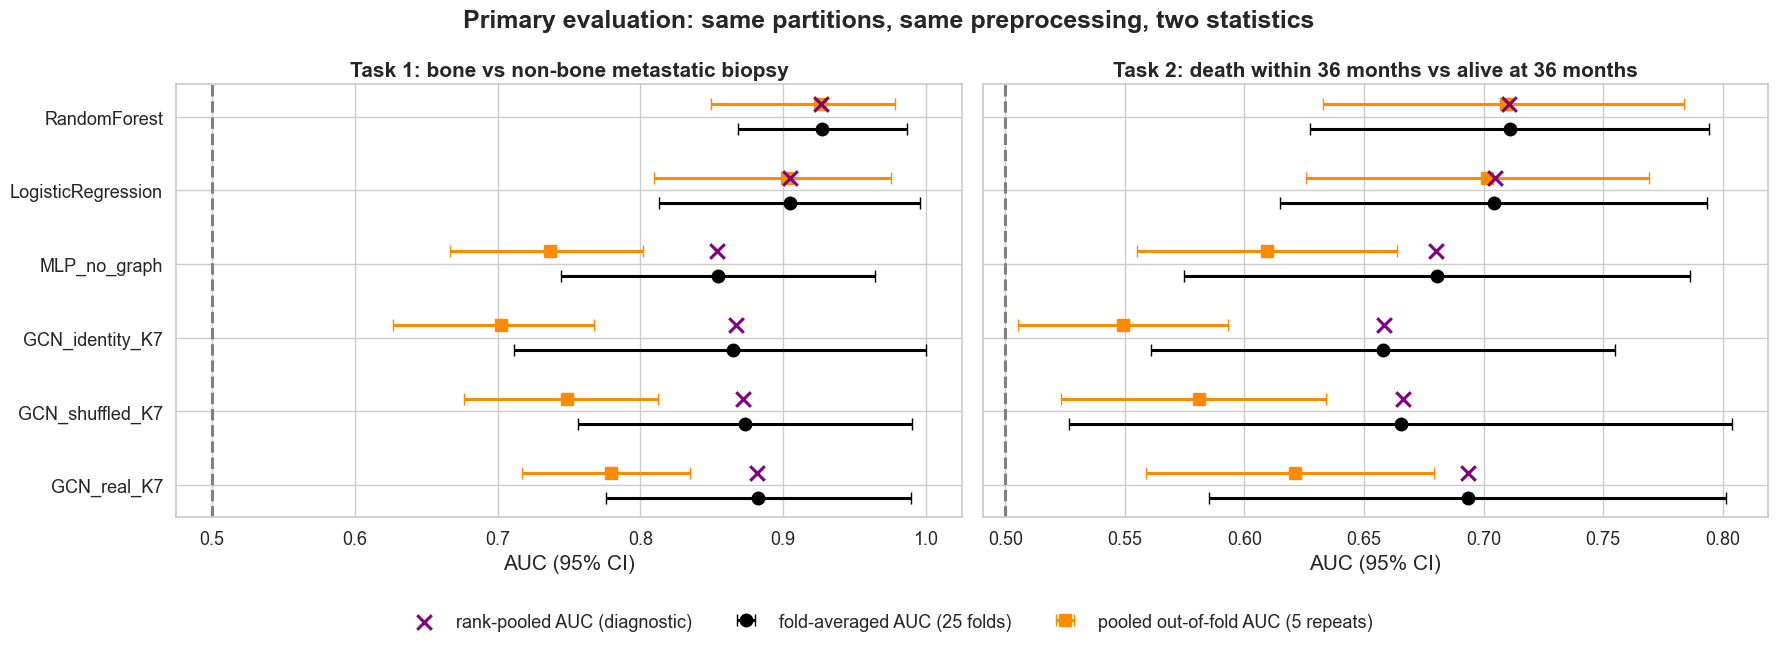

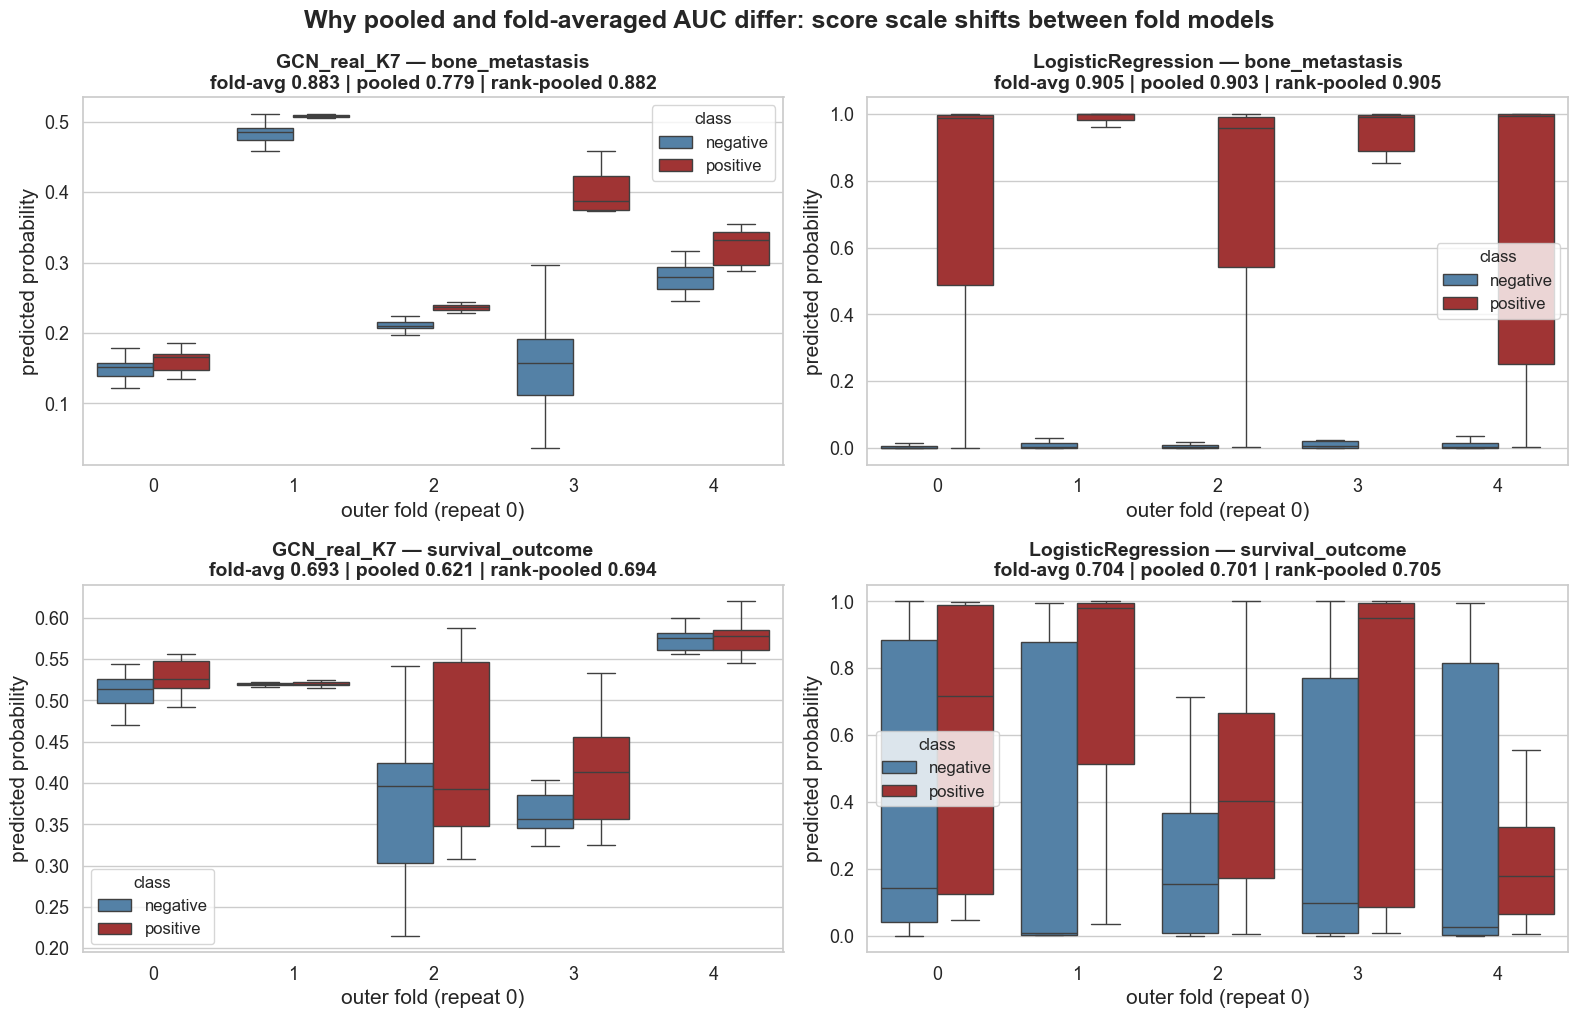

Generated reconciliation statement:
  [bone_metastasis] Graph-CNN fold-averaged AUC 0.883 (95% CI 0.776-0.989); pooled OOF AUC 0.779 (0.717-0.835); rank-pooled 0.882. Gap fold-avg minus pooled = +0.104 for the Graph-CNN vs LogisticRegression +0.002, RandomForest +0.002. Rank-pooling closes most of the gap, so the difference reflects between-fold shifts in the Graph-CNN's probability scale (unstable calibration across retrainings), not worse within-fold ranking.
  [survival_outcome] Graph-CNN fold-averaged AUC 0.693 (95% CI 0.585-0.801); pooled OOF AUC 0.621 (0.559-0.679); rank-pooled 0.694. Gap fold-avg minus pooled = +0.072 for the Graph-CNN vs LogisticRegression +0.003, RandomForest +0.002. Rank-pooling closes most of the gap, so the difference reflects between-fold shifts in the Graph-CNN's probability scale (unstable calibration across retrainings), not worse within-fold ranking.


In [27]:
# Figure: both statistics with CIs, every main model, both tasks
fig, axes = plt.subplots(1, len(TASKS), figsize=(9 * len(TASKS), 6.5), sharey=True)
for ax, task in zip(axes, TASKS):
    d = table1[table1.task == task].set_index("model").loc[MAIN_MODELS]
    y = np.arange(len(d))
    ax.errorbar(d.fold_avg_AUC, y - 0.17, xerr=[d.fold_avg_AUC - d.fold_avg_CI_lo, d.fold_avg_CI_hi - d.fold_avg_AUC],
                fmt="o", color="black", capsize=4, ms=9, label="fold-averaged AUC (25 folds)")
    ax.errorbar(d.pooled_OOF_AUC, y + 0.17, xerr=[d.pooled_OOF_AUC - d.pooled_CI_lo, d.pooled_CI_hi - d.pooled_OOF_AUC],
                fmt="s", color="darkorange", capsize=4, ms=9, label="pooled out-of-fold AUC (5 repeats)")
    ax.scatter(d.rank_pooled_AUC, y + 0.17, marker="x", s=110, color="purple", zorder=5, label="rank-pooled AUC (diagnostic)")
    ax.axvline(0.5, color="grey", ls="--")
    ax.set_yticks(y); ax.set_yticklabels(d.index); ax.invert_yaxis()
    ax.set_xlabel("AUC (95% CI)"); ax.set_title(TASK_INFO[task]["label"], fontsize=15)
h_, l_ = axes[0].get_legend_handles_labels()
fig.suptitle("Primary evaluation: same partitions, same preprocessing, two statistics")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(h_, l_, loc="lower center", ncol=3, fontsize=13, frameon=False)
save_fig(fig, "01_headline_AUC_both_statistics")

# Score-shift diagnostic: per-fold predicted probabilities, Graph-CNN vs logistic regression (repeat 0)
fig, axes = plt.subplots(len(TASKS), 2, figsize=(16, 5.2 * len(TASKS)), squeeze=False)
for i, task in enumerate(TASKS):
    for j, m in enumerate(["GCN_real_K7", "LogisticRegression"]):
        d = PRIMARY_OOF[(PRIMARY_OOF.task == task) & (PRIMARY_OOF.model == m) & (PRIMARY_OOF.repeat == 0)].copy()
        d["class"] = d.y_true.map({1: "positive", 0: "negative"})
        sns.boxplot(data=d, x="fold", y="prob", hue="class", hue_order=["negative", "positive"],
                    palette=["steelblue", "firebrick"], ax=axes[i, j], showfliers=False)
        s = primary_summary[(primary_summary.task == task) & (primary_summary.model == m)].iloc[0]
        axes[i, j].set_title(f"{m} — {task}\nfold-avg {s.fold_avg_AUC:.3f} | pooled {s.pooled_OOF_AUC:.3f} | rank-pooled {s.rank_pooled_AUC:.3f}",
                             fontsize=14)
        axes[i, j].set_xlabel("outer fold (repeat 0)"); axes[i, j].set_ylabel("predicted probability")
fig.suptitle("Why pooled and fold-averaged AUC differ: score scale shifts between fold models")
fig.tight_layout(); save_fig(fig, "02_score_shift_between_folds")

print("Generated reconciliation statement:")
for task in TASKS:
    g = primary_summary[(primary_summary.task == task) & (primary_summary.model == "GCN_real_K7")].iloc[0]
    others = primary_summary[(primary_summary.task == task) & primary_summary.model.isin(["LogisticRegression", "RandomForest"])]
    print(f"  [{task}] Graph-CNN fold-averaged AUC {g.fold_avg_AUC:.3f} (95% CI {g.fold_avg_CI_lo:.3f}-{g.fold_avg_CI_hi:.3f}); "
          f"pooled OOF AUC {g.pooled_OOF_AUC:.3f} ({g.pooled_CI_lo:.3f}-{g.pooled_CI_hi:.3f}); rank-pooled {g.rank_pooled_AUC:.3f}. "
          f"Gap fold-avg minus pooled = {g.gap_fold_minus_pooled:+.3f} for the Graph-CNN vs "
          + ", ".join(f"{r.model} {r.gap_fold_minus_pooled:+.3f}" for r in others.itertuples())
          + (". Rank-pooling closes most of the gap, so the difference reflects between-fold shifts in the Graph-CNN's "
             "probability scale (unstable calibration across retrainings), not worse within-fold ranking."
             if (g.fold_avg_AUC - g.rank_pooled_AUC) < 0.5 * g.gap_fold_minus_pooled else
             ". Rank-pooling does not close the gap; the difference is not explained by score-scale shifts alone."))

## 5. Reviewer comment 2 — graph topology

Every comparison uses the **same partitions** and is reported with **both statistics**:
* **(A) Fold-level paired test** — real STRING graph minus comparator over the 25 shared folds, Nadeau–Bengio corrected 95% CI and P, Holm-adjusted within task. The comparator "mean of 20 shuffled graphs" averages, fold by fold, the AUCs of all 20 degree-preserving shuffles. This is the paired version of the null-distribution question.
* **(B) Null distribution** — where the real graph's AUC ranks among the 20 shuffled graphs, for both statistics. Empirical P = (1 + number of shuffled graphs ≥ real) / 21.

v14's two shuffled-graph results looked contradictory because one was a paired fold-level test against a single shuffle and the other a pooled-OOF rank among 20 shuffles. Here both statistics are shown for both designs.

,task,comparison,A_fold_AUC_diff,A_CI95_lo,A_CI95_hi,A_P,A_folds_real_better,B_pooled_AUC_diff_mean,B_pooled_diff_min,B_pooled_diff_max,B_repeats_real_better,A_P_Holm
0,bone_metastasis,real STRING minus GCN_shuffled_K7,0.0096,-0.0420,0.0611,0.7045,12,0.0304,-0.0389,0.0857,4,1.0
1,bone_metastasis,real STRING minus mean of 20 shuffled graphs,-0.0006,-0.0293,0.0280,0.9633,14,0.0027,-0.0839,0.0576,3,1.0
2,bone_metastasis,real STRING minus GCN_identity_K7,0.0178,-0.0688,0.1044,0.6752,12,0.0771,-0.0588,0.1874,3,1.0
3,bone_metastasis,real STRING minus MLP_no_graph,0.0285,-0.0333,0.0904,0.3507,18,0.0425,-0.0195,0.1601,4,1.0
4,bone_metastasis,real STRING minus LogisticRegression,-0.0219,-0.0943,0.0506,0.5392,9,-0.1238,-0.2589,0.0183,1,1.0
5,bone_metastasis,real STRING minus RandomForest,-0.0448,-0.1186,0.0290,0.2226,6,-0.1467,-0.2724,-0.0094,0,1.0
6,bone_metastasis,real STRING minus GCN_string700_K7,-0.0087,-0.0602,0.0428,0.7307,6,-0.0287,-0.1320,0.0345,2,1.0
7,bone_metastasis,real STRING minus GCN_string900_K7,-0.0108,-0.0429,0.0212,0.4912,7,0.0246,-0.0879,0.1258,3,1.0
8,survival_outcome,real STRING minus GCN_shuffled_K7,0.0279,-0.1484,0.2042,0.7465,12,0.0401,-0.0462,0.1882,3,1.0
9,survival_outcome,real STRING minus mean of 20 shuffled graphs,0.0087,-0.1038,0.1213,0.8741,13,0.0227,-0.0331,0.1244,2,1.0


,task,statistic,real_graph,shuffled_mean,shuffled_SD,shuffled_min,shuffled_max,n_shuffled,n_shuffled_at_or_above_real,real_rank_among_all,empirical_P_one_sided,z_vs_shuffled
0,bone_metastasis,fold-averaged AUC,0.8827,0.8834,0.0088,0.8679,0.9012,20,13,14,0.6667,-0.0732
1,bone_metastasis,pooled OOF AUC,0.7792,0.7765,0.0343,0.7028,0.8439,20,8,9,0.4286,0.0783
2,survival_outcome,fold-averaged AUC,0.6933,0.6846,0.0185,0.6593,0.7248,20,6,7,0.3333,0.4717
3,survival_outcome,pooled OOF AUC,0.6212,0.5985,0.0185,0.5729,0.6440,20,2,3,0.1429,1.2237


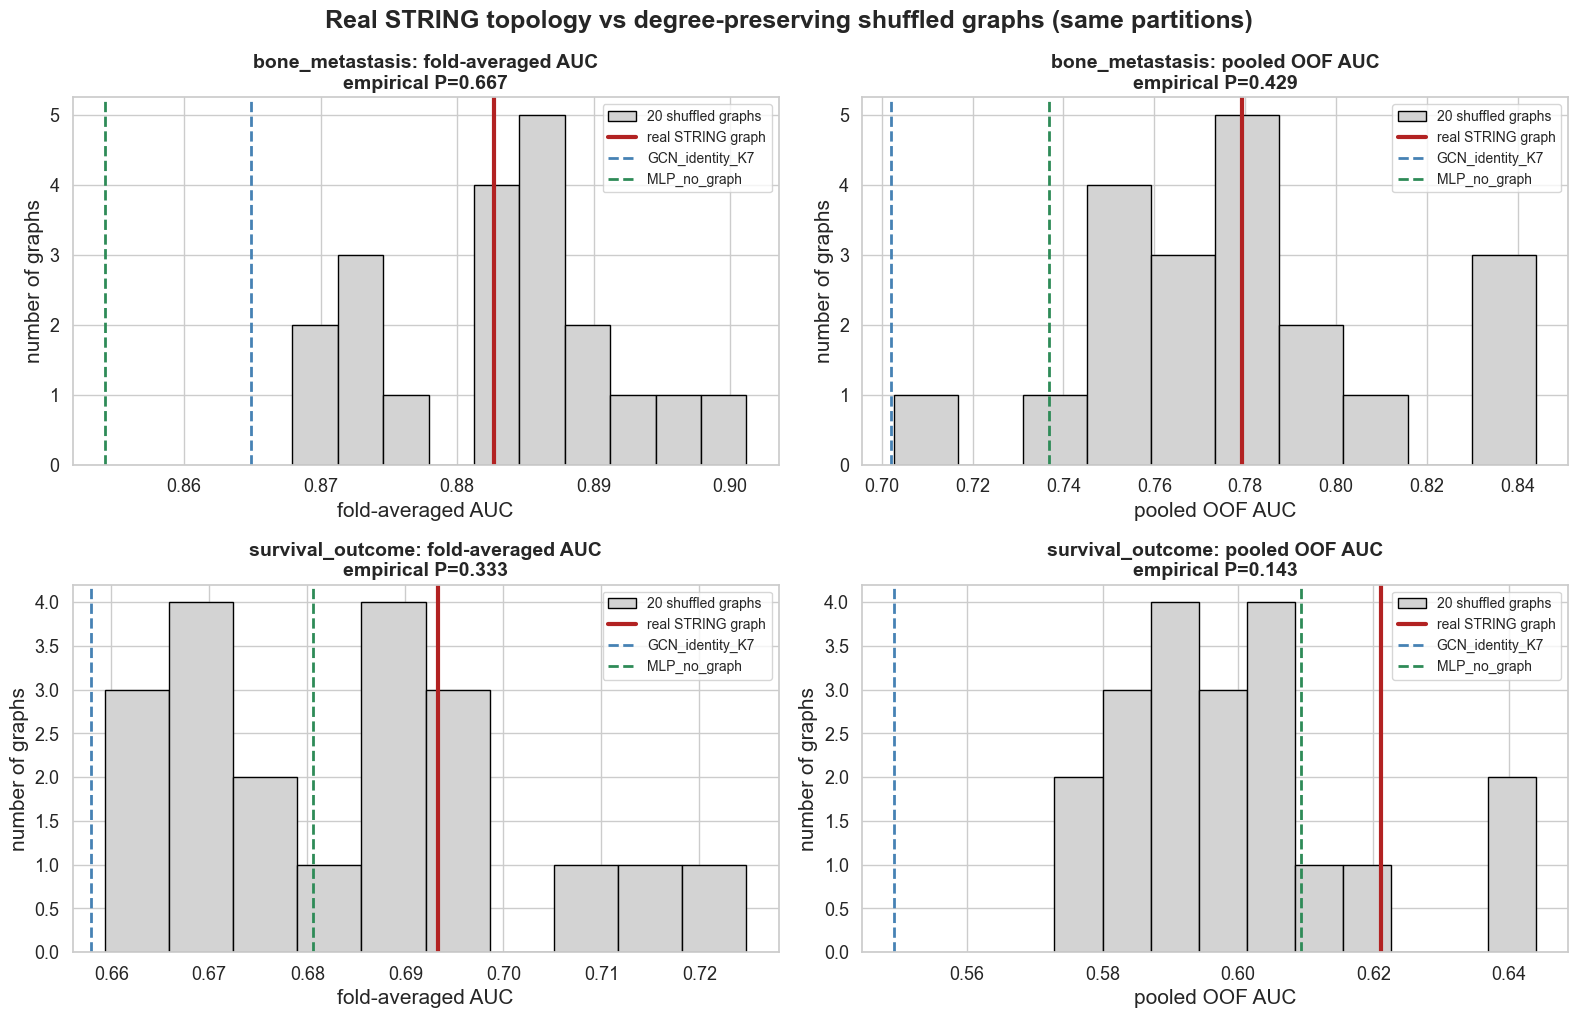

Generated wording:
  [bone_metastasis] Real vs mean of 20 shuffled graphs: fold-level ΔAUC -0.001 (95% CI -0.029 to +0.028; P_Holm=1). Rank among shuffled graphs: fold-averaged P=0.667, pooled OOF P=0.429. There is no evidence that the specific STRING topology improves prediction beyond a degree-matched random graph; the two statistics agree on this.
  [survival_outcome] Real vs mean of 20 shuffled graphs: fold-level ΔAUC +0.009 (95% CI -0.104 to +0.121; P_Holm=1). Rank among shuffled graphs: fold-averaged P=0.333, pooled OOF P=0.143. There is no evidence that the specific STRING topology improves prediction beyond a degree-matched random graph; the two statistics agree on this.


In [28]:
def fold_auc(task, model):
    return PRIMARY_FOLD[(PRIMARY_FOLD.task == task) & (PRIMARY_FOLD.model == model)].set_index(["repeat", "fold"]).AUC.sort_index()

def pooled_auc_by_repeat(task, model):
    d = PRIMARY_OOF[(PRIMARY_OOF.task == task) & (PRIMARY_OOF.model == model)]
    return per_repeat(d, lambda g: roc_auc_score(g.y_true, g.prob))

TOPO_COMPARATORS = ["GCN_shuffled_K7", "SHUFFLED_MEAN", "GCN_identity_K7", "MLP_no_graph", "LogisticRegression", "RandomForest"] + \
                   (["GCN_string700_K7", "GCN_string900_K7"] if RUN_DENSITY_GRAPHS else [])
topo_rows, null_rows = [], []
for task in TASKS:
    ntr, nte = ntr_nte(task)
    real_f, real_p = fold_auc(task, "GCN_real_K7"), pooled_auc_by_repeat(task, "GCN_real_K7")
    shuf_f = pd.concat({m: fold_auc(task, m) for m in SHUFFLED_MODELS}, axis=1)
    shuf_p = pd.concat({m: pooled_auc_by_repeat(task, m) for m in SHUFFLED_MODELS}, axis=1)
    tmp = []
    for comp in TOPO_COMPARATORS:
        cf = shuf_f.mean(axis=1) if comp == "SHUFFLED_MEAN" else fold_auc(task, comp)
        cp = shuf_p.mean(axis=1) if comp == "SHUFFLED_MEAN" else pooled_auc_by_repeat(task, comp)
        m_, lo, hi, p = nb_corrected((real_f - cf.reindex(real_f.index)).values, ntr, nte)
        dp = real_p - cp
        tmp.append({"task": task, "comparison": f"real STRING minus {'mean of %d shuffled graphs' % len(SHUFFLED_MODELS) if comp == 'SHUFFLED_MEAN' else comp}",
                    "A_fold_AUC_diff": m_, "A_CI95_lo": lo, "A_CI95_hi": hi, "A_P": p,
                    "A_folds_real_better": int(((real_f - cf.reindex(real_f.index)) > 0).sum()),
                    "B_pooled_AUC_diff_mean": dp.mean(), "B_pooled_diff_min": dp.min(), "B_pooled_diff_max": dp.max(),
                    "B_repeats_real_better": int((dp > 0).sum())})
    for r, ph in zip(tmp, holm([r["A_P"] for r in tmp])):
        r["A_P_Holm"] = ph
    topo_rows += tmp
    for stat, real_v, shuf_v in [("fold-averaged AUC", real_f.mean(), shuf_f.mean()), ("pooled OOF AUC", real_p.mean(), shuf_p.mean())]:
        n_ge = int((shuf_v >= real_v).sum())
        null_rows.append({"task": task, "statistic": stat, "real_graph": real_v, "shuffled_mean": shuf_v.mean(),
                          "shuffled_SD": shuf_v.std(ddof=1), "shuffled_min": shuf_v.min(), "shuffled_max": shuf_v.max(),
                          "n_shuffled": len(shuf_v), "n_shuffled_at_or_above_real": n_ge,
                          "real_rank_among_all": int((shuf_v > real_v).sum()) + 1,
                          "empirical_P_one_sided": (1 + n_ge) / (len(shuf_v) + 1),
                          "z_vs_shuffled": (real_v - shuf_v.mean()) / shuf_v.std(ddof=1)})
topo_tests = save_table(pd.DataFrame(topo_rows), "TOPOLOGY_paired_tests_both_statistics")
shuffle_null = save_table(pd.DataFrame(null_rows), "TOPOLOGY_shuffled_graph_null_both_statistics")
display(topo_tests.round(4)); display(shuffle_null.round(4))

fig, axes = plt.subplots(len(TASKS), 2, figsize=(16, 5.2 * len(TASKS)), squeeze=False)
for i, task in enumerate(TASKS):
    for j, (stat, fn) in enumerate([("fold-averaged AUC", lambda m: fold_auc(task, m).mean()),
                                    ("pooled OOF AUC", lambda m: pooled_auc_by_repeat(task, m).mean())]):
        vals = [fn(m) for m in SHUFFLED_MODELS]
        s = shuffle_null[(shuffle_null.task == task) & (shuffle_null.statistic == stat)].iloc[0]
        ax = axes[i, j]
        ax.hist(vals, bins=10, color="lightgrey", edgecolor="black", label=f"{len(vals)} shuffled graphs")
        ax.axvline(s.real_graph, color="firebrick", lw=3, label="real STRING graph")
        for m, c in [("GCN_identity_K7", "steelblue"), ("MLP_no_graph", "seagreen")]:
            ax.axvline(fn(m), color=c, lw=2, ls="--", label=m)
        ax.set_title(f"{task}: {stat}\nempirical P={s.empirical_P_one_sided:.3f}", fontsize=14)
        ax.set_xlabel(stat); ax.set_ylabel("number of graphs"); ax.legend(fontsize=10)
fig.suptitle("Real STRING topology vs degree-preserving shuffled graphs (same partitions)")
fig.tight_layout(); save_fig(fig, "03_topology_shuffled_null_both_statistics")

print("Generated wording:")
for task in TASKS:
    t = topo_tests[(topo_tests.task == task) & topo_tests.comparison.str.contains("mean of")].iloc[0]
    nf = shuffle_null[(shuffle_null.task == task) & (shuffle_null.statistic == "fold-averaged AUC")].iloc[0]
    npo = shuffle_null[(shuffle_null.task == task) & (shuffle_null.statistic == "pooled OOF AUC")].iloc[0]
    supported = (t.A_P_Holm < 0.05) and (nf.empirical_P_one_sided < 0.05) and (npo.empirical_P_one_sided < 0.05)
    print(f"  [{task}] Real vs mean of {len(SHUFFLED_MODELS)} shuffled graphs: fold-level ΔAUC {t.A_fold_AUC_diff:+.3f} "
          f"(95% CI {t.A_CI95_lo:+.3f} to {t.A_CI95_hi:+.3f}; P_Holm={t.A_P_Holm:.3g}). Rank among shuffled graphs: "
          f"fold-averaged P={nf.empirical_P_one_sided:.3f}, pooled OOF P={npo.empirical_P_one_sided:.3f}. "
          + ("The STRING topology improved prediction beyond degree-matched random graphs."
             if supported else "There is no evidence that the specific STRING topology improves prediction beyond a degree-matched "
             "random graph; the two statistics agree on this."))

In [29]:
# Graph structure (why a dense graph + K=7 may wash out topology)
def khop_reach(G, hops):
    fr = []
    for s in gene_list:
        seen, fr_q = {s}, deque([(s, 0)])
        while fr_q:
            u, d = fr_q.popleft()
            if d == hops:
                continue
            for v in G.neighbors(u):
                if v not in seen:
                    seen.add(v); fr_q.append((v, d + 1))
        fr.append((len(seen) - 1) / (N - 1))
    return float(np.mean(fr))
struct = []
for key, label in [("real", "STRING >= 400 (primary)"), ("shuffled", "shuffled (seed 0)"), ("string700", "STRING >= 700"),
                   ("string900", "STRING >= 900"), ("identity", "identity (no edges)")]:
    if key not in GRAPHS:
        continue
    G = GRAPHS[key]; degs = np.array([d for _, d in G.degree(gene_list)])
    struct.append({"graph": label, "edges": G.number_of_edges(), "mean_degree": degs.mean(), "isolated_genes": int((degs == 0).sum()),
                   "reach_within_2_hops": khop_reach(G, 2), "reach_within_6_hops (K=7)": khop_reach(G, 6)})
graph_structure = save_table(pd.DataFrame(struct), "graph_structure_density_reach")
display(graph_structure.round(3))

,graph,edges,mean_degree,isolated_genes,reach_within_2_hops,reach_within_6_hops (K=7)
0,STRING >= 400 (primary),19902,54.008,0,0.665,1.000
1,shuffled (seed 0),19902,54.008,0,0.819,1.000
2,STRING >= 700,6231,16.909,80,0.213,0.763
3,STRING >= 900,2603,7.064,172,0.067,0.532
4,identity (no edges),0,0.000,737,0.000,0.000


## 6. Reviewer comment 2 — Chebyshev filter order K

* **(a) Sweep:** K ∈ {3, 5, 7, 9} on the shared partitions, each compared with K = 7 by the corrected paired test, Holm-adjusted across the 3 comparisons.
* **(b) Nested selection:** inside every outer fold, K is chosen by **inner 3-fold cross-validation** on the outer training data only, using mean inner-test AUC. That fold's test predictions then come from the chosen K. v14 chose K from a single ~20-sample validation split, which tied in 15 of 25 folds. The inner CV uses about 49 held-out samples per inner fold. This gives the honest estimate of "tune K, then predict" and shows how often each K is chosen.
* **(c) Wording** says "pre-specified" or "best of the values tested in this cohort", never "optimal".

In [30]:
K_VALUES = [3, 5, 7, 9]
K_MODELS = {k: f"GCN_real_K{k}" for k in K_VALUES}
ksw, kt = [], []
for task in TASKS:
    ntr, nte = ntr_nte(task)
    base_f, base_p = fold_auc(task, K_MODELS[7]), pooled_auc_by_repeat(task, K_MODELS[7])
    for k in K_VALUES:
        s = primary_summary[(primary_summary.task == task) & (primary_summary.model == K_MODELS[k])].iloc[0]
        ksw.append({"task": task, "K": k, "fold_avg_AUC": s.fold_avg_AUC, "fold_avg_CI_lo": s.fold_avg_CI_lo,
                    "fold_avg_CI_hi": s.fold_avg_CI_hi, "pooled_OOF_AUC": s.pooled_OOF_AUC})
    tmp = []
    for k in [3, 5, 9]:
        m_, lo, hi, p = nb_corrected((fold_auc(task, K_MODELS[k]) - base_f).values, ntr, nte)
        dp = pooled_auc_by_repeat(task, K_MODELS[k]) - base_p
        tmp.append({"task": task, "comparison": f"K={k} minus K=7", "fold_AUC_diff": m_, "CI95_lo": lo, "CI95_hi": hi, "P": p,
                    "pooled_diff_mean": dp.mean(), "repeats_better_than_K7": int((dp > 0).sum())})
    for r, ph in zip(tmp, holm([r["P"] for r in tmp])):
        r["P_Holm"] = ph
    kt += tmp
k_sweep = save_table(pd.DataFrame(ksw), "K_sweep")
k_tests = save_table(pd.DataFrame(kt), "K_paired_tests_vs_K7")
display(k_sweep.round(4)); display(k_tests.round(4))

,task,K,fold_avg_AUC,fold_avg_CI_lo,fold_avg_CI_hi,pooled_OOF_AUC
0,bone_metastasis,3,0.8836,0.7593,1.0000,0.7312
1,bone_metastasis,5,0.8805,0.7606,1.0000,0.7648
2,bone_metastasis,7,0.8827,0.7760,0.9894,0.7792
3,bone_metastasis,9,0.8883,0.7720,1.0000,0.8232
4,survival_outcome,3,0.6860,0.5561,0.8158,0.5908
5,survival_outcome,5,0.6635,0.5519,0.7752,0.5743
6,survival_outcome,7,0.6933,0.5852,0.8014,0.6212
7,survival_outcome,9,0.6971,0.5893,0.8050,0.6329


,task,comparison,fold_AUC_diff,CI95_lo,CI95_hi,P,pooled_diff_mean,repeats_better_than_K7,P_Holm
0,bone_metastasis,K=3 minus K=7,0.0009,-0.0445,0.0464,0.9667,-0.0480,0,1.0
1,bone_metastasis,K=5 minus K=7,-0.0022,-0.0483,0.0439,0.9225,-0.0144,3,1.0
2,bone_metastasis,K=9 minus K=7,0.0056,-0.0483,0.0595,0.8329,0.0440,3,1.0
3,survival_outcome,K=3 minus K=7,-0.0073,-0.1689,0.1543,0.9263,-0.0304,3,1.0
4,survival_outcome,K=5 minus K=7,-0.0298,-0.1605,0.1010,0.6429,-0.0469,1,1.0
5,survival_outcome,K=9 minus K=7,0.0038,-0.0853,0.0930,0.9301,0.0118,4,1.0


    nested K | bone_metastasis | repeat 1 fold 1: chose K=5 (0.2 min elapsed)


    nested K | bone_metastasis | repeat 1 fold 2: chose K=5 (0.4 min elapsed)


    nested K | bone_metastasis | repeat 1 fold 3: chose K=3 (0.7 min elapsed)


    nested K | bone_metastasis | repeat 1 fold 4: chose K=5 (0.9 min elapsed)


    nested K | bone_metastasis | repeat 1 fold 5: chose K=5 (1.1 min elapsed)


...

    nested K | survival_outcome | repeat 5 fold 3: chose K=7 (9.7 min elapsed)


    nested K | survival_outcome | repeat 5 fold 4: chose K=3 (9.9 min elapsed)


    nested K | survival_outcome | repeat 5 fold 5: chose K=7 (10.1 min elapsed)


  nested K: survival_outcome repeat 5/5 done (10.1 min elapsed)


,task,nested_fold_avg_AUC,CI95_lo,CI95_hi,nested_pooled_OOF_AUC,folds_with_tie,n_outer_folds,times_K3_chosen,times_K5_chosen,times_K7_chosen,times_K9_chosen
0,bone_metastasis,0.8723,0.7472,0.9975,0.7633,0,25,6,7,5,7
1,survival_outcome,0.6764,0.5705,0.7823,0.6181,0,25,6,9,5,5


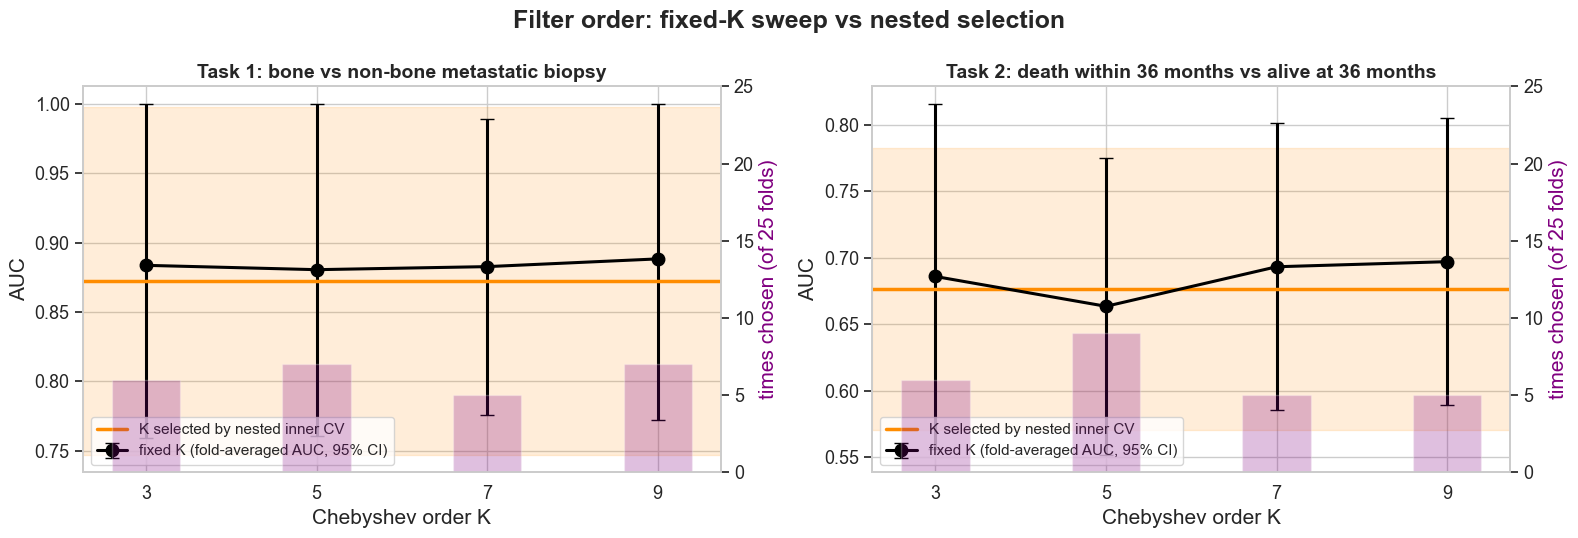

Generated wording:
  [bone_metastasis] K=7 was pre-specified (Paper 2). No alternative K differed significantly from K=7 (corrected paired test, Holm); differences larger than ±0.059 AUC are excluded by the 95% CIs. With K tuned by nested inner CV, the fold-averaged AUC was 0.872 (95% CI 0.747-0.998); K=7 was chosen in 5 of 25 folds (0 ties). The data do not identify a single best K.
  [survival_outcome] K=7 was pre-specified (Paper 2). No alternative K differed significantly from K=7 (corrected paired test, Holm); differences larger than ±0.169 AUC are excluded by the 95% CIs. With K tuned by nested inner CV, the fold-averaged AUC was 0.676 (95% CI 0.570-0.782); K=7 was chosen in 5 of 25 folds (0 ties). The data do not identify a single best K.


In [31]:
NESTED_DIR = os.path.join(CKPT_DIR, "nested_K"); os.makedirs(NESTED_DIR, exist_ok=True)
nested_rows = []
if RUN_NESTED_K:
    _t0 = time.time()
    for task in TASKS:
        lab = PRIMARY_LABELS[task]
        for repeat in range(min(NESTED_K_REPEATS, N_REPEATS_PRIMARY)):
            path = os.path.join(NESTED_DIR, f"{task}__rep{repeat}__inner{NESTED_INNER_FOLDS}.pkl")
            if os.path.exists(path):
                with open(path, "rb") as f:
                    nested_rows += pickle.load(f)
                continue
            rows_rep = []
            for p in [p for p in PRIMARY_PARTITIONS[task] if p["repeat"] == repeat]:
                outer = np.array(p["train"] + p["val"]); y_out = lab.loc[outer].to_numpy()
                skf = StratifiedKFold(NESTED_INNER_FOLDS, shuffle=True, random_state=1000 + 100 * repeat + p["fold"])
                inner_auc = {k: [] for k in K_VALUES}
                for ii, (a, b) in enumerate(skf.split(outer, y_out)):
                    itr, iva = train_test_split(outer[a], test_size=INNER_VAL_FRACTION, stratify=y_out[a],
                                                random_state=2000 + 100 * repeat + 10 * p["fold"] + ii)
                    ite = outer[b]
                    Xtr, _ = prep_fold(list(itr), list(itr)); Xva, _ = prep_fold(list(itr), list(iva)); Xte, _ = prep_fold(list(itr), list(ite))
                    for k in K_VALUES:
                        seed = 70000 + 1000 * repeat + 100 * p["fold"] + 10 * ii + k
                        _, _, te_p, _ = fit_predict(K_MODELS[k], Xtr, lab.loc[itr].to_numpy(), Xva, lab.loc[iva].to_numpy(), Xte, seed)
                        inner_auc[k].append(roc_auc_score(lab.loc[ite].to_numpy(), te_p))
                means = {k: float(np.mean(v)) for k, v in inner_auc.items()}
                best = max(means.values())
                chosen = min(k for k, v in means.items() if np.isclose(v, best))      # tie -> smaller K
                print(f"    nested K | {task} | repeat {repeat + 1} fold {p['fold'] + 1}: chose K={chosen} "
                      f"({(time.time() - _t0) / 60:.1f} min elapsed)", flush=True)
                rows_rep.append({"task": task, "repeat": repeat, "fold": p["fold"], "chosen_K": chosen,
                                 "n_tied_at_best": int(sum(np.isclose(v, best) for v in means.values())),
                                 **{f"inner_AUC_K{k}": means[k] for k in K_VALUES}})
            with open(path, "wb") as f:
                pickle.dump(rows_rep, f)
            nested_rows += rows_rep
            print(f"  nested K: {task} repeat {repeat + 1}/{min(NESTED_K_REPEATS, N_REPEATS_PRIMARY)} done "
                  f"({(time.time() - _t0) / 60:.1f} min elapsed)", flush=True)
    nested_K = pd.DataFrame(nested_rows)
    save_table(nested_K, "K_nested_inner_cv_selection")
    nk_rows = []
    for task in TASKS:
        nk = nested_K[nested_K.task == task]
        sel_f = pd.concat([PRIMARY_FOLD[(PRIMARY_FOLD.task == task) & (PRIMARY_FOLD.model == f"GCN_real_K{r.chosen_K}")
                                        & (PRIMARY_FOLD.repeat == r.repeat) & (PRIMARY_FOLD.fold == r.fold)] for r in nk.itertuples()])
        sel_o = pd.concat([PRIMARY_OOF[(PRIMARY_OOF.task == task) & (PRIMARY_OOF.model == f"GCN_real_K{r.chosen_K}")
                                       & (PRIMARY_OOF.repeat == r.repeat) & (PRIMARY_OOF.fold == r.fold)] for r in nk.itertuples()])
        ntr, nte = ntr_nte(task)
        fa, lo, hi = nb_ci_auc(sel_f.AUC.values, ntr, nte)
        pooled = per_repeat(sel_o, lambda g: roc_auc_score(g.y_true, g.prob))
        freq = nk.chosen_K.value_counts().reindex(K_VALUES, fill_value=0)
        nk_rows.append({"task": task, "nested_fold_avg_AUC": fa, "CI95_lo": lo, "CI95_hi": hi, "nested_pooled_OOF_AUC": pooled.mean(),
                        "folds_with_tie": int((nk.n_tied_at_best > 1).sum()), "n_outer_folds": len(nk),
                        **{f"times_K{k}_chosen": int(freq[k]) for k in K_VALUES}})
    k_nested = save_table(pd.DataFrame(nk_rows), "K_nested_summary")
    display(k_nested.round(4))

    fig, axes = plt.subplots(1, len(TASKS), figsize=(8 * len(TASKS), 5.5), squeeze=False)
    for ax, task in zip(axes[0], TASKS):
        d = k_sweep[k_sweep.task == task]
        ax.errorbar(d.K, d.fold_avg_AUC, yerr=[d.fold_avg_AUC - d.fold_avg_CI_lo, d.fold_avg_CI_hi - d.fold_avg_AUC],
                    fmt="o-", color="black", capsize=5, ms=9, label="fixed K (fold-averaged AUC, 95% CI)")
        nk = k_nested[k_nested.task == task].iloc[0]
        ax.axhspan(nk.CI95_lo, nk.CI95_hi, color="darkorange", alpha=0.15)
        ax.axhline(nk.nested_fold_avg_AUC, color="darkorange", lw=2.5, label="K selected by nested inner CV")
        ax2 = ax.twinx()
        ax2.bar(K_VALUES, [nk[f"times_K{k}_chosen"] for k in K_VALUES], width=0.8, alpha=0.25, color="purple")
        ax2.set_ylabel("times chosen (of 25 folds)", color="purple"); ax2.set_ylim(0, 25); ax2.grid(False)
        ax.set_xticks(K_VALUES); ax.set_xlabel("Chebyshev order K"); ax.set_ylabel("AUC")
        ax.set_title(TASK_INFO[task]["label"], fontsize=14); ax.legend(loc="lower left", fontsize=11)
    fig.suptitle("Filter order: fixed-K sweep vs nested selection"); fig.tight_layout(); save_fig(fig, "04_filter_order_K")

print("Generated wording:")
for task in TASKS:
    t_ = k_tests[k_tests.task == task]
    sig_better = t_[(t_.P_Holm < 0.05) & (t_.fold_AUC_diff > 0)]
    widest = max(abs(t_.CI95_lo).max(), abs(t_.CI95_hi).max())
    txt = (f"K=7 was pre-specified (Paper 2). No alternative K differed significantly from K=7 (corrected paired test, Holm); "
           f"differences larger than ±{widest:.3f} AUC are excluded by the 95% CIs" if len(t_[t_.P_Holm < 0.05]) == 0 else
           f"{', '.join(sig_better.comparison)} significantly outperformed K=7; K=7 must not be described as optimal")
    if RUN_NESTED_K:
        nk = k_nested[k_nested.task == task].iloc[0]
        txt += (f". With K tuned by nested inner CV, the fold-averaged AUC was {nk.nested_fold_avg_AUC:.3f} "
                f"(95% CI {nk.CI95_lo:.3f}-{nk.CI95_hi:.3f}); K=7 was chosen in {nk.times_K7_chosen} of {nk.n_outer_folds} folds "
                f"({nk.folds_with_tie} ties). The data do not identify a single best K.")
    print(f"  [{task}] {txt}")

## 7. Reviewer comment 4 — does classification depend on tissue composition?

Three retrained variants, on the same partitions and with the same seeds scheme, for the Graph-CNN, LR and RF:
* **Neutralized** — every composition marker gene on the panel is replaced by its training-fold mean, so the model cannot use it. This is conservative: some markers, e.g. SPP1, are also expressed by tumor cells.
* **Residualized** — every gene is regressed on the reliable composition scores (fitted on the training fold only), and the residuals are used.
* **Composition scores only** — logistic regression on the composition scores alone. This measures how much of the site label is predictable from what tissue was sampled.
* **Host-only variants** — the same residualization and composition-only model with the bone-matrix score removed. That score (IBSP, SPP1, CHAD, COL11A1) also reflects tumor osteomimicry, so the host-only variants remove only immune, stromal and marrow (HBB) signal.

,task,model,variant,fold_avg_AUC,CI_lo,CI_hi,pooled_OOF_AUC,diff_vs_original,diff_CI_lo,diff_CI_hi,P,P_Holm
0,bone_metastasis,GCN_real_K7,original,0.8827,0.7760,0.9894,0.7792,0.0000,NaN,NaN,NaN,NaN
1,bone_metastasis,GCN_real_K7,markers neutralized,0.8860,0.7747,0.9973,0.8143,0.0033,-0.0421,0.0487,0.8828,1.0000
2,bone_metastasis,GCN_real_K7,residualized on composition,0.6695,0.5082,0.8309,0.5976,-0.2132,-0.3864,-0.0400,0.0180,0.1438
3,bone_metastasis,GCN_real_K7,residualized on host composition (no bone matrix),0.7581,0.6347,0.8816,0.6371,-0.1246,-0.2681,0.0189,0.0858,0.4881
4,bone_metastasis,LogisticRegression,original,0.9046,0.8133,0.9959,0.9030,0.0000,NaN,NaN,NaN,NaN
5,bone_metastasis,LogisticRegression,markers neutralized,0.9053,0.8112,0.9994,0.9031,0.0008,-0.0224,0.0239,0.9470,1.0000
6,bone_metastasis,LogisticRegression,residualized on composition,0.6493,0.5078,0.7908,0.6446,-0.2553,-0.3917,-0.1189,0.0007,0.0067
7,bone_metastasis,LogisticRegression,residualized on host composition (no bone matrix),0.7922,0.6772,0.9072,0.7839,-0.1124,-0.2399,0.0151,0.0813,0.4881
8,bone_metastasis,RandomForest,original,0.9275,0.8683,0.9867,0.9259,0.0000,NaN,NaN,NaN,NaN
9,bone_metastasis,RandomForest,markers neutralized,0.9152,0.8504,0.9800,0.9099,-0.0123,-0.0454,0.0207,0.4488,1.0000


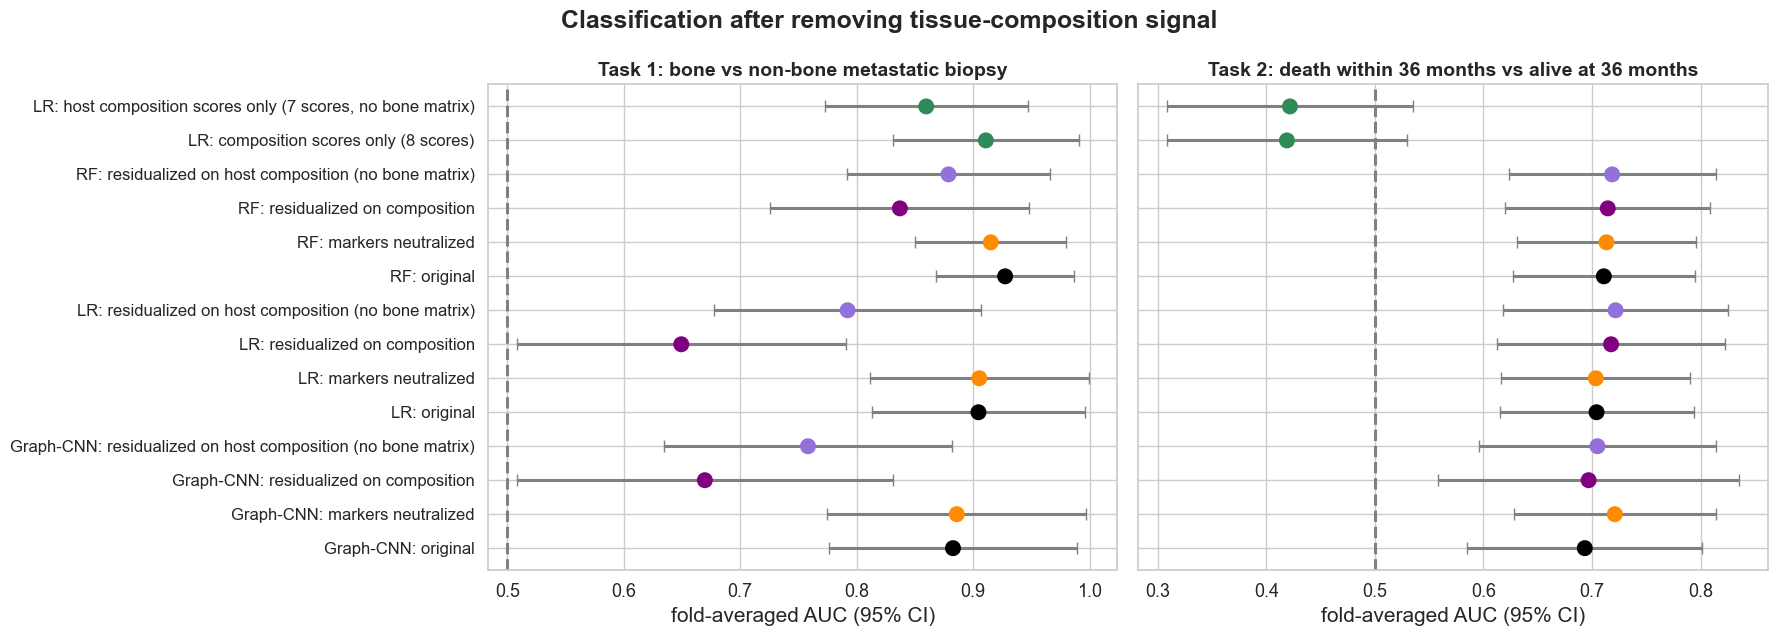

Generated wording:
  [bone_metastasis] Composition scores alone: AUC 0.911 (95% CI 0.831-0.991); host scores alone (no bone matrix): 0.860 (0.773-0.947). Logistic regression on all genes 0.905 -> residualized 0.649, host-residualized 0.792.
  [bone_metastasis] Graph-CNN original 0.883; markers neutralized 0.886 (Δ +0.003, 95% CI -0.042 to +0.049); residualized 0.670 (Δ -0.213); host-residualized 0.758.
  [survival_outcome] Composition scores alone: AUC 0.419 (95% CI 0.309-0.529); host scores alone (no bone matrix): 0.422 (0.309-0.535). Logistic regression on all genes 0.704 -> residualized 0.718, host-residualized 0.722.
  [survival_outcome] Graph-CNN original 0.693; markers neutralized 0.721 (Δ +0.028, 95% CI -0.091 to +0.146); residualized 0.697 (Δ +0.004); host-residualized 0.705.


In [32]:
if RUN_COMPOSITION_MODELS:
    comp_rows = []
    for task in TASKS:
        ntr, nte = ntr_nte(task)
        for base in ["GCN_real_K7", "LogisticRegression", "RandomForest"]:
            b = primary_summary[(primary_summary.task == task) & (primary_summary.model == base)].iloc[0]
            comp_rows.append({"task": task, "model": base, "variant": "original", "fold_avg_AUC": b.fold_avg_AUC,
                              "CI_lo": b.fold_avg_CI_lo, "CI_hi": b.fold_avg_CI_hi, "pooled_OOF_AUC": b.pooled_OOF_AUC,
                              "diff_vs_original": 0.0, "diff_CI_lo": np.nan, "diff_CI_hi": np.nan, "P": np.nan})
            for var, suffix in [("markers neutralized", "_compNeutralized"), ("residualized on composition", "_compResidualized"),
                                ("residualized on host composition (no bone matrix)", "_compResidualizedHost")]:
                s = primary_summary[(primary_summary.task == task) & (primary_summary.model == base + suffix)].iloc[0]
                m_, lo, hi, p = nb_corrected((fold_auc(task, base + suffix) - fold_auc(task, base)).values, ntr, nte)
                comp_rows.append({"task": task, "model": base, "variant": var, "fold_avg_AUC": s.fold_avg_AUC,
                                  "CI_lo": s.fold_avg_CI_lo, "CI_hi": s.fold_avg_CI_hi, "pooled_OOF_AUC": s.pooled_OOF_AUC,
                                  "diff_vs_original": m_, "diff_CI_lo": lo, "diff_CI_hi": hi, "P": p})
        for mname, var in [("CompositionScoresOnly_LR", f"composition scores only ({len(REL_IDX)} scores)"),
                           ("CompositionScoresOnlyHost_LR", f"host composition scores only ({len(HOST_COMPARTMENTS)} scores, no bone matrix)")]:
            s = primary_summary[(primary_summary.task == task) & (primary_summary.model == mname)].iloc[0]
            comp_rows.append({"task": task, "model": "LogisticRegression", "variant": var,
                              "fold_avg_AUC": s.fold_avg_AUC, "CI_lo": s.fold_avg_CI_lo, "CI_hi": s.fold_avg_CI_hi,
                              "pooled_OOF_AUC": s.pooled_OOF_AUC, "diff_vs_original": np.nan, "diff_CI_lo": np.nan,
                              "diff_CI_hi": np.nan, "P": np.nan})
    composition_models = pd.DataFrame(comp_rows)
    composition_models["P_Holm"] = np.nan
    for task in TASKS:
        idx = composition_models[(composition_models.task == task) & composition_models.P.notna()].index
        composition_models.loc[idx, "P_Holm"] = holm(composition_models.loc[idx, "P"].values)
    save_table(composition_models, "COMPOSITION_sensitivity_models")
    display(composition_models.round(4))

    fig, axes = plt.subplots(1, len(TASKS), figsize=(9 * len(TASKS), 6.5), squeeze=False, sharey=True)
    for ax, task in zip(axes[0], TASKS):
        d = composition_models[composition_models.task == task].reset_index(drop=True)
        lab_ = [f"{r.model.replace('LogisticRegression', 'LR').replace('RandomForest', 'RF').replace('GCN_real_K7', 'Graph-CNN')}: {r.variant}"
                for r in d.itertuples()]
        cols = ["black" if v == "original" else ("darkorange" if "neutral" in v else
                ("mediumpurple" if "host" in v and "resid" in v else ("purple" if "resid" in v else "seagreen")))
                for v in d.variant]
        y = np.arange(len(d))
        ax.errorbar(d.fold_avg_AUC, y, xerr=[d.fold_avg_AUC - d.CI_lo, d.CI_hi - d.fold_avg_AUC], fmt="none", ecolor="grey", capsize=4)
        ax.scatter(d.fold_avg_AUC, y, c=cols, s=110, zorder=5)
        ax.set_yticks(y); ax.set_yticklabels(lab_, fontsize=12); ax.invert_yaxis()
        ax.axvline(0.5, color="grey", ls="--"); ax.set_xlabel("fold-averaged AUC (95% CI)")
        ax.set_title(TASK_INFO[task]["label"], fontsize=14)
    fig.suptitle("Classification after removing tissue-composition signal"); fig.tight_layout()
    save_fig(fig, "05_composition_sensitivity_models")

    print("Generated wording:")
    for task in TASKS:
        d = composition_models[composition_models.task == task]
        co = d[d.variant.str.startswith("composition")].iloc[0]
        ch = d[d.variant.str.startswith("host composition")].iloc[0]
        g = d[(d.model == "GCN_real_K7")].set_index("variant")
        lr_ = d[(d.model == "LogisticRegression")].set_index("variant")
        print(f"  [{task}] Composition scores alone: AUC {co.fold_avg_AUC:.3f} (95% CI {co.CI_lo:.3f}-{co.CI_hi:.3f}); host scores "
              f"alone (no bone matrix): {ch.fold_avg_AUC:.3f} ({ch.CI_lo:.3f}-{ch.CI_hi:.3f}). Logistic regression on all genes "
              f"{lr_.loc['original', 'fold_avg_AUC']:.3f} -> residualized {lr_.loc['residualized on composition', 'fold_avg_AUC']:.3f}, "
              f"host-residualized {lr_.loc['residualized on host composition (no bone matrix)', 'fold_avg_AUC']:.3f}.")
        print(f"  [{task}] "
              f"Graph-CNN original {g.loc['original', 'fold_avg_AUC']:.3f}; markers neutralized "
              f"{g.loc['markers neutralized', 'fold_avg_AUC']:.3f} (Δ {g.loc['markers neutralized', 'diff_vs_original']:+.3f}, "
              f"95% CI {g.loc['markers neutralized', 'diff_CI_lo']:+.3f} to {g.loc['markers neutralized', 'diff_CI_hi']:+.3f}); "
              f"residualized {g.loc['residualized on composition', 'fold_avg_AUC']:.3f} "
              f"(Δ {g.loc['residualized on composition', 'diff_vs_original']:+.3f}); host-residualized "
              f"{g.loc['residualized on host composition (no bone matrix)', 'fold_avg_AUC']:.3f}.")

## 8. Reviewer comment 5 — label-shuffled controls across multiple seeds, and what checkpoint selection does

Permutation seeds are run on the 5 folds of repeat 0: 10 for the Graph-CNN in mode A (raise to 20 for a smallest empirical P of 0.048), 5 for mode B, and 20 for logistic regression as a reference. Labels are permuted within class counts. Two modes:

| Mode | Training labels | Inner-validation labels (checkpoint + threshold) | Test labels | What it measures |
|---|---|---|---|---|
| **A. proper null** | shuffled | shuffled | true | performance of the full pipeline when there is no signal; should be ≈ 0.5 |
| **B. v14 design** | shuffled | **true** | true | the optimism created by picking the best of 30 epochs on a small true-label validation set |

In mode B the selected epoch's validation AUC is inflated by construction: it is the maximum of 30 noisy AUCs on about 20 samples. The test set is never used for selection in either mode, so test AUC stays an unbiased estimate. The last-epoch validation AUC is also recorded so the optimism of best-epoch selection can be measured directly.

  [1/70] bone_metastasis | GCN_real_K7 | A | seed 0  — 0.1 min elapsed, ETA 9.3 min


  [2/70] bone_metastasis | GCN_real_K7 | A | seed 1  — 0.3 min elapsed, ETA 9.3 min


  [3/70] bone_metastasis | GCN_real_K7 | A | seed 2  — 0.4 min elapsed, ETA 9.2 min


  [4/70] bone_metastasis | GCN_real_K7 | A | seed 3  — 0.5 min elapsed, ETA 9.1 min


  [5/70] bone_metastasis | GCN_real_K7 | A | seed 4  — 0.7 min elapsed, ETA 8.9 min


...

  [67/70] survival_outcome | LogisticRegression | A | seed 16  — 3.9 min elapsed, ETA 0.2 min


  [68/70] survival_outcome | LogisticRegression | A | seed 17  — 3.9 min elapsed, ETA 0.1 min


  [69/70] survival_outcome | LogisticRegression | A | seed 18  — 3.9 min elapsed, ETA 0.1 min


  [70/70] survival_outcome | LogisticRegression | A | seed 19  — 3.9 min elapsed, ETA 0.0 min


,task,model,mode,n_seeds,null_test_AUC_mean,null_test_AUC_2.5%,null_test_AUC_97.5%,real_model_test_AUC_repeat0,empirical_P_real_vs_null,smallest_attainable_P,selected_val_AUC_mean,last_epoch_val_AUC_mean,selection_optimism_best_minus_last,fraction_folds_selected_val_AUC_ge_0.65
0,bone_metastasis,GCN_real_K7,A_shuffle_train_and_val,10,0.4754,0.3636,0.5964,0.8546,0.0909,0.0909,0.6466,0.5218,0.1247,0.52
1,bone_metastasis,GCN_real_K7,B_shuffle_train_only,5,0.5560,0.4886,0.6381,0.8546,0.1667,0.1667,0.5963,0.5268,0.0695,0.32
2,bone_metastasis,LogisticRegression,A_shuffle_train_and_val,20,0.5124,0.3855,0.6727,0.9127,0.0476,0.0476,0.5100,NaN,NaN,0.20
3,survival_outcome,GCN_real_K7,A_shuffle_train_and_val,10,0.4861,0.3550,0.5732,0.6217,0.0909,0.0909,0.6369,0.4863,0.1506,0.48
4,survival_outcome,GCN_real_K7,B_shuffle_train_only,5,0.5313,0.4424,0.6076,0.6217,0.1667,0.1667,0.6227,0.4819,0.1408,0.48
5,survival_outcome,LogisticRegression,A_shuffle_train_and_val,20,0.4782,0.4088,0.5680,0.6975,0.0476,0.0476,0.4813,NaN,NaN,0.11


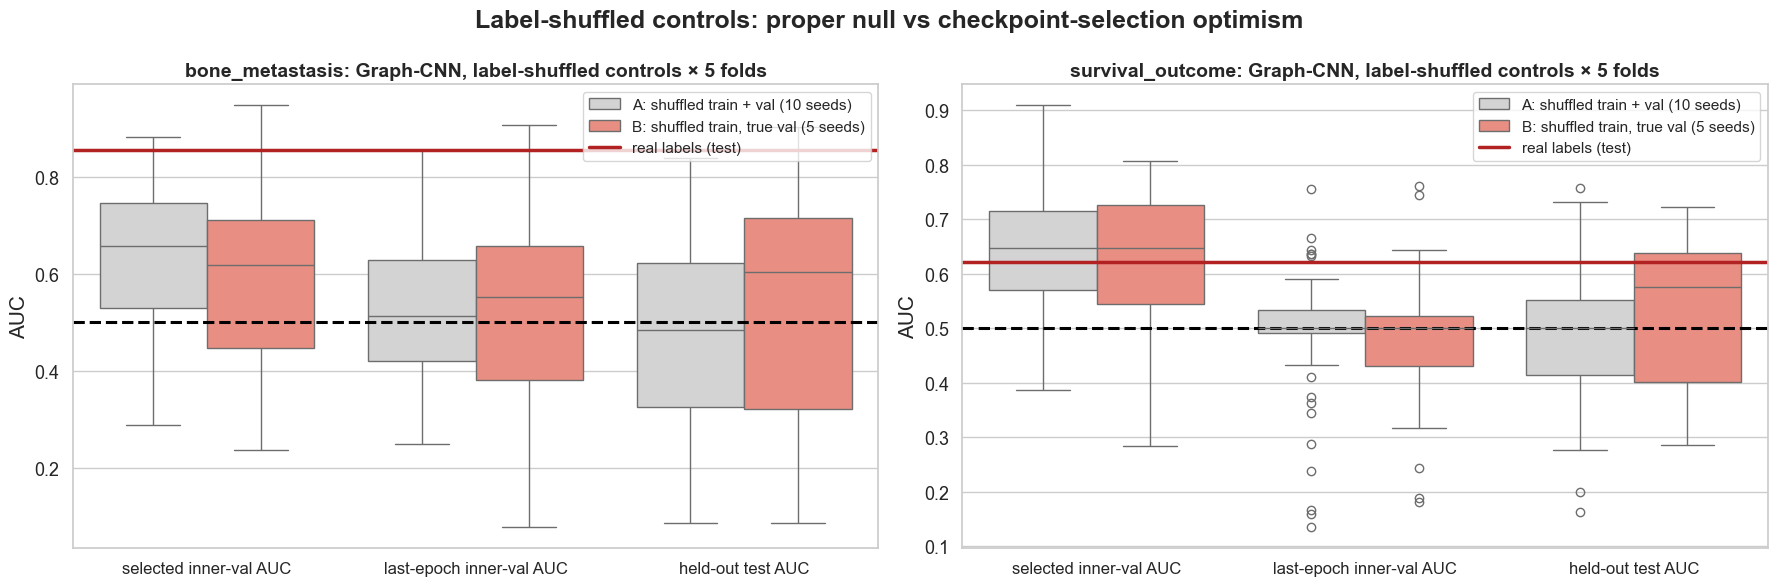

Generated wording:
  [bone_metastasis] Across 10 permutation seeds, the Graph-CNN trained on shuffled labels reached a held-out AUC of 0.475 (95% range 0.364-0.596) vs 0.855 with real labels (empirical P=0.091; smallest attainable 0.091). When the checkpoint was selected on TRUE validation labels (v14 design, 5 seeds), the selected validation AUC averaged 0.596 vs 0.527 at the last epoch (optimism +0.069), while the held-out AUC stayed at 0.556: best-epoch validation AUCs are optimistic and must not be reported as performance; held-out AUCs are unaffected because test folds are never used for selection.
  [survival_outcome] Across 10 permutation seeds, the Graph-CNN trained on shuffled labels reached a held-out AUC of 0.486 (95% range 0.355-0.573) vs 0.622 with real labels (empirical P=0.091; smallest attainable 0.091). When the checkpoint was selected on TRUE validation labels (v14 design, 5 seeds), the selected validation AUC averaged 0.623 vs 0.482 at the last epoch (optimism +0.141

In [33]:
# ============================================================
# Label-shuffled controls (faster, resumable version)
# ============================================================
NULL_DIR = os.path.join(CKPT_DIR, "label_shuffle"); os.makedirs(NULL_DIR, exist_ok=True)

# How many permutation seeds per model and mode. Mode B (shuffled train, TRUE validation labels) only demonstrates
# checkpoint-selection optimism, so 5 seeds are enough. Raise N_NULL_SEEDS_GCN_A to 20 for the smallest empirical P (0.048).
N_NULL_SEEDS_GCN_A = min(10, N_NULL_SEEDS)
N_NULL_SEEDS_GCN_B = min(5, N_NULL_SEEDS)
N_NULL_SEEDS_LR = N_NULL_SEEDS
NULL_PLAN = [("GCN_real_K7", "A_shuffle_train_and_val", N_NULL_SEEDS_GCN_A),
             ("GCN_real_K7", "B_shuffle_train_only", N_NULL_SEEDS_GCN_B),
             ("LogisticRegression", "A_shuffle_train_and_val", N_NULL_SEEDS_LR)]

def null_seed(task_i, seed, fold):
    return 900000 + 10000 * seed + 100 * fold + 10 * task_i     # same formula as before (Part 3 relies on it)

def _safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def run_null(task, model_name, mode, seed):
    path = os.path.join(NULL_DIR, f"{task}__{model_name}__{mode}__seed{seed}.pkl")
    if os.path.exists(path):                                      # already done -> reuse
        with open(path, "rb") as f:
            return pickle.load(f), True
    lab = PRIMARY_LABELS[task]; rows = []
    for p in [p for p in PRIMARY_PARTITIONS[task] if p["repeat"] == 0]:
        s0 = null_seed(TASKS.index(task), seed, p["fold"])
        rng = np.random.default_rng(s0)
        tr, va, te = p["train"], p["val"], p["test"]
        ytr = rng.permutation(lab.loc[tr].to_numpy())
        yva_true = lab.loc[va].to_numpy()
        yva = rng.permutation(yva_true) if mode == "A_shuffle_train_and_val" else yva_true
        Xtr, _ = prep_fold(tr, tr); Xva, _ = prep_fold(tr, va); Xte, _ = prep_fold(tr, te)
        try:
            _, vp, tp_, info = fit_predict(model_name, Xtr, ytr, Xva, yva, Xte, s0 + MODEL_INDEX[model_name])
        except Exception as e:                                    # never stop the whole cell for one fold
            print(f"      fold {p['fold']} skipped ({e})")
            continue
        yte = lab.loc[te].to_numpy()
        rows.append({"task": task, "model": model_name, "mode": mode, "seed": seed, "fold": p["fold"],
                     "test_AUC_true_labels": _safe_auc(yte, tp_),
                     "selected_val_AUC": info["best_inner_val_AUC"], "last_epoch_val_AUC": info["last_epoch_val_AUC"],
                     "best_epoch": info["best_epoch"], "val_AUC_vs_true_labels": _safe_auc(yva_true, vp)})
    with open(path, "wb") as f:
        pickle.dump(rows, f)
    return rows, False

if RUN_LABEL_SHUFFLE:
    _t0 = time.time(); null_all = []
    n_jobs = len(TASKS) * sum(n for _, _, n in NULL_PLAN); done = 0; trained = 0
    for task in TASKS:
        for model_name, mode, n_seeds in NULL_PLAN:
            for seed in range(n_seeds):
                rows, cached = run_null(task, model_name, mode, seed)
                null_all += rows; done += 1; trained += (not cached)
                el = time.time() - _t0
                eta = el / trained * (n_jobs - done) if trained else 0
                print(f"  [{done}/{n_jobs}] {task} | {model_name} | {mode[:1]} | seed {seed} "
                      f"{'(from disk)' if cached else ''} — {el / 60:.1f} min elapsed, ETA {eta / 60:.1f} min", flush=True)
    null_df = save_table(pd.DataFrame(null_all), "LABEL_SHUFFLE_per_fold")

    ns_rows = []
    for (task, model_name, mode), d in null_df.groupby(["task", "model", "mode"]):
        per_seed = d.groupby("seed").test_AUC_true_labels.mean()
        real = fold_auc(task, model_name).loc[0].mean()          # repeat 0, same folds
        ns_rows.append({"task": task, "model": model_name, "mode": mode, "n_seeds": len(per_seed),
                        "null_test_AUC_mean": per_seed.mean(),
                        "null_test_AUC_2.5%": per_seed.quantile(0.025), "null_test_AUC_97.5%": per_seed.quantile(0.975),
                        "real_model_test_AUC_repeat0": real,
                        "empirical_P_real_vs_null": (1 + int((per_seed >= real).sum())) / (len(per_seed) + 1),
                        "smallest_attainable_P": 1 / (len(per_seed) + 1),
                        "selected_val_AUC_mean": d.selected_val_AUC.mean(),
                        "last_epoch_val_AUC_mean": d.last_epoch_val_AUC.mean(),
                        "selection_optimism_best_minus_last": (d.selected_val_AUC - d.last_epoch_val_AUC).mean(),
                        "fraction_folds_selected_val_AUC_ge_0.65": float((d.selected_val_AUC >= 0.65).mean())})
    null_summary = save_table(pd.DataFrame(ns_rows), "LABEL_SHUFFLE_summary")
    display(null_summary.round(4))

    fig, axes = plt.subplots(1, len(TASKS), figsize=(9 * len(TASKS), 6), squeeze=False)
    for ax, task in zip(axes[0], TASKS):
        d = null_df[(null_df.task == task) & (null_df.model == "GCN_real_K7")]
        long = pd.concat([d.assign(metric="selected inner-val AUC", value=d.selected_val_AUC),
                          d.assign(metric="last-epoch inner-val AUC", value=d.last_epoch_val_AUC),
                          d.assign(metric="held-out test AUC", value=d.test_AUC_true_labels)])
        long["mode"] = long["mode"].map({"A_shuffle_train_and_val": f"A: shuffled train + val ({N_NULL_SEEDS_GCN_A} seeds)",
                                         "B_shuffle_train_only": f"B: shuffled train, true val ({N_NULL_SEEDS_GCN_B} seeds)"})
        sns.boxplot(data=long, x="metric", y="value", hue="mode", ax=ax, palette=["lightgrey", "salmon"])
        ax.axhline(0.5, color="black", ls="--")
        ax.axhline(fold_auc(task, "GCN_real_K7").loc[0].mean(), color="firebrick", lw=2.5, label="real labels (test)")
        ax.set_title(f"{task}: Graph-CNN, label-shuffled controls × 5 folds", fontsize=14)
        ax.set_xlabel(""); ax.set_ylabel("AUC"); ax.legend(fontsize=11, loc="upper right")
        ax.tick_params(axis="x", labelsize=12)
    fig.suptitle("Label-shuffled controls: proper null vs checkpoint-selection optimism"); fig.tight_layout()
    save_fig(fig, "06_label_shuffle_controls")

    print("Generated wording:")
    for task in TASKS:
        a = null_summary[(null_summary.task == task) & (null_summary.model == "GCN_real_K7") & null_summary["mode"].str.startswith("A")].iloc[0]
        b = null_summary[(null_summary.task == task) & (null_summary.model == "GCN_real_K7") & null_summary["mode"].str.startswith("B")].iloc[0]
        print(f"  [{task}] Across {int(a.n_seeds)} permutation seeds, the Graph-CNN trained on shuffled labels reached a held-out "
              f"AUC of {a['null_test_AUC_mean']:.3f} (95% range {a['null_test_AUC_2.5%']:.3f}-{a['null_test_AUC_97.5%']:.3f}) vs "
              f"{a.real_model_test_AUC_repeat0:.3f} with real labels (empirical P={a.empirical_P_real_vs_null:.3f}; smallest "
              f"attainable {a.smallest_attainable_P:.3f}). When the checkpoint was selected on TRUE validation labels (v14 design, "
              f"{int(b.n_seeds)} seeds), the selected validation AUC averaged {b.selected_val_AUC_mean:.3f} vs "
              f"{b.last_epoch_val_AUC_mean:.3f} at the last epoch (optimism {b.selection_optimism_best_minus_last:+.3f}), while the "
              f"held-out AUC stayed at {b['null_test_AUC_mean']:.3f}: best-epoch validation AUCs are optimistic and must not be "
              f"reported as performance; held-out AUCs are unaffected because test folds are never used for selection.")

## 9. Subgroup sensitivity (dominant subtype; leave-one-site-out), same engine

One repeat each (5 folds), Graph-CNN K = 7. These checks are descriptive.

In [34]:
if RUN_SUBGROUP_SENSITIVITY:
    def cv_subset(ids, y, tag):
        parts = make_partitions(np.asarray(ids), np.asarray(y), n_repeats=1)
        f_, o_ = run_cv(tag, "GCN_real_K7", parts, pd.Series(y, index=ids), use_ckpt=False)
        return f_.AUC.mean(), f_.AUC.std(ddof=1), roc_auc_score(o_.y_true, o_.prob)
    ids1, y1 = TASK_SAMPLE_IDS["bone_metastasis"], TASK_INFO["bone_metastasis"]["y"]
    c1 = clin175.reindex(ids1)
    hr = c1.hr.astype(str).str.upper().str.strip().replace({"NA": np.nan, "NAN": np.nan})
    her2 = c1.her2.astype(str).str.upper().str.strip().replace({"NA": np.nan, "NAN": np.nan})
    sub = (hr + "/" + her2)
    dom = sub.value_counts().idxmax(); msk = (sub == dom).to_numpy()
    sens_rows = []
    m_, s_, p_ = cv_subset(ids1[msk], y1[msk], "subtype")
    sens_rows.append({"analysis": f"dominant subtype only ({dom})", "n": int(msk.sum()), "n_bone": int(y1[msk].sum()),
                      "fold_avg_AUC": m_, "fold_AUC_SD": s_, "pooled_OOF_AUC": p_})
    for site in [s for s in c1.organ.value_counts().index if s != "Bone"]:
        keep = (c1.organ != site).to_numpy()
        if (~keep).sum() < 3:
            continue
        m_, s_, p_ = cv_subset(ids1[keep], y1[keep], f"loso_{site}")
        sens_rows.append({"analysis": f"leave out {site}", "n": int(keep.sum()), "n_bone": int(y1[keep].sum()),
                          "fold_avg_AUC": m_, "fold_AUC_SD": s_, "pooled_OOF_AUC": p_})
    subgroup_sensitivity = save_table(pd.DataFrame(sens_rows), "subgroup_sensitivity_task1")
    display(subgroup_sensitivity.round(3))

,analysis,n,n_bone,fold_avg_AUC,fold_AUC_SD,pooled_OOF_AUC
0,dominant subtype only (POS/NEG),100,26,0.898,0.101,0.779
1,leave out Liver,153,33,0.872,0.110,0.739
2,leave out Skin,157,33,0.798,0.177,0.810
3,leave out Breast,160,33,0.918,0.096,0.810
4,leave out Brain,162,33,0.868,0.081,0.694
5,leave out Lymph node,168,33,0.887,0.121,0.763
6,leave out Lung,171,33,0.880,0.124,0.803
7,leave out Pleura,174,33,0.895,0.126,0.782
8,leave out Ovary,180,33,0.876,0.102,0.786


## 10. Save Part 2 results

In [35]:
art2 = {"created": time.strftime("%Y-%m-%d %H:%M"), "PRIMARY_FOLD": PRIMARY_FOLD, "PRIMARY_OOF": PRIMARY_OOF,
        "PRIMARY_PARTITIONS": PRIMARY_PARTITIONS, "MODEL_INDEX": MODEL_INDEX, "PRIMARY_MODELS": PRIMARY_MODELS,
        "primary_summary": primary_summary, "table1": table1_disp, "topo_tests": topo_tests, "shuffle_null": shuffle_null,
        "k_sweep": k_sweep, "k_tests": k_tests, "k_nested": k_nested if RUN_NESTED_K else None,
        "composition_models": composition_models if RUN_COMPOSITION_MODELS else None,
        "null_summary": null_summary if RUN_LABEL_SHUFFLE else None,
        "config": {"N_EPOCHS": N_EPOCHS_PRIMARY, "N_REPEATS": N_REPEATS_PRIMARY, "N_FOLDS": N_FOLDS_PRIMARY,
                   "INNER_VAL_FRACTION": INNER_VAL_FRACTION, "N_SHUFFLED_GRAPHS": N_SHUFFLED_GRAPHS,
                   "N_NULL_SEEDS": N_NULL_SEEDS_GCN_A if RUN_LABEL_SHUFFLE else N_NULL_SEEDS, "FAST_PROFILE": FAST_PROFILE,
                   "NESTED_K_REPEATS": NESTED_K_REPEATS, "DEVICE": str(DEVICE), "null_seed_formula": "900000 + 10000*seed + 100*fold + 10*task_index"}}
with open(os.path.join(ART_DIR, "nb2_artifacts.pkl"), "wb") as f:
    pickle.dump(art2, f)
print(f"Saved nb2_artifacts.pkl. Part 2 finished in {(time.time() - T0_NOTEBOOK) / 60:.1f} min.")

Saved nb2_artifacts.pkl. Part 2 finished in 24.9 min.


# Part 3 — Explanation reliability, tissue-composition attribution and biological context


**What changed from v14.** v14 explained one extra Graph-CNN trained on a separate 80/20 split, whose held-out AUC (0.752) was a fourth, inconsistent performance number. v15 explains **the primary cross-validation models themselves**, the same models whose performance Part 2 reports. They are retrained here with their recorded seeds, and their test predictions are checked against Part 2's saved predictions before any explanation is computed.

**Reviewer comments addressed here**
* **#3 Explanation reliability** — complete, quantitative stability for GLRP-style relevance and Integrated Gradients (IG):
  * gene level: Jaccard at 7 cut-offs and Spearman, each with bootstrap 95% CIs;
  * pathway level: two measures, enrichment-based and score-based, with CIs;
  * two sources of variation: **retraining on different data** (5 CV repeats) and **retraining with different seeds on the same data** (10 seeds);
  * deletion (perturbation) curves at **12 budgets from 1 to 500 genes** plus AOPC, with CIs, Holm-adjusted tests and a GLRP-vs-IG head-to-head.
* **#5 Label-shuffled controls (explanations)** — are explanations from real-label models more similar to each other than to explanations from label-shuffled models? Five permutation seeds × 5 folds.
* **#4 Tissue composition (attribution part)** — how much attribution falls on bone, marrow and immune marker genes compared with random gene sets of the same size.
* **#6 Complementary datasets** — n per group and what each dataset can and cannot show.
* **#7 Figures** — large fonts, readable subnetworks (top 30 genes, not 140), 300-dpi PNG + vector PDF.

## 3.0 Setup

In [36]:
import os, json, time, pickle, re, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from scipy import stats as sstats
from scipy.stats import spearmanr, hypergeom, wilcoxon, mannwhitneyu, binomtest
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score, roc_curve
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# ---------------- paths ----------------
# In Colab, everything lives in a Google Drive folder, so the three notebooks can hand results to each other across
# sessions (a Colab runtime's local disk is wiped when it disconnects). Locally, the folder this notebook sits in is used.
DRIVE_PROJECT_FOLDER = "BRCA_GLRP_project_v15"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = os.path.join("/content/drive/My Drive", DRIVE_PROJECT_FOLDER)
    IN_COLAB = True
except ImportError:
    PROJECT_ROOT = os.path.abspath(".")
    IN_COLAB = False
os.makedirs(PROJECT_ROOT, exist_ok=True)
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
OUT_DIR = os.path.join(PROJECT_ROOT, "output", "nb3")
FIG_DIR = os.path.join(PROJECT_ROOT, "figures", "nb3")
ART_DIR = os.path.join(PROJECT_ROOT, "output", "artifacts")
CACHE_DIR = os.path.join(OUT_DIR, "cache")
for d in (OUT_DIR, FIG_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

# ---------------- configuration ----------------
EXPLAIN_REPEATS = [0, 1, 2, 3, 4]       # "different data" source: one explanation per CV repeat for every sample
N_SEEDS_STABILITY = 10                  # "same data, different seed" source (repeat-0 folds)
N_NULL_EXPLAIN_SEEDS = 5                # label-shuffled models for the explanation control (repeat-0 folds)
TOPK = [5, 10, 20, 50, 100, 140, 180]
DELETION_BUDGETS = [1, 2, 5, 10, 20, 50, 100, 140, 200, 300, 400, 500]
N_RANDOM_DELETION = 50
IG_STEPS = [64, 128, 256]; IG_MAX_ERR = 0.05
PATHWAY_TOPK_GENES = 140; PATHWAY_MIN_GENES = 5; PATHWAY_TOP_TERMS = 10
N_BOOT = 2000; N_PERM_COMPOSITION = 1000
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # same device as Part 2
torch.set_num_threads(max(1, os.cpu_count() or 1))
QUICK_TEST = os.environ.get("V15_QUICK_TEST") == "1"     # code check only; numbers are NOT results
if QUICK_TEST:
    EXPLAIN_REPEATS, N_SEEDS_STABILITY, N_NULL_EXPLAIN_SEEDS, N_BOOT, N_PERM_COMPOSITION = [0, 1], 3, 2, 200, 200
    DELETION_BUDGETS, N_RANDOM_DELETION = [1, 5, 20, 140, 500], 10
    CACHE_DIR = os.path.join(OUT_DIR, "cache_QUICKTEST"); os.makedirs(CACHE_DIR, exist_ok=True)
METHODS = ["GLRP", "IG"]
METHOD_COLORS = {"GLRP": "firebrick", "IG": "darkorange"}

def set_style():
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 14,
                         "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 15, "xtick.labelsize": 13,
                         "ytick.labelsize": 13, "legend.fontsize": 12, "figure.titlesize": 18,
                         "figure.titleweight": "bold", "lines.linewidth": 2.2, "pdf.fonttype": 42, "ps.fonttype": 42})
set_style()
def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png")); fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    plt.show(); plt.close(fig)
def save_table(df, name, index=False):
    df.to_csv(os.path.join(OUT_DIR, name + ".csv"), index=index); return df
def bh(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if ok.any():
        out[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return out
def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if ok.any():
        out[ok] = multipletests(p[ok], method="holm")[1]
    return out
def boot_ci(v, stat=np.mean, n_boot=N_BOOT, seed=0):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) < 3:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    bs = [stat(v[rng.integers(0, len(v), len(v))]) for _ in range(n_boot)]
    return tuple(np.percentile(bs, [2.5, 97.5]))
def expected_random_jaccard(k, n):
    inter = k * k / n
    return inter / (2 * k - inter)

with open(os.path.join(ART_DIR, "nb1_artifacts.pkl"), "rb") as f:
    A1 = pickle.load(f)
with open(os.path.join(ART_DIR, "nb2_artifacts.pkl"), "rb") as f:
    A2 = pickle.load(f)
expr175, clin175, gene_list, G_main = A1["expr175"], A1["clin175"], A1["gene_list"], A1["G_main"]
TASK_INFO, HUB_GENES = A1["TASK_INFO"], A1["HUB_GENES"]
deg_sig, comp_markers = A1["deg_sig"], A1["comp_markers"]
BONE_RELATED = A1["BONE_RELATED_COMPARTMENTS"]
PRIMARY_PARTITIONS, PRIMARY_OOF, MODEL_INDEX = A2["PRIMARY_PARTITIONS"], A2["PRIMARY_OOF"], A2["MODEL_INDEX"]
N_EPOCHS = A2["config"]["N_EPOCHS"]
TASKS = list(TASK_INFO)
LABELS = {t: pd.Series(TASK_INFO[t]["y"], index=TASK_INFO[t]["ids"]) for t in TASKS}
N = len(gene_list); GIDX = {g: i for i, g in enumerate(gene_list)}
gene_arr = np.array(gene_list)
print(f"nb1 artifacts: {A1['created']} | nb2 artifacts: {A2['created']} | {N} genes")
T0_NOTEBOOK = time.time()

nb1 artifacts: 2026-10-12 11:30 | nb2 artifacts: 2026-10-12 11:54 | 737 genes


## 1. Model code (identical to Part 2) and the two explanation methods

* **GLRP-style relevance** — the z⁺ propagation rule of Paper 2 / Section 9a, unchanged, explaining the target-class logit.
* **Integrated Gradients** — same target logit; baseline = the mean expression of that fold's **training** samples; straight-line path with the trapezoid rule; steps increased (64 → 128 → 256) until the completeness error is below 5%.

A GLRP explanation whose relevance is exactly zero for every gene is counted as **degenerate**; this happens when all fc1 units are inactive. v14's GLRP Spearman values were NaN for this reason. Here degenerate explanations are counted, reported, and excluded only from rank correlations.

In [37]:
def normalized_laplacian(adj):
    deg_ = np.asarray(adj.sum(axis=1)).flatten(); dis = np.power(deg_, -0.5, where=deg_ > 0); dis[deg_ == 0] = 0
    D = sp.diags(dis); n = adj.shape[0]
    return (sp.eye(n) - D @ adj @ D - sp.eye(n)).tocsr()
L_dense = torch.tensor(normalized_laplacian(nx.to_scipy_sparse_array(G_main, nodelist=gene_list, format="csr")).toarray(),
                       dtype=torch.float32, device=DEVICE)

def cheb_filter(L, x, K):
    B, N_, Fin = x.shape
    def apply_L(t):
        flat = t.permute(1, 0, 2).reshape(N_, B * Fin)
        return (L @ flat).reshape(N_, B, Fin).permute(1, 0, 2)
    xs = [x]
    if K > 1:
        xs.append(apply_L(xs[-1]))
    for _ in range(2, K):
        xs.append(2 * apply_L(xs[-1]) - xs[-2])
    return torch.stack(xs, dim=0)

class ChebConv(nn.Module):
    def __init__(self, Fin, Fout, K):
        super().__init__(); self.K = K
        self.theta = nn.Parameter(torch.empty(K, Fin, Fout)); nn.init.xavier_uniform_(self.theta.view(K * Fin, Fout))
        self.bias = nn.Parameter(torch.zeros(Fout))
    def forward(self, L, x, theta=None):
        theta = self.theta if theta is None else theta
        return torch.einsum("kbnf,kfo->bno", cheb_filter(L, x, self.K), theta) + self.bias

class GraphCNN(nn.Module):
    def __init__(self, N, K=7, F1=16, F2=8, n_classes=2):
        super().__init__()
        self.conv1, self.conv2 = ChebConv(1, F1, K), ChebConv(F1, F2, K)
        self.fc1, self.drop, self.fc2 = nn.Linear(N * F2, 64), nn.Dropout(0.5), nn.Linear(64, n_classes)
        self.N, self.F2 = N, F2
    def forward(self, L, x):
        h = torch.relu(self.conv2(L, torch.relu(self.conv1(L, x.unsqueeze(-1)))))
        return self.fc2(self.drop(torch.relu(self.fc1(h.reshape(h.shape[0], -1)))))

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p); return thr[np.argmax(tpr - fpr)]

_PREP = {}
def prep_fold(train_ids, apply_ids):
    key = (hash(tuple(train_ids)), hash(tuple(apply_ids)))
    if key not in _PREP:
        raw = expr175.loc[gene_list]; means = raw[list(train_ids)].mean(axis=1)
        Xtr_raw = raw[list(train_ids)].T.fillna(means).values.astype(np.float32)
        X = raw[list(apply_ids)].T.fillna(means).values.astype(np.float32) - np.nanmin(Xtr_raw)
        _PREP[key] = np.maximum(X, 0).astype(np.float32)
    return _PREP[key]

def train_gcn(Xtr, ytr, Xva, yva, seed, K=7, n_epochs=N_EPOCHS, batch_size=16, lr=5e-4):
    """Identical to Part 2's fit_nn for the Graph-CNN."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = GraphCNN(N, K=K).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4); lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t, Xva_t = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE), torch.tensor(Xva, device=DEVICE)
    best, best_state = -1, None
    for _ in range(n_epochs):
        model.train(); perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(Xtr_t), batch_size):
            idx = perm[i:i + batch_size].to(DEVICE); opt.zero_grad()
            lossf(model(L_dense, Xtr_t[idx]), ytr_t[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.softmax(model(L_dense, Xva_t), 1)[:, 1].cpu().numpy()
        auc = roc_auc_score(yva, pv) if len(set(yva)) > 1 else 0.5
        if auc > best:
            best, best_state = auc, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    return model

def predict(model, X):
    with torch.no_grad():
        return torch.softmax(model(L_dense, torch.tensor(X, device=DEVICE)), 1)[:, 1].cpu().numpy()

# ---------------- explanation methods ----------------
def relevance_step(a, forward_fn, params_pos, R_out, eps=1e-9):
    a = a.detach().clone().requires_grad_(True)
    z = forward_fn(a, *params_pos) + eps
    s = (R_out / z).detach()
    (z * s).sum().backward()
    return (a * a.grad).detach()

def glrp_explain(model, x, target):
    x0 = torch.tensor(x[None], dtype=torch.float32, device=DEVICE).unsqueeze(-1)
    with torch.no_grad():
        h1 = torch.relu(model.conv1(L_dense, x0)); h2 = torch.relu(model.conv2(L_dense, h1))
        flat = h2.reshape(1, -1); hfc = torch.relu(model.fc1(flat)); logits = model.fc2(hfc)
    R_out = torch.zeros_like(logits); R_out[0, target] = logits[0, target]
    fc = lambda a, w: a @ w.t()
    R_hfc = relevance_step(hfc, fc, (model.fc2.weight.clamp(min=0),), R_out)
    R_flat = relevance_step(flat, fc, (model.fc1.weight.clamp(min=0),), R_hfc)
    R_h1 = relevance_step(h1, lambda a, tp: torch.relu(model.conv2(L_dense, a, theta=tp)), (model.conv2.theta.clamp(min=0),),
                          R_flat.reshape(1, model.N, model.F2))
    R_x = relevance_step(x0, lambda a, tp: torch.relu(model.conv1(L_dense, a, theta=tp)), (model.conv1.theta.clamp(min=0),), R_h1)
    return R_x.squeeze().cpu().numpy().astype(np.float32)

def ig_explain(model, x, baseline, target):
    xt, bt = torch.tensor(x, dtype=torch.float32, device=DEVICE), torch.tensor(baseline, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        df = (model(L_dense, xt[None])[0, target] - model(L_dense, bt[None])[0, target]).item()
    for steps in IG_STEPS:
        alphas = torch.linspace(0, 1, steps + 1, device=DEVICE)[:, None]
        path = (bt[None] + alphas * (xt - bt)[None]).requires_grad_(True)
        g = torch.autograd.grad(model(L_dense, path)[:, target].sum(), path)[0]
        ig = ((xt - bt) * ((g[:-1] + g[1:]) / 2).mean(0)).detach().cpu().numpy()
        err = abs(ig.sum() - df) / max(abs(df), 1e-8)
        if err <= IG_MAX_ERR:
            break
    return ig.astype(np.float32), float(err), steps

def explain_all(model, X, y, baseline):
    out = {"GLRP": [], "IG": [], "ig_err": [], "ig_steps": []}
    for i in range(len(X)):
        out["GLRP"].append(glrp_explain(model, X[i], int(y[i])))
        ig, e, s = ig_explain(model, X[i], baseline, int(y[i]))
        out["IG"].append(ig); out["ig_err"].append(e); out["ig_steps"].append(s)
    return out

print("Model code and explainers ready.")

Model code and explainers ready.


## 2. Rebuild the evaluated models and compute every explanation

Three model families, each cached to disk so a rerun takes seconds:
* **A — primary CV models**: the Part 2 GCN_real_K7 models for every repeat and fold, retrained with their recorded seeds and checked against Part 2's out-of-fold probabilities. Every sample gets one explanation per repeat (5), from models trained on different data.
* **B — seed models**: the 5 repeat-0 folds, each retrained with 10 different seeds on identical data.
* **N — label-shuffled models**: the repeat-0 folds trained on permuted train and validation labels (Part 2's mode A, same seed formula), 5 seeds.

Each sample is explained for its **true class**. A "correct" flag records whether that model classified it correctly at the model's own inner-validation threshold.

In [38]:
def fold_data(task, p):
    tr, va, te = p["train"], p["val"], p["test"]
    return (prep_fold(tr, tr), prep_fold(tr, va), prep_fold(tr, te), LABELS[task].loc[tr].to_numpy(),
            LABELS[task].loc[va].to_numpy(), LABELS[task].loc[te].to_numpy())

import hashlib
_ref = PRIMARY_OOF[PRIMARY_OOF.model == "GCN_real_K7"].sort_values(["task", "repeat", "sample_id"])
CACHE_KEY = hashlib.sha1(json.dumps({"cfg": A2["config"], "repeats": EXPLAIN_REPEATS, "seeds": N_SEEDS_STABILITY,
                                     "null": N_NULL_EXPLAIN_SEEDS, "ig": [IG_STEPS, IG_MAX_ERR],
                                     "oof": np.round(_ref.prob.to_numpy(), 6).tolist()}, default=str).encode()).hexdigest()[:10]
print("Explanation cache key (changes whenever Part 2's models change):", CACHE_KEY)

def run_family(family):
    path = os.path.join(CACHE_DIR, f"explanations_{family}_{CACHE_KEY}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    records, model_rows = [], []
    t0 = time.time()
    for ti, task in enumerate(TASKS):
        parts = PRIMARY_PARTITIONS[task]
        if family == "A":
            jobs = [(p, None) for p in parts if p["repeat"] in EXPLAIN_REPEATS]
        elif family == "B":
            jobs = [(p, s) for p in parts if p["repeat"] == 0 for s in range(N_SEEDS_STABILITY)]
        else:
            jobs = [(p, s) for p in parts if p["repeat"] == 0 for s in range(N_NULL_EXPLAIN_SEEDS)]
        for p, s in jobs:
            Xtr, Xva, Xte, ytr, yva, yte = fold_data(task, p)
            if family == "A":
                seed = 10000 * p["repeat"] + 100 * p["fold"] + MODEL_INDEX["GCN_real_K7"]
            elif family == "B":
                seed = 50000 + 1000 * s + 100 * p["fold"] + 10 * ti
            else:   # Part 2, mode A: permute train then val with the same generator
                seed = 900000 + 10000 * s + 100 * p["fold"] + 10 * ti
                rng = np.random.default_rng(seed)
                ytr = rng.permutation(ytr); yva = rng.permutation(yva)
                seed = seed + MODEL_INDEX["GCN_real_K7"]
            model = train_gcn(Xtr, ytr, Xva, yva, seed)
            pva, pte = predict(model, Xva), predict(model, Xte)
            thr = youden_threshold(yva, pva); pred = (pte >= thr).astype(int)
            row = {"task": task, "family": family, "repeat": p["repeat"], "fold": p["fold"], "seed_index": s,
                   "test_AUC": roc_auc_score(yte, pte)}
            if family == "A":
                ref = (PRIMARY_OOF[(PRIMARY_OOF.task == task) & (PRIMARY_OOF.model == "GCN_real_K7") &
                                   (PRIMARY_OOF.repeat == p["repeat"]) & (PRIMARY_OOF.fold == p["fold"])]
                       .set_index("sample_id").reindex(p["test"]))
                row["max_abs_prob_diff_vs_nb2"] = float(np.max(np.abs(ref.prob.to_numpy() - pte)))
                row["pred_agreement_vs_nb2"] = float((ref.pred.to_numpy() == pred).mean())
            model_rows.append(row)
            ex = explain_all(model, Xte, yte, Xtr.mean(0))
            for i, sid in enumerate(p["test"]):
                records.append({"task": task, "family": family, "repeat": p["repeat"], "fold": p["fold"], "seed_index": s,
                                "sample_id": sid, "y": int(yte[i]), "prob": float(pte[i]), "correct": bool(pred[i] == yte[i]),
                                "GLRP": ex["GLRP"][i], "IG": ex["IG"][i], "ig_err": ex["ig_err"][i], "ig_steps": ex["ig_steps"][i]})
            if family == "A" and p["repeat"] == 0:   # keep repeat-0 models for the deletion test
                torch.save(model.state_dict(), os.path.join(CACHE_DIR, f"model_A_{task}_rep0_fold{p['fold']}_{CACHE_KEY}.pt"))
        print(f"  family {family}: {task} done ({(time.time() - t0) / 60:.1f} min)", flush=True)
    res = {"records": pd.DataFrame(records), "models": pd.DataFrame(model_rows)}
    with open(path, "wb") as f:
        pickle.dump(res, f)
    return res

FAM = {f: run_family(f) for f in ["A", "B", "N"]}
EXPL = pd.concat([FAM[f]["records"] for f in FAM], ignore_index=True)
MODELS_INFO = pd.concat([FAM[f]["models"] for f in FAM], ignore_index=True)
save_table(MODELS_INFO, "explained_models_info")

chk = MODELS_INFO[MODELS_INFO.family == "A"]
print(f"Reproduction of Part 2 models: max |Δprob| = {chk.max_abs_prob_diff_vs_nb2.max():.2e}; "
      f"prediction agreement = {chk.pred_agreement_vs_nb2.min():.3f} (minimum over {len(chk)} fold models)")
if chk.max_abs_prob_diff_vs_nb2.max() > 1e-4:
    print("WARNING: retrained models differ from Part 2 (different torch/CPU build?). Explanations still come from "
          "the models retrained here, and their own predictions define 'correct'.")
display(MODELS_INFO.groupby(["task", "family"]).test_AUC.describe()[["count", "mean", "min", "max"]].round(3))

EXPL["GLRP_degenerate"] = EXPL.GLRP.apply(lambda r: bool(np.all(r == 0)))
deg_tab = EXPL.groupby(["task", "family"]).GLRP_degenerate.agg(["sum", "count"]).rename(columns={"sum": "n_degenerate_GLRP"})
save_table(deg_tab.reset_index(), "GLRP_degenerate_explanations")
print("Degenerate (all-zero) GLRP explanations:"); display(deg_tab)
ig_tab = EXPL.groupby("task").ig_err.describe()[["mean", "50%", "max"]]
print(f"IG completeness error: median {EXPL.ig_err.median():.2e}, above {IG_MAX_ERR:.0%}: {int((EXPL.ig_err > IG_MAX_ERR).sum())} of {len(EXPL)}")

Explanation cache key (changes whenever Part 2's models change): 08efdc4dca


  family A: bone_metastasis done (1.1 min)


  family A: survival_outcome done (2.1 min)


  family B: bone_metastasis done (2.1 min)


  family B: survival_outcome done (3.9 min)


...

Reproduction of Part 2 models: max |Δprob| = 3.38e-02; prediction agreement = 1.000 (minimum over 50 fold models)


count   mean    min    max
task             family                            
bone_metastasis  A        25.0  0.883  0.657  1.000
                 B        50.0  0.874  0.529  1.000
                 N        25.0  0.527  0.086  0.839
survival_outcome A        25.0  0.693  0.521  0.900
                 B        50.0  0.698  0.416  0.882
                 N        25.0  0.481  0.164  0.758

Degenerate (all-zero) GLRP explanations:


n_degenerate_GLRP  count
task             family                          
bone_metastasis  A                       3    920
                 B                      34   1840
                 N                      48    920
survival_outcome A                      56    760
                 B                     329   1520
                 N                     214    760

IG completeness error: median 1.38e-03, above 5%: 23 of 6720


## 3. Gene-level stability (reviewer comment 3)

For each sample, method and source of variation:
* mean pairwise **Jaccard** of the top-k genes by |attribution| for k ∈ {5, 10, 20, 50, 100, 140, 180}, also expressed as fold-over-chance; chance = expected Jaccard of two random k-gene lists from 737 genes;
* mean pairwise **Spearman** correlation of |attribution| over all 737 genes, excluding degenerate explanations.

The unit of analysis is the **sample**. Summary values are means across samples with bootstrap 95% CIs, resampling samples. GLRP and IG are compared on the same samples with paired Wilcoxon tests, Holm-adjusted across k. The main analysis uses samples that a majority of the models classified correctly; all samples are reported as a sensitivity check.

CI95_hi        CI95_lo          mean       
method                                  GLRP     IG    GLRP     IG   GLRP     IG
task             family metric                                                  
bone_metastasis  A      jac_top5       0.010  0.129   0.007  0.108  0.008  0.118
                        jac_top10      0.018  0.138   0.014  0.121  0.016  0.130
                        jac_top20      0.031  0.155   0.027  0.142  0.029  0.148
                        jac_top50      0.069  0.203   0.063  0.193  0.066  0.198
                        jac_top100     0.126  0.262   0.118  0.253  0.122  0.257
                        jac_top140     0.168  0.303   0.160  0.294  0.164  0.299
                        jac_top180     0.207  0.342   0.199  0.334  0.203  0.338
                        spearman_abs   0.186  0.513   0.165  0.503  0.175  0.508
                 B      jac_top5       0.008  0.117   0.007  0.099  0.007  0.108
                        jac_top10      0.015  0.129   0.013  0.115  0.014  0.122
                        jac_top20      0.028  0.151   0.026  0.140  0.027  0.146
                        jac_top50      0.065  0.199   0.062  0.190  0.064  0.195
                        jac_top100     0.122  0.258   0.117  0.249  0.120  0.254
                        jac_top140     0.164  0.299   0.159  0.291  0.161  0.295
                        jac_top180     0.205  0.339   0.199  0.331  0.202  0.335
                        spearman_abs   0.181  0.520   0.167  0.509  0.174  0.515
survival_outcome A      jac_top5       0.017  0.118   0.009  0.093  0.013  0.105
                        jac_top10      0.023  0.135   0.015  0.117  0.019  0.126
                        jac_top20      0.036  0.159   0.028  0.144  0.032  0.152
                        jac_top50      0.069  0.201   0.060  0.188  0.064  0.194
                        jac_top100     0.119  0.252   0.109  0.241  0.114  0.246
                        jac_top140     0.158  0.290   0.148  0.281  0.153  0.286
                        jac_top180     0.197  0.329   0.186  0.320  0.192  0.325
                        spearman_abs   0.174  0.499   0.146  0.486  0.160  0.492
                 B      jac_top5       0.041  0.140   0.033  0.119  0.037  0.129
                        jac_top10      0.047  0.157   0.040  0.142  0.044  0.149
                        jac_top20      0.059  0.184   0.052  0.169  0.055  0.177
                        jac_top50      0.090  0.222   0.083  0.208  0.086  0.215
                        jac_top100     0.139  0.272   0.131  0.259  0.135  0.266
                        jac_top140     0.178  0.307   0.169  0.295  0.174  0.302
                        jac_top180     0.216  0.344   0.208  0.332  0.212  0.338
                        spearman_abs   0.204  0.533   0.172  0.522  0.188  0.527

,task,family,metric,n_samples,mean_IG_minus_GLRP,CI95_lo,CI95_hi,wilcoxon_P,P_Holm
0,bone_metastasis,A,jac_top5,175,0.1102,0.0997,0.1217,0.0,0.0
1,bone_metastasis,A,jac_top10,175,0.1133,0.1049,0.1219,0.0,0.0
2,bone_metastasis,A,jac_top20,175,0.1190,0.1124,0.1259,0.0,0.0
3,bone_metastasis,A,jac_top50,175,0.1317,0.1257,0.1376,0.0,0.0
4,bone_metastasis,A,jac_top100,175,0.1357,0.1294,0.1412,0.0,0.0
5,bone_metastasis,A,jac_top140,175,0.1352,0.1291,0.1406,0.0,0.0
6,bone_metastasis,A,jac_top180,175,0.1353,0.1292,0.1406,0.0,0.0
7,bone_metastasis,A,spearman_abs,175,0.3330,0.3215,0.3440,0.0,0.0
8,bone_metastasis,B,jac_top5,165,0.1003,0.0918,0.1090,0.0,0.0
9,bone_metastasis,B,jac_top10,165,0.1082,0.1016,0.1148,0.0,0.0


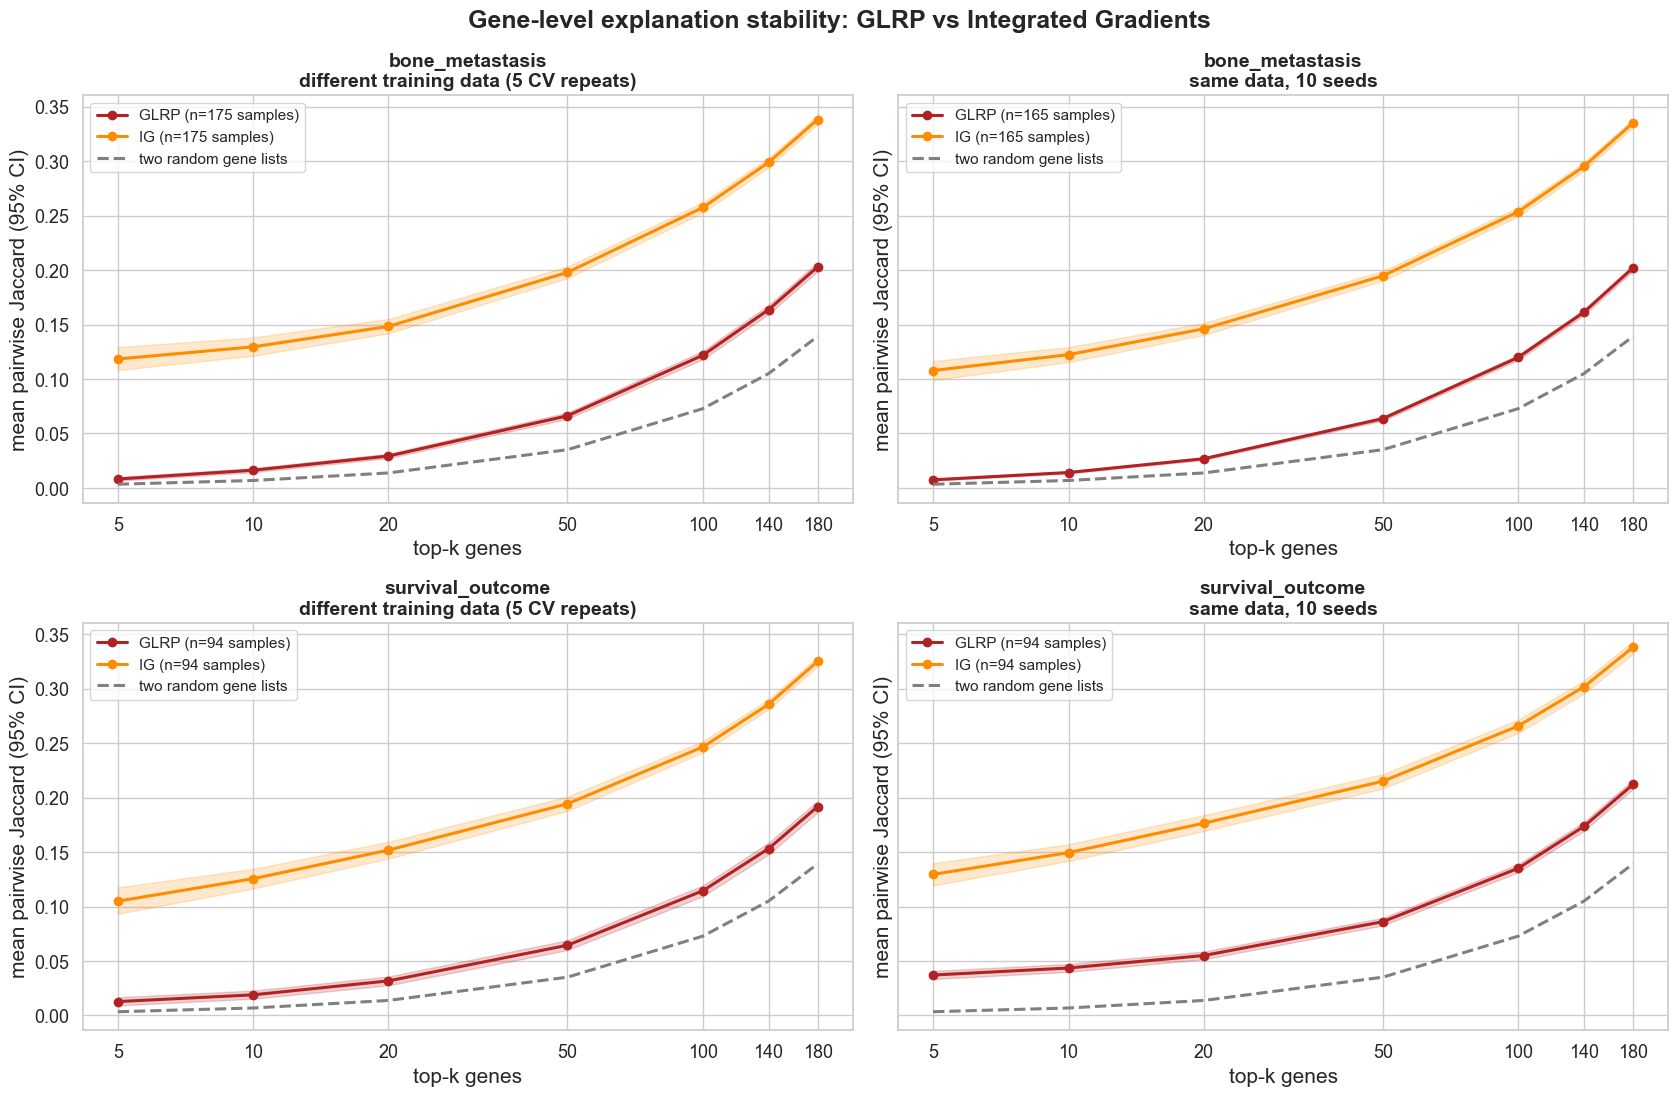

In [39]:
def topk_idx(v, k):
    return set(np.argpartition(-np.abs(v), k - 1)[:k])

def pair_stats(vecs):
    vecs = [v for v in vecs]
    pairs = list(combinations(range(len(vecs)), 2))
    out = {}
    for k in TOPK:
        sets = [topk_idx(v, k) for v in vecs]
        out[f"jac_top{k}"] = np.mean([len(sets[a] & sets[b]) / len(sets[a] | sets[b]) for a, b in pairs])
    ok = [v for v in vecs if np.any(v != 0)]
    sp_ = [spearmanr(np.abs(ok[a]), np.abs(ok[b])).correlation for a, b in combinations(range(len(ok)), 2)]
    out["spearman_abs"] = np.nanmean(sp_) if sp_ else np.nan
    out["n_nondegenerate"] = len(ok)
    return out

stab_rows = []
for (task, family), d in EXPL[EXPL.family.isin(["A", "B"])].groupby(["task", "family"]):
    for sid, g in d.groupby("sample_id"):
        if len(g) < 2:
            continue
        for meth in METHODS:
            st = pair_stats(list(g[meth]))
            stab_rows.append({"task": task, "source": {"A": "different training data (5 CV repeats)",
                                                       "B": "same data, 10 seeds"}[family],
                              "family": family, "method": meth, "sample_id": sid, "y": int(g.y.iloc[0]),
                              "n_models": len(g), "frac_models_correct": g.correct.mean(), **st})
gene_stab = pd.DataFrame(stab_rows)
gene_stab["majority_correct"] = gene_stab.frac_models_correct > 0.5
save_table(gene_stab, "STABILITY_gene_level_per_sample")

def summarize_stability(df, cols, chance=None):
    rows = []
    for (task, family, meth), g in df.groupby(["task", "family", "method"]):
        for c in cols:
            lo, hi = boot_ci(g[c])
            r = {"task": task, "family": family, "method": meth, "metric": c, "n_samples": int(g[c].notna().sum()),
                 "mean": g[c].mean(), "CI95_lo": lo, "CI95_hi": hi, "median": g[c].median()}
            if chance is not None and c in chance:
                r["chance"] = chance[c]; r["fold_over_chance"] = r["mean"] / chance[c]
            rows.append(r)
    return pd.DataFrame(rows)

jac_cols = [f"jac_top{k}" for k in TOPK]
chance = {f"jac_top{k}": expected_random_jaccard(k, N) for k in TOPK}
main = gene_stab[gene_stab.majority_correct]
gene_stab_summary = summarize_stability(main, jac_cols + ["spearman_abs"], chance)
gene_stab_summary_all = summarize_stability(gene_stab, jac_cols + ["spearman_abs"], chance)
save_table(gene_stab_summary, "STABILITY_gene_level_summary_majority_correct")
save_table(gene_stab_summary_all, "STABILITY_gene_level_summary_all_samples")

# paired GLRP vs IG
cmp_rows = []
for (task, family), g in main.groupby(["task", "family"]):
    w = g.pivot_table(index="sample_id", columns="method", values=jac_cols + ["spearman_abs"])
    tmp = []
    for c in jac_cols + ["spearman_abs"]:
        dd = (w[(c, "IG")] - w[(c, "GLRP")]).dropna()
        p = wilcoxon(dd).pvalue if len(dd) > 5 and np.any(dd != 0) else np.nan
        lo, hi = boot_ci(dd)
        tmp.append({"task": task, "family": family, "metric": c, "n_samples": len(dd), "mean_IG_minus_GLRP": dd.mean(),
                    "CI95_lo": lo, "CI95_hi": hi, "wilcoxon_P": p})
    for r, ph in zip(tmp, holm([r["wilcoxon_P"] for r in tmp])):
        r["P_Holm"] = ph
    cmp_rows += tmp
gene_stab_glrp_vs_ig = save_table(pd.DataFrame(cmp_rows), "STABILITY_gene_level_GLRP_vs_IG_paired")
show = gene_stab_summary.pivot_table(index=["task", "family", "metric"], columns="method", values=["mean", "CI95_lo", "CI95_hi"])
order_ = {m: i for i, m in enumerate(jac_cols + ["spearman_abs"])}
show = show.iloc[sorted(range(len(show)), key=lambda i: (show.index[i][0], show.index[i][1], order_[show.index[i][2]]))]
display(show.round(3))
display(gene_stab_glrp_vs_ig.round(4))

fig, axes = plt.subplots(len(TASKS), 2, figsize=(17, 5.6 * len(TASKS)), squeeze=False, sharey=True)
for i, task in enumerate(TASKS):
    for j, family in enumerate(["A", "B"]):
        ax = axes[i, j]
        for meth in METHODS:
            d = gene_stab_summary[(gene_stab_summary.task == task) & (gene_stab_summary.family == family) &
                                  (gene_stab_summary.method == meth) & gene_stab_summary.metric.isin(jac_cols)]
            ks = [int(m.replace("jac_top", "")) for m in d.metric]
            ax.plot(ks, d["mean"], "o-", color=METHOD_COLORS[meth], label=f"{meth} (n={int(d.n_samples.iloc[0])} samples)")
            ax.fill_between(ks, d.CI95_lo, d.CI95_hi, color=METHOD_COLORS[meth], alpha=0.2)
        ax.plot(TOPK, [chance[f"jac_top{k}"] for k in TOPK], "--", color="grey", label="two random gene lists")
        ax.set_xscale("log"); ax.set_xticks(TOPK); ax.set_xticklabels(TOPK)
        ax.set_xlabel("top-k genes"); ax.set_ylabel("mean pairwise Jaccard (95% CI)")
        ax.set_title(f"{task}\n{'different training data (5 CV repeats)' if family == 'A' else 'same data, 10 seeds'}", fontsize=14)
        ax.legend(fontsize=11)
fig.suptitle("Gene-level explanation stability: GLRP vs Integrated Gradients"); fig.tight_layout()
save_fig(fig, "01_gene_level_stability")

## 4. Pathway-level stability (reviewer comment 3)

Two complementary measures, both over KEGG pathways with ≥ 5 genes on the panel:
* **Enrichment-based:** each explanation's top-140 genes are tested for over-representation (hypergeometric, panel background, BH < 0.05), and the resulting significant pathway sets are compared by Jaccard. Reported **conditionally** (pairs where both sets are non-empty) and **unconditionally** (an empty set counts as 0 agreement), together with how often no pathway was significant. This is the v14 measure, now with CIs.
* **Score-based:** pathway score = mean |attribution| of the pathway's panel genes divided by the mean over all genes. This always gives a full ranking, so it has no empty-set problem. Reported as the Spearman correlation of pathway scores between models and the Jaccard of the top-10 pathways, against chance.

The enrichment-based measure depends on whether a top-140 list happens to reach significance. A method that spreads its top genes across many pathways can have perfectly stable explanations and still almost never produce a significant pathway. That is why `frac_no_significant_pathway` is reported, and why the score-based measure is the primary pathway-level result.

KEGG pathways with >= 5 panel genes: 212


CI95_hi        CI95_lo          mean       
method                                                  GLRP     IG    GLRP     IG   GLRP     IG
task             family metric                                                                  
bone_metastasis  A      enrich_jaccard_conditional     0.107  0.212   0.082  0.033  0.094  0.110
                        enrich_jaccard_unconditional   0.057  0.002   0.043  0.000  0.050  0.001
                        frac_no_significant_pathway    0.289  0.934   0.233  0.893  0.263  0.914
                        pathway_score_spearman         0.198  0.539   0.164  0.513  0.181  0.526
                        top10_pathway_jaccard          0.063  0.220   0.050  0.198  0.057  0.209
                 B      enrich_jaccard_conditional     0.132  0.289   0.113  0.174  0.122  0.231
                        enrich_jaccard_unconditional   0.091  0.014   0.077  0.005  0.084  0.009
                        frac_no_significant_pathway    0.183  0.888   0.150  0.842  0.166  0.865
                        pathway_score_spearman         0.194  0.564   0.175  0.542  0.185  0.553
                        top10_pathway_jaccard          0.062  0.244   0.053  0.222  0.057  0.233
survival_outcome A      enrich_jaccard_conditional     0.091  0.382   0.058  0.000  0.074  0.132
                        enrich_jaccard_unconditional   0.047  0.004   0.029  0.000  0.037  0.001
                        frac_no_significant_pathway    0.340  0.936   0.253  0.883  0.296  0.911
                        pathway_score_spearman         0.150  0.544   0.113  0.505  0.132  0.525
                        top10_pathway_jaccard          0.053  0.242   0.041  0.201  0.047  0.219
                 B      enrich_jaccard_conditional     0.154  0.504   0.130  0.219  0.142  0.360
                        enrich_jaccard_unconditional   0.111  0.010   0.089  0.003  0.100  0.006
                        frac_no_significant_pathway    0.190  0.915   0.138  0.854  0.164  0.885
                        pathway_score_spearman         0.226  0.581   0.177  0.556  0.201  0.569
                        top10_pathway_jaccard          0.056  0.227   0.046  0.207  0.051  0.216

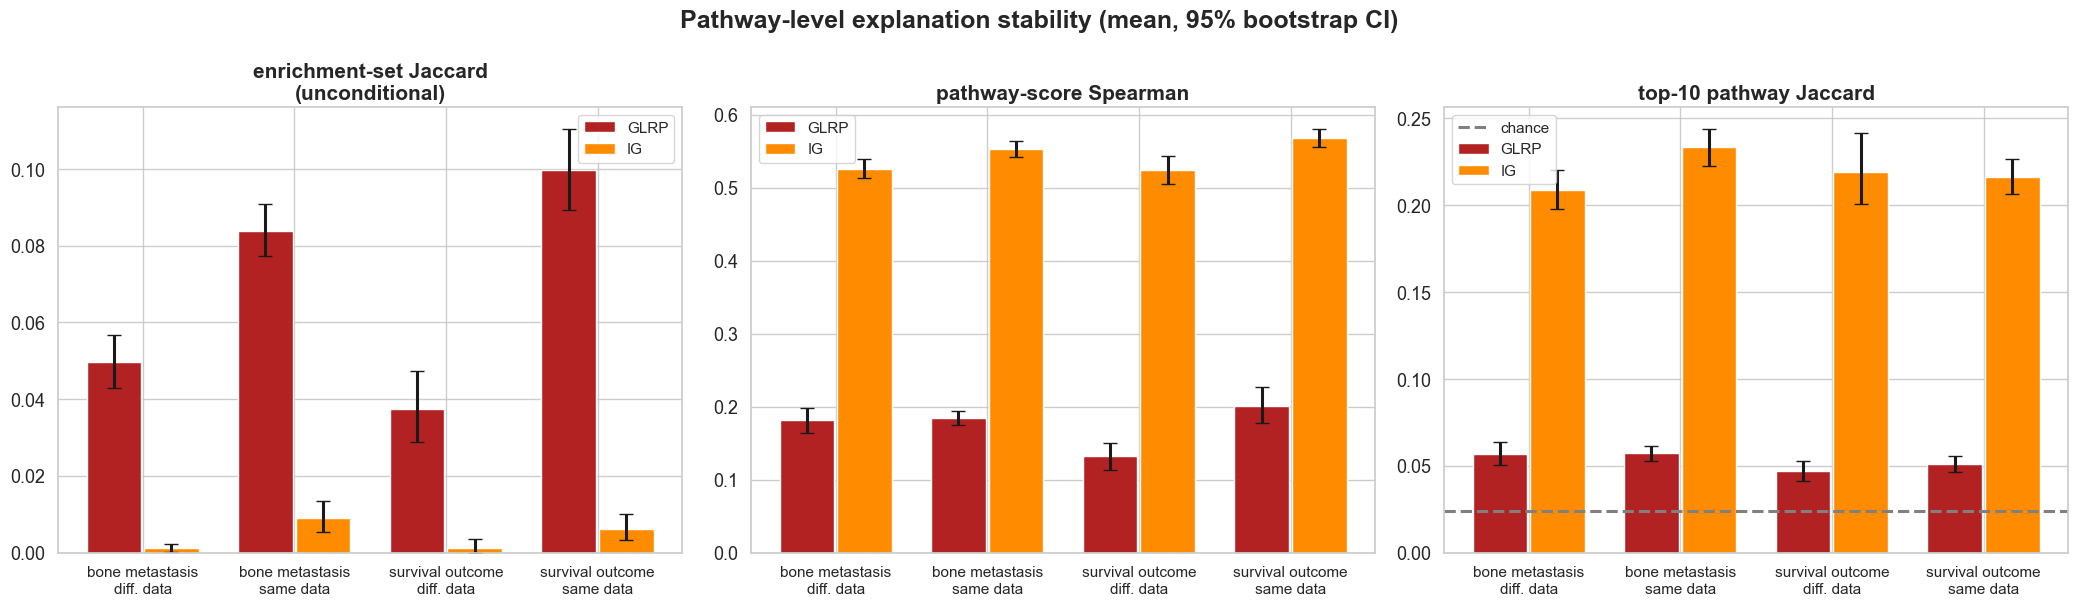

In [40]:
_kegg_path = os.path.join(DATA_DIR, "KEGG_2021_Human.json")
with open(_kegg_path if os.path.exists(_kegg_path) else A1["kegg_library_path"]) as f:
    kegg = json.load(f)
terms = [t for t, g in kegg.items() if len(set(g) & set(gene_list)) >= PATHWAY_MIN_GENES]
TM = np.zeros((len(terms), N), dtype=bool)
for i, t in enumerate(terms):
    TM[i, [GIDX[g] for g in set(kegg[t]) & set(gene_list)]] = True
term_size = TM.sum(1)
print(f"KEGG pathways with >= {PATHWAY_MIN_GENES} panel genes: {len(terms)}")

def sig_terms(v, k=PATHWAY_TOPK_GENES, alpha=0.05):
    q = np.zeros(N, dtype=bool); q[list(topk_idx(v, k))] = True
    kk = TM[:, q].sum(1)
    p = hypergeom.sf(kk - 1, N, term_size, k)
    tested = kk >= 1
    sig = np.zeros(len(terms), dtype=bool)
    if tested.any():
        sig[np.where(tested)[0]] = multipletests(p[tested], method="fdr_bh")[1] < alpha
    return frozenset(np.where(sig)[0])

def pathway_scores(v):
    a = np.abs(v); m = a.mean()
    return (TM @ a) / term_size / (m if m > 0 else 1)

pw_rows = []
for (task, family), d in EXPL[EXPL.family.isin(["A", "B"])].groupby(["task", "family"]):
    for sid, g in d.groupby("sample_id"):
        if len(g) < 2:
            continue
        for meth in METHODS:
            V = list(g[meth]); pairs = list(combinations(range(len(V)), 2))
            S = [sig_terms(v) for v in V]
            cond = [len(S[a] & S[b]) / len(S[a] | S[b]) for a, b in pairs if S[a] and S[b]]
            unc = [len(S[a] & S[b]) / len(S[a] | S[b]) if (S[a] and S[b]) else 0.0 for a, b in pairs]
            P = [pathway_scores(v) for v in V if np.any(v != 0)]
            sp_ = [spearmanr(P[a], P[b]).correlation for a, b in combinations(range(len(P)), 2)]
            tops = [set(np.argsort(-p)[:PATHWAY_TOP_TERMS]) for p in P]
            tj = [len(tops[a] & tops[b]) / len(tops[a] | tops[b]) for a, b in combinations(range(len(tops)), 2)]
            pw_rows.append({"task": task, "family": family, "method": meth, "sample_id": sid, "y": int(g.y.iloc[0]),
                            "frac_models_correct": g.correct.mean(), "frac_no_significant_pathway": np.mean([len(s) == 0 for s in S]),
                            "mean_n_significant_pathways": np.mean([len(s) for s in S]),
                            "enrich_jaccard_conditional": np.mean(cond) if cond else np.nan,
                            "enrich_jaccard_unconditional": np.mean(unc),
                            "pathway_score_spearman": np.nanmean(sp_) if sp_ else np.nan,
                            f"top{PATHWAY_TOP_TERMS}_pathway_jaccard": np.mean(tj) if tj else np.nan})
pw_stab = pd.DataFrame(pw_rows)
pw_stab["majority_correct"] = pw_stab.frac_models_correct > 0.5
save_table(pw_stab, "STABILITY_pathway_level_per_sample")
pw_cols = ["enrich_jaccard_conditional", "enrich_jaccard_unconditional", "frac_no_significant_pathway",
           "pathway_score_spearman", f"top{PATHWAY_TOP_TERMS}_pathway_jaccard"]
pw_chance = {f"top{PATHWAY_TOP_TERMS}_pathway_jaccard": expected_random_jaccard(PATHWAY_TOP_TERMS, len(terms))}
pw_summary = save_table(summarize_stability(pw_stab[pw_stab.majority_correct], pw_cols, pw_chance),
                        "STABILITY_pathway_level_summary")
display(pw_summary.pivot_table(index=["task", "family", "metric"], columns="method", values=["mean", "CI95_lo", "CI95_hi"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(21, 6.2))
plot_metrics = [("enrich_jaccard_unconditional", "enrichment-set Jaccard\n(unconditional)"),
                ("pathway_score_spearman", "pathway-score Spearman"),
                (f"top{PATHWAY_TOP_TERMS}_pathway_jaccard", f"top-{PATHWAY_TOP_TERMS} pathway Jaccard")]
for ax, (m, lab) in zip(axes, plot_metrics):
    d = pw_summary[pw_summary.metric == m].copy()
    d["group"] = d.task.str.replace("_", " ") + "\n" + d.family.map({"A": "diff. data", "B": "same data"})
    x = np.arange(d.group.nunique()); groups = list(dict.fromkeys(d.group))
    for k, meth in enumerate(METHODS):
        dm = d[d.method == meth].set_index("group").reindex(groups)
        ax.bar(x + (k - 0.5) * 0.38, dm["mean"], width=0.36, color=METHOD_COLORS[meth], label=meth,
               yerr=[dm["mean"] - dm.CI95_lo, dm.CI95_hi - dm["mean"]], capsize=5)
    if m in pw_chance:
        ax.axhline(pw_chance[m], color="grey", ls="--", label="chance")
    ax.set_xticks(x); ax.set_xticklabels(groups, fontsize=11); ax.set_title(lab, fontsize=15); ax.legend(fontsize=11)
fig.suptitle("Pathway-level explanation stability (mean, 95% bootstrap CI)"); fig.tight_layout()
save_fig(fig, "02_pathway_level_stability")

## 5. Deletion (perturbation) test across all budgets (reviewer comment 3)

For every correctly classified test sample of the repeat-0 primary models (5 folds, ~all samples once), the top-k genes by |attribution| are replaced and the drop in the true-class probability is measured. This is compared with 50 random k-gene sets (shared by both methods) and with the bottom-k genes. Budgets k = 1 … 500. Replacement values are the fold's **training median** (primary) or **zero** (check). IG's baseline is the training mean, which is close to the median replacement and could favour IG, so the zero replacement is shown too.

* **Per budget:** mean (top − random) drop with bootstrap 95% CI, the fraction of samples where top > random, and a one-sided Wilcoxon test, Holm-adjusted across the 12 budgets.
* **AOPC** (area over the perturbation curve) = the mean drop across budgets per sample. It summarizes the whole curve in one number per sample and is compared between methods by a paired Wilcoxon test.

This tests faithfulness **to the model**. It says nothing about whether the genes drive disease.

  deletion: bone_metastasis done


  deletion: survival_outcome done


P_Holm         fraction_top_gt_random         mean_top_minus_random        
method                     GLRP      IG                   GLRP      IG                  GLRP      IG
task             budget                                                                             
bone_metastasis  1       0.4091  0.0000                 0.4630  0.7284                0.0001  0.0022
                 2       0.2956  0.0000                 0.5062  0.7778                0.0003  0.0035
                 5       0.0791  0.0000                 0.5617  0.8519                0.0004  0.0065
                 10      0.0012  0.0000                 0.5679  0.8457                0.0009  0.0086
                 20      0.0000  0.0000                 0.6420  0.8519                0.0020  0.0119
                 50      0.0000  0.0000                 0.7222  0.8210                0.0049  0.0154
                 100     0.0000  0.0000                 0.7840  0.8519                0.0078  0.0181
                 140     0.0000  0.0000                 0.7407  0.8704                0.0091  0.0183
                 200     0.0000  0.0000                 0.7284  0.8765                0.0091  0.0175
                 300     0.0000  0.0000                 0.6914  0.8457                0.0092  0.0156
                 400     0.0000  0.0000                 0.6790  0.8457                0.0076  0.0128
                 500     0.0010  0.0000                 0.5988  0.8580                0.0056  0.0095
survival_outcome 1       0.0271  0.0003                 0.5926  0.6667                0.0003  0.0022
                 2       0.0051  0.0002                 0.5802  0.7037                0.0008  0.0039
                 5       0.0025  0.0000                 0.6296  0.7160                0.0017  0.0080
                 10      0.0011  0.0000                 0.6296  0.7654                0.0030  0.0119
                 20      0.0001  0.0000                 0.6914  0.7778                0.0056  0.0162
                 50      0.0000  0.0000                 0.7284  0.8148                0.0097  0.0219
                 100     0.0000  0.0000                 0.7778  0.7654                0.0120  0.0253
                 140     0.0000  0.0000                 0.7284  0.8025                0.0127  0.0258
                 200     0.0000  0.0000                 0.6667  0.8148                0.0113  0.0250
                 300     0.0005  0.0000                 0.6914  0.8519                0.0072  0.0232
                 400     0.0039  0.0000                 0.5926  0.8519                0.0051  0.0190
                 500     0.0359  0.0000                 0.5802  0.8765                0.0024  0.0139

,task,baseline,method,n_samples,AOPC_top_minus_random,CI95_lo,CI95_hi,P_gt_0_wilcoxon
0,bone_metastasis,train_median,GLRP,162,0.0048,0.0032,0.0065,0.0000
1,bone_metastasis,train_median,IG,162,0.0117,0.0088,0.0150,0.0000
2,bone_metastasis,train_median,IG minus GLRP,162,0.0069,0.0041,0.0097,0.0000
3,bone_metastasis,zero,GLRP,162,0.0256,0.0212,0.0303,0.0000
4,bone_metastasis,zero,IG,162,0.0141,0.0105,0.0178,0.0000
5,bone_metastasis,zero,IG minus GLRP,162,-0.0116,-0.0167,-0.0065,0.0000
6,survival_outcome,train_median,GLRP,81,0.0060,0.0039,0.0083,0.0000
7,survival_outcome,train_median,IG,81,0.0164,0.0117,0.0214,0.0000
8,survival_outcome,train_median,IG minus GLRP,81,0.0104,0.0066,0.0146,0.0000
9,survival_outcome,zero,GLRP,81,0.0327,0.0226,0.0431,0.0000


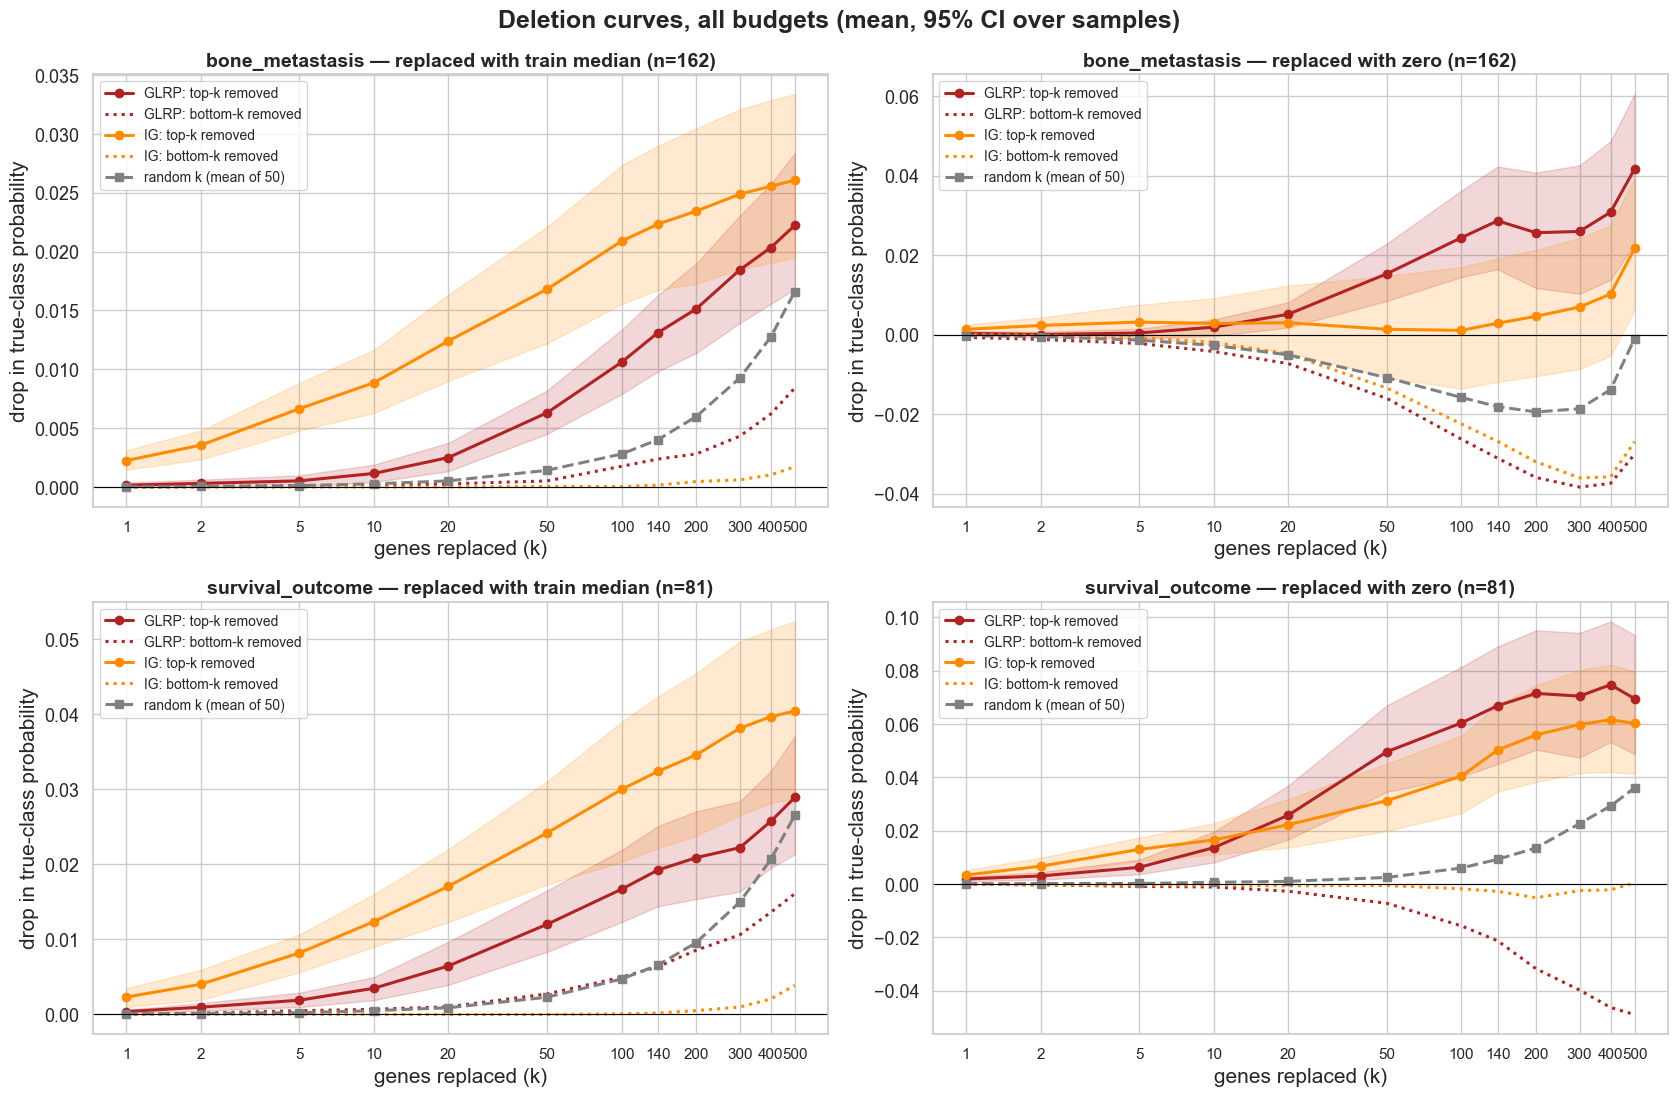

In [41]:
DEL_PATH = os.path.join(CACHE_DIR, f"deletion_results_{CACHE_KEY}_{'-'.join(map(str, DELETION_BUDGETS))}_{N_RANDOM_DELETION}.pkl")
if os.path.exists(DEL_PATH):
    deletion = pd.read_pickle(DEL_PATH)
else:
    rows = []; rng = np.random.default_rng(0)
    for task in TASKS:
        A_rec = EXPL[(EXPL.family == "A") & (EXPL.task == task) & (EXPL.repeat == 0) & EXPL.correct]
        for p in [p for p in PRIMARY_PARTITIONS[task] if p["repeat"] == 0]:
            model = GraphCNN(N, K=7).to(DEVICE); model.load_state_dict(torch.load(os.path.join(CACHE_DIR, f"model_A_{task}_rep0_fold{p['fold']}_{CACHE_KEY}.pt"), map_location=DEVICE))
            model.eval()
            Xtr = prep_fold(p["train"], p["train"]); Xte = prep_fold(p["train"], p["test"])
            fills = {"train_median": np.median(Xtr, 0).astype(np.float32), "zero": np.zeros(N, np.float32)}
            pos = {s: i for i, s in enumerate(p["test"])}
            for r in A_rec[A_rec.fold == p["fold"]].itertuples():
                x = Xte[pos[r.sample_id]]; cls = r.y
                with torch.no_grad():
                    base = torch.softmax(model(L_dense, torch.tensor(x[None], device=DEVICE)), 1)[0, cls].item()
                orders = {m: np.argsort(-np.abs(getattr(r, m))) for m in METHODS}
                for b in DELETION_BUDGETS:
                    rsets = [rng.choice(N, b, replace=False) for _ in range(N_RANDOM_DELETION)]
                    for bl, fv in fills.items():
                        batch = [x.copy() for _ in range(N_RANDOM_DELETION + 2 * len(METHODS))]
                        for q, gs in enumerate(rsets):
                            batch[q][gs] = fv[gs]
                        for mi, m in enumerate(METHODS):
                            t_, b_ = orders[m][:b], orders[m][-b:]
                            batch[N_RANDOM_DELETION + 2 * mi][t_] = fv[t_]
                            batch[N_RANDOM_DELETION + 2 * mi + 1][b_] = fv[b_]
                        with torch.no_grad():
                            pr = torch.softmax(model(L_dense, torch.tensor(np.stack(batch), device=DEVICE)), 1)[:, cls].cpu().numpy()
                        rand_drop = base - pr[:N_RANDOM_DELETION]
                        for mi, m in enumerate(METHODS):
                            td, bd = base - pr[N_RANDOM_DELETION + 2 * mi], base - pr[N_RANDOM_DELETION + 2 * mi + 1]
                            rows.append({"task": task, "method": m, "sample_id": r.sample_id, "y": cls, "fold": p["fold"],
                                         "budget": b, "baseline": bl, "base_prob": base, "top_drop": td, "bottom_drop": bd,
                                         "random_mean_drop": rand_drop.mean(), "top_minus_random": td - rand_drop.mean(),
                                         "top_pct_among_random": float((rand_drop < td).mean())})
        print(f"  deletion: {task} done", flush=True)
    deletion = pd.DataFrame(rows); deletion.to_pickle(DEL_PATH)
save_table(deletion, "DELETION_per_sample_budget")

del_rows = []
for (task, meth, bl), g in deletion.groupby(["task", "method", "baseline"]):
    tmp = []
    for b, gb in g.groupby("budget"):
        d = gb.top_minus_random.to_numpy(); lo, hi = boot_ci(d); flo, fhi = boot_ci((d > 0).astype(float))
        try:
            p = wilcoxon(d, alternative="greater").pvalue if np.any(d != 0) else np.nan
        except ValueError:
            p = np.nan
        tmp.append({"task": task, "method": meth, "baseline": bl, "budget": b, "n_samples": len(d),
                    "mean_top_drop": gb.top_drop.mean(), "mean_random_drop": gb.random_mean_drop.mean(),
                    "mean_bottom_drop": gb.bottom_drop.mean(), "mean_top_minus_random": d.mean(), "CI95_lo": lo, "CI95_hi": hi,
                    "fraction_top_gt_random": (d > 0).mean(), "fraction_CI95_lo": flo, "fraction_CI95_hi": fhi,
                    "median_percentile_vs_random": gb.top_pct_among_random.median(), "wilcoxon_P_one_sided": p})
    for r, ph in zip(tmp, holm([r["wilcoxon_P_one_sided"] for r in tmp])):
        r["P_Holm"] = ph
        r["passes"] = bool((ph < 0.05) and (r["fraction_top_gt_random"] >= 0.75) and (r["mean_top_drop"] > r["mean_bottom_drop"]))
    del_rows += tmp
deletion_summary = save_table(pd.DataFrame(del_rows), "DELETION_summary_all_budgets")

aopc = deletion.groupby(["task", "method", "baseline", "sample_id"]).agg(
    AOPC_top=("top_drop", "mean"), AOPC_random=("random_mean_drop", "mean"), AOPC_bottom=("bottom_drop", "mean")).reset_index()
aopc["AOPC_top_minus_random"] = aopc.AOPC_top - aopc.AOPC_random
aopc_rows = []
for (task, bl), g in aopc.groupby(["task", "baseline"]):
    w = g.pivot(index="sample_id", columns="method", values="AOPC_top_minus_random")
    for meth in METHODS:
        lo, hi = boot_ci(w[meth])
        aopc_rows.append({"task": task, "baseline": bl, "method": meth, "n_samples": len(w), "AOPC_top_minus_random": w[meth].mean(),
                          "CI95_lo": lo, "CI95_hi": hi,
                          "P_gt_0_wilcoxon": wilcoxon(w[meth], alternative="greater").pvalue if np.any(w[meth] != 0) else np.nan})
    dd = w["IG"] - w["GLRP"]; lo, hi = boot_ci(dd)
    aopc_rows.append({"task": task, "baseline": bl, "method": "IG minus GLRP", "n_samples": len(w), "AOPC_top_minus_random": dd.mean(),
                      "CI95_lo": lo, "CI95_hi": hi, "P_gt_0_wilcoxon": wilcoxon(dd).pvalue if np.any(dd != 0) else np.nan})
aopc_summary = save_table(pd.DataFrame(aopc_rows), "DELETION_AOPC_summary")
display(deletion_summary[deletion_summary.baseline == "train_median"].pivot_table(
    index=["task", "budget"], columns="method", values=["mean_top_minus_random", "fraction_top_gt_random", "P_Holm"]).round(4))
display(aopc_summary.round(4))

fig, axes = plt.subplots(len(TASKS), 2, figsize=(17, 5.6 * len(TASKS)), squeeze=False)
for i, task in enumerate(TASKS):
    for j, bl in enumerate(["train_median", "zero"]):
        ax = axes[i, j]
        for meth in METHODS:
            d = deletion_summary[(deletion_summary.task == task) & (deletion_summary.method == meth) & (deletion_summary.baseline == bl)]
            ax.plot(d.budget, d.mean_top_drop, "o-", color=METHOD_COLORS[meth], label=f"{meth}: top-k removed")
            g = deletion[(deletion.task == task) & (deletion.method == meth) & (deletion.baseline == bl)]
            ci = g.groupby("budget").top_drop.apply(lambda v: pd.Series(boot_ci(v.values, n_boot=500), index=["lo", "hi"])).unstack()
            ax.fill_between(ci.index, ci.lo, ci.hi, color=METHOD_COLORS[meth], alpha=0.18)
            ax.plot(d.budget, d.mean_bottom_drop, ":", color=METHOD_COLORS[meth], label=f"{meth}: bottom-k removed")
        d = deletion_summary[(deletion_summary.task == task) & (deletion_summary.method == "GLRP") & (deletion_summary.baseline == bl)]
        ax.plot(d.budget, d.mean_random_drop, "s--", color="grey", label=f"random k (mean of {N_RANDOM_DELETION})")
        ax.axhline(0, color="black", lw=0.8); ax.set_xscale("log")
        ax.set_xticks(DELETION_BUDGETS); ax.set_xticklabels(DELETION_BUDGETS, fontsize=11)
        ax.set_xlabel("genes replaced (k)"); ax.set_ylabel("drop in true-class probability")
        ax.set_title(f"{task} — replaced with {bl.replace('_', ' ')} (n={g.sample_id.nunique()})", fontsize=14)
        ax.legend(fontsize=10)
fig.suptitle("Deletion curves, all budgets (mean, 95% CI over samples)"); fig.tight_layout()
save_fig(fig, "03_deletion_curves_all_budgets")

## 6. Label-shuffled explanation control (reviewer comment 5)

If an attribution method reflects what the model learned from the labels, explanations from **real-label** models should agree with each other more than with explanations from **label-shuffled** models trained on the same samples.

For each repeat-0 test sample that the real models classify correctly:
* real–real similarity = mean Jaccard among the 10 seed models (family B);
* real–null similarity = mean Jaccard between those 10 models and the 5 label-shuffled models (family N, checkpoint and threshold selected on shuffled validation labels).

The cell also measures how strongly each method's ranking follows the **input expression itself** (Spearman of |attribution| with x). A method whose top genes are mostly the highest-expressed genes would pass a stability test for the wrong reason.

,task,method,top_k,n_samples,real_real_jaccard,real_null_jaccard,difference,diff_CI95_lo,diff_CI95_hi,wilcoxon_P,chance,spearman_attribution_vs_input,P_Holm
0,bone_metastasis,GLRP,20,165,0.0268,0.0269,-0.0001,-0.0017,0.0015,0.3293,0.0138,0.3709,0.9880
1,bone_metastasis,GLRP,140,165,0.1614,0.1558,0.0055,0.0030,0.0081,0.0001,0.1049,0.3709,0.0004
2,bone_metastasis,IG,20,165,0.1461,0.1168,0.0293,0.0253,0.0331,0.0000,0.0138,-0.0882,0.0000
3,bone_metastasis,IG,140,165,0.2952,0.2800,0.0151,0.0135,0.0169,0.0000,0.1049,-0.0882,0.0000
4,survival_outcome,GLRP,20,94,0.0550,0.0843,-0.0293,-0.0413,-0.0176,0.9995,0.0138,0.3601,1.0000
5,survival_outcome,GLRP,140,94,0.1736,0.1949,-0.0213,-0.0322,-0.0103,0.9980,0.1049,0.3601,1.0000
6,survival_outcome,IG,20,94,0.1765,0.1174,0.0591,0.0522,0.0657,0.0000,0.0138,-0.1043,0.0000
7,survival_outcome,IG,140,94,0.3017,0.2662,0.0356,0.0297,0.0413,0.0000,0.1049,-0.1043,0.0000


Held-out AUC of the label-shuffled models used here (should be near 0.5):


,mean,min,max
task,,,
bone_metastasis,0.527,0.086,0.839
survival_outcome,0.481,0.164,0.758


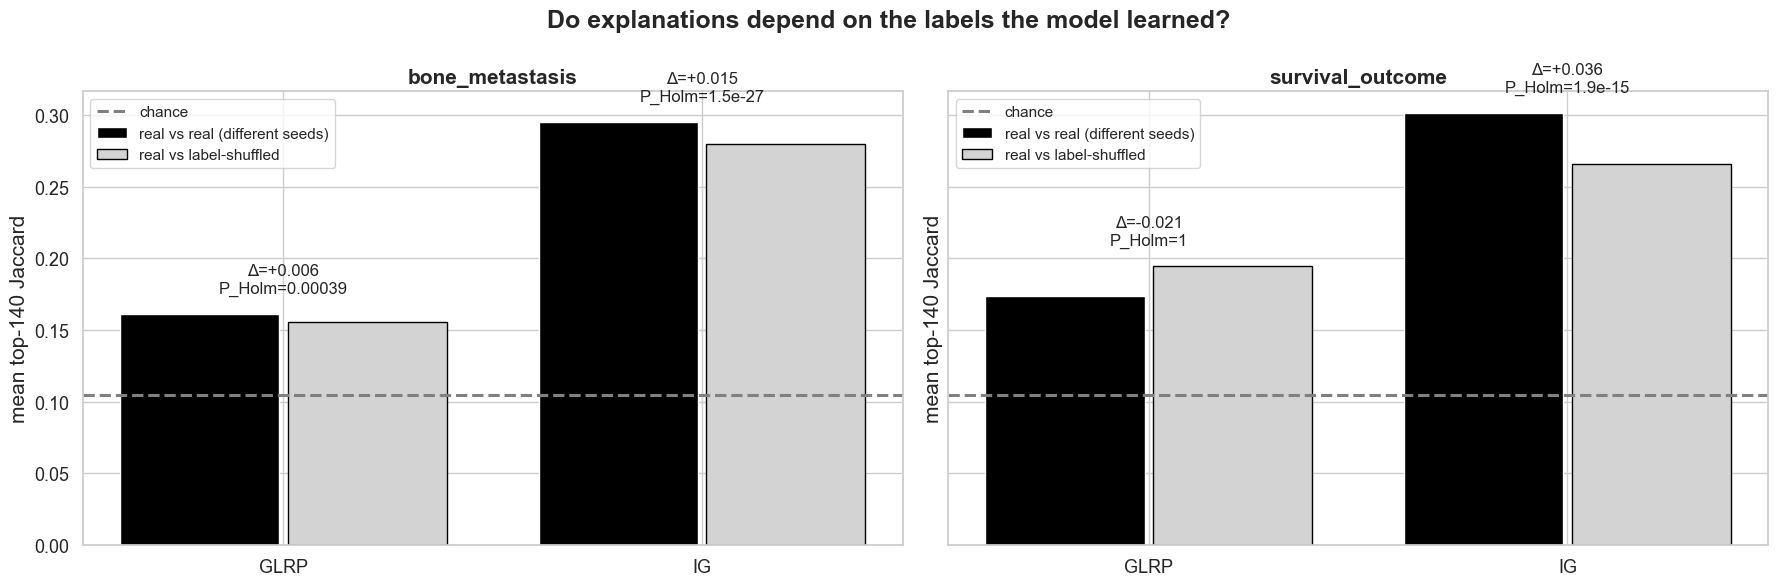

In [42]:
ctrl_rows = []
for task in TASKS:
    B_ = EXPL[(EXPL.family == "B") & (EXPL.task == task)]; N_ = EXPL[(EXPL.family == "N") & (EXPL.task == task)]
    Xby = {}
    for p in [p for p in PRIMARY_PARTITIONS[task] if p["repeat"] == 0]:
        Xte = prep_fold(p["train"], p["test"])
        for i, s in enumerate(p["test"]):
            Xby[s] = Xte[i]
    for sid, gb in B_.groupby("sample_id"):
        if gb.correct.mean() <= 0.5:
            continue
        gn = N_[N_.sample_id == sid]
        for meth in METHODS:
            Rb, Rn = list(gb[meth]), list(gn[meth])
            for k in [20, 140]:
                sb, sn = [topk_idx(v, k) for v in Rb], [topk_idx(v, k) for v in Rn]
                rr = np.mean([len(sb[a] & sb[b]) / len(sb[a] | sb[b]) for a, b in combinations(range(len(sb)), 2)])
                rn = np.mean([len(a & b) / len(a | b) for a in sb for b in sn])
                ctrl_rows.append({"task": task, "method": meth, "sample_id": sid, "k": k, "real_real": rr, "real_null": rn,
                                  "difference": rr - rn})
            ctrl_rows[-1]["spearman_attr_vs_input"] = np.nanmean([spearmanr(np.abs(v), Xby[sid]).correlation for v in Rb if np.any(v != 0)])
label_ctrl = pd.DataFrame(ctrl_rows)
save_table(label_ctrl, "LABEL_SHUFFLE_explanations_per_sample")
lc_rows = []
for (task, meth, k), g in label_ctrl.groupby(["task", "method", "k"]):
    lo, hi = boot_ci(g.difference)
    lc_rows.append({"task": task, "method": meth, "top_k": k, "n_samples": len(g), "real_real_jaccard": g.real_real.mean(),
                    "real_null_jaccard": g.real_null.mean(), "difference": g.difference.mean(), "diff_CI95_lo": lo, "diff_CI95_hi": hi,
                    "wilcoxon_P": wilcoxon(g.difference, alternative="greater").pvalue if np.any(g.difference != 0) else np.nan,
                    "chance": expected_random_jaccard(k, N),
                    "spearman_attribution_vs_input": label_ctrl[(label_ctrl.task == task) & (label_ctrl.method == meth)].spearman_attr_vs_input.mean()})
label_ctrl_summary = pd.DataFrame(lc_rows); label_ctrl_summary["P_Holm"] = holm(label_ctrl_summary.wilcoxon_P)
save_table(label_ctrl_summary, "LABEL_SHUFFLE_explanations_summary")
display(label_ctrl_summary.round(4))
nullA = MODELS_INFO[MODELS_INFO.family == "N"].groupby("task").test_AUC.agg(["mean", "min", "max"])
print("Held-out AUC of the label-shuffled models used here (should be near 0.5):"); display(nullA.round(3))

fig, axes = plt.subplots(1, len(TASKS), figsize=(9 * len(TASKS), 6), squeeze=False, sharey=True)
for ax, task in zip(axes[0], TASKS):
    d = label_ctrl_summary[(label_ctrl_summary.task == task) & (label_ctrl_summary.top_k == 140)]
    x = np.arange(len(METHODS))
    ax.bar(x - 0.2, d.real_real_jaccard, 0.38, color="black", label="real vs real (different seeds)")
    ax.bar(x + 0.2, d.real_null_jaccard, 0.38, color="lightgrey", edgecolor="black", label="real vs label-shuffled")
    ax.axhline(expected_random_jaccard(140, N), color="grey", ls="--", label="chance")
    for xi, r in zip(x, d.itertuples()):
        ax.text(xi, max(r.real_real_jaccard, r.real_null_jaccard) + 0.015, f"Δ={r.difference:+.3f}\nP_Holm={r.P_Holm:.2g}",
                ha="center", fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(METHODS); ax.set_ylabel("mean top-140 Jaccard"); ax.set_title(task, fontsize=15)
    ax.legend(fontsize=11, loc="upper left")
fig.suptitle("Do explanations depend on the labels the model learned?"); fig.tight_layout()
save_fig(fig, "04_label_shuffle_explanation_control")

## 7. Tissue-composition attribution (reviewer comment 4)

For every correctly classified family-A explanation, each compartment gets the **share of total |attribution|** carried by its marker genes. This share is compared with 1,000 random gene sets of the same size, giving an enrichment ratio and an empirical P per explanation. Results are summarized per task, method and class, with bootstrap CIs, and the bone class is compared with the non-bone class.

The final table combines these attribution results with Part 2's composition-adjusted classification results.

method                                     GLRP          IG       
class                                         0     1     0      1
task             compartment                                      
bone_metastasis  B cell                    0.49  0.46  0.99   0.83
                 Bone matrix / osteoblast  0.75  1.34  3.30   7.83
                 Endothelial               0.91  0.91  0.62   0.54
                 Erythroid (marrow)        0.67  1.75  3.63  11.80
                 Fibroblast / stroma       1.20  1.17  0.75   0.57
                 Macrophage / monocyte     1.14  1.12  1.05   1.63
                 NK / cytotoxic            0.60  0.68  0.84   0.98
                 Osteoclast                0.80  1.60  2.59   7.59
                 T cell                    0.79  0.73  0.87   0.72
survival_outcome B cell                    0.52  0.50  0.65   0.84
                 Bone matrix / osteoblast  0.82  0.87  1.92   1.63
                 Endothelial               0.78  0.75  0.60   0.49
                 Erythroid (marrow)        1.03  0.88  1.13   1.13
                 Fibroblast / stroma       0.92  1.19  0.71   0.79
                 Macrophage / monocyte     0.95  0.83  0.75   0.63
                 NK / cytotoxic            0.55  0.52  0.70   0.82
                 Osteoclast                0.81  1.14  1.96   0.96
                 T cell                    0.69  0.68  0.64   0.76

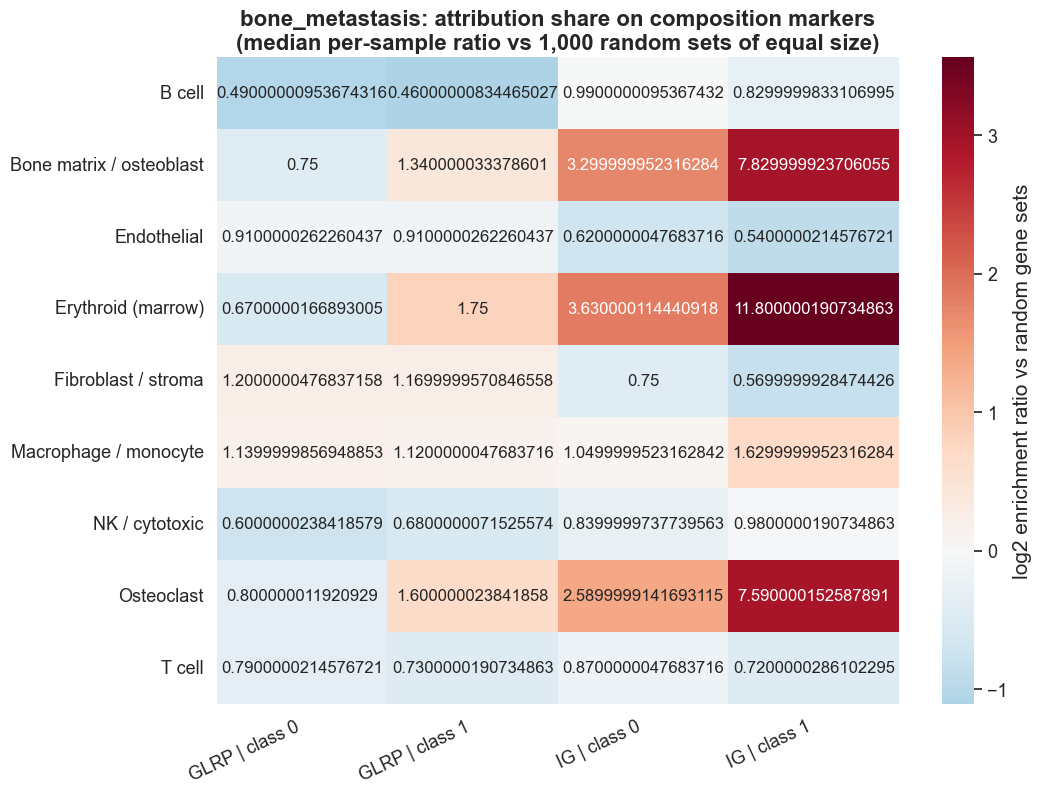

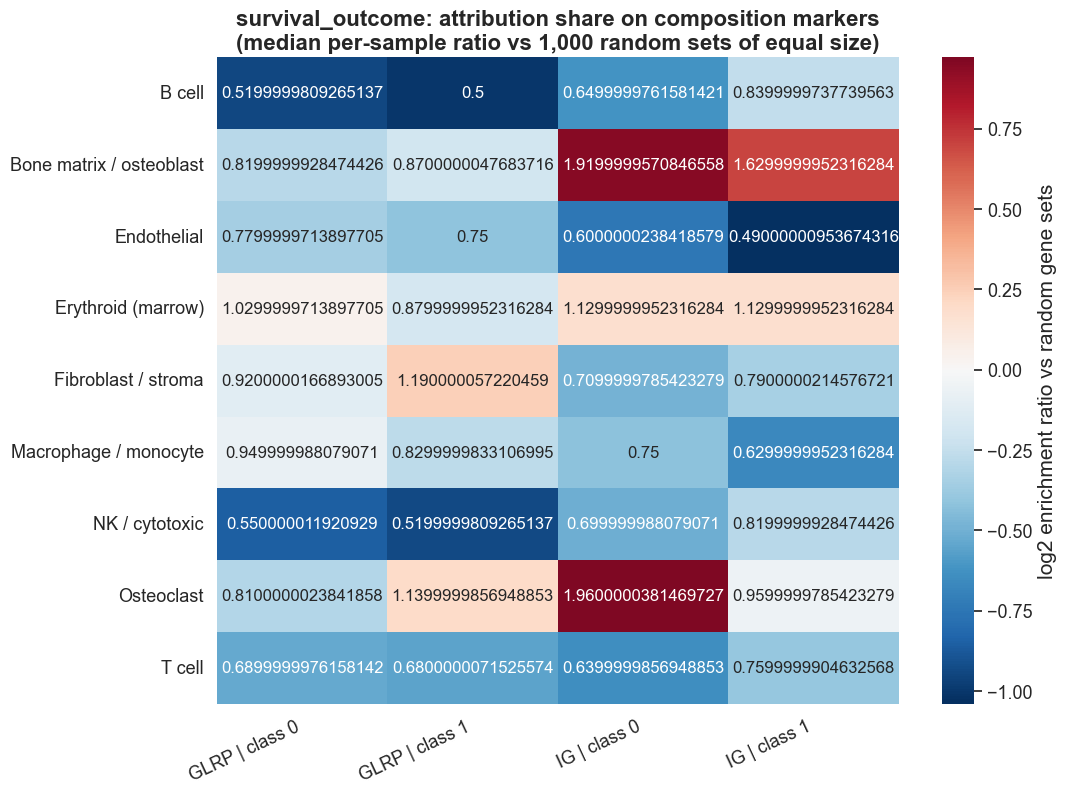

,task,method,bone/marrow compartments with median enrichment > 1.5 (class 1),"max median enrichment (bone/marrow, class 1)",Graph-CNN AUC original,Graph-CNN AUC markers neutralized,Graph-CNN AUC residualized,Graph-CNN AUC host-residualized,composition-scores-only AUC,host-composition-scores-only AUC
0,bone_metastasis,GLRP,"Erythroid (marrow), Osteoclast",1.753,0.883,0.886,0.670,0.758,0.911,0.860
1,bone_metastasis,IG,"Bone matrix / osteoblast, Erythroid (marrow), Osteoclast",11.803,0.883,0.886,0.670,0.758,0.911,0.860
2,survival_outcome,GLRP,none,1.144,0.693,0.721,0.697,0.705,0.419,0.422
3,survival_outcome,IG,Bone matrix / osteoblast,1.625,0.693,0.721,0.697,0.705,0.419,0.422


In [43]:
rng = np.random.default_rng(1)
comp_idx = {c: np.array([GIDX[g] for g in gs if g in GIDX]) for c, gs in comp_markers.items()}
null_sets = {c: np.array([rng.choice(N, len(ix), replace=False) for _ in range(N_PERM_COMPOSITION)]) for c, ix in comp_idx.items()}
A_ok = EXPL[(EXPL.family == "A") & EXPL.correct]
ca_rows = []
for meth in METHODS:
    M = np.abs(np.stack(A_ok[meth].values)); tot = M.sum(1, keepdims=True); tot[tot == 0] = np.nan
    S = M / tot
    for c, ix in comp_idx.items():
        obs = S[:, ix].sum(1)
        nul = S[:, null_sets[c]].sum(2)            # samples x permutations
        ratio = obs / np.nanmean(nul, 1)
        pval = (1 + (nul >= obs[:, None]).sum(1)) / (N_PERM_COMPOSITION + 1)
        for i, r in enumerate(A_ok.itertuples()):
            ca_rows.append({"task": r.task, "method": meth, "compartment": c, "y": r.y, "sample_id": r.sample_id,
                            "repeat": r.repeat, "share": obs[i], "enrichment_ratio": ratio[i], "P": pval[i]})
comp_attr = pd.DataFrame(ca_rows)
save_table(comp_attr, "COMPOSITION_attribution_per_explanation")
cs_rows = []
for (task, meth, c), g in comp_attr.groupby(["task", "method", "compartment"]):
    for y_, gy in g.groupby("y"):
        per_sample = gy.groupby("sample_id").enrichment_ratio.mean()
        lo, hi = boot_ci(per_sample, stat=np.median)
        cs_rows.append({"task": task, "method": meth, "compartment": c, "class": int(y_), "n_samples": len(per_sample),
                        "n_markers": len(comp_idx[c]), "median_enrichment_ratio": per_sample.median(), "CI95_lo": lo, "CI95_hi": hi,
                        "fraction_explanations_P<0.05": (gy.P < 0.05).mean()})
    a = g[g.y == 1].groupby("sample_id").enrichment_ratio.mean(); b = g[g.y == 0].groupby("sample_id").enrichment_ratio.mean()
    if len(a) > 2 and len(b) > 2:
        cs_rows.append({"task": task, "method": meth, "compartment": c, "class": "class1 vs class0",
                        "n_samples": len(a) + len(b), "n_markers": len(comp_idx[c]),
                        "median_enrichment_ratio": a.median() - b.median(), "CI95_lo": np.nan, "CI95_hi": np.nan,
                        "fraction_explanations_P<0.05": mannwhitneyu(a, b).pvalue})
comp_attr_summary = save_table(pd.DataFrame(cs_rows), "COMPOSITION_attribution_summary")
display(comp_attr_summary[comp_attr_summary["class"] != "class1 vs class0"].pivot_table(
    index=["task", "compartment"], columns=["method", "class"], values="median_enrichment_ratio").round(2))

d = comp_attr_summary[(comp_attr_summary["class"] != "class1 vs class0")].copy()
d["col"] = d.method + " | class " + d["class"].astype(str)
for task in TASKS:
    hm = d[d.task == task].pivot_table(index="compartment", columns="col", values="median_enrichment_ratio")
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(hm) + 3))
    sns.heatmap(np.log2(hm.clip(lower=0.05)), annot=hm.round(2), fmt="", cmap="RdBu_r", center=0, ax=ax, annot_kws={"fontsize": 12},
                cbar_kws={"label": "log2 enrichment ratio vs random gene sets"})
    ax.set_title(f"{task}: attribution share on composition markers\n(median per-sample ratio vs 1,000 random sets of equal size)")
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
    save_fig(fig, f"05_composition_attribution_{task}")

# combined verdict
cm2 = A2.get("composition_models")
verdict = []
for task in TASKS:
    for meth in METHODS:
        s = comp_attr_summary[(comp_attr_summary.task == task) & (comp_attr_summary.method == meth) &
                              comp_attr_summary.compartment.isin(BONE_RELATED) & (comp_attr_summary["class"] == 1)]
        row = {"task": task, "method": meth,
               "bone/marrow compartments with median enrichment > 1.5 (class 1)": ", ".join(s[s.median_enrichment_ratio > 1.5].compartment) or "none",
               "max median enrichment (bone/marrow, class 1)": s.median_enrichment_ratio.max() if len(s) else np.nan}
        if cm2 is not None:
            g = cm2[(cm2.task == task) & (cm2.model == "GCN_real_K7")].set_index("variant")
            co = cm2[(cm2.task == task) & cm2.variant.str.startswith("composition")]
            row.update({"Graph-CNN AUC original": g.loc["original", "fold_avg_AUC"],
                        "Graph-CNN AUC markers neutralized": g.loc["markers neutralized", "fold_avg_AUC"],
                        "Graph-CNN AUC residualized": g.loc["residualized on composition", "fold_avg_AUC"],
                        "Graph-CNN AUC host-residualized": (g.loc["residualized on host composition (no bone matrix)", "fold_avg_AUC"]
                                                            if "residualized on host composition (no bone matrix)" in g.index else np.nan),
                        "composition-scores-only AUC": co.fold_avg_AUC.iloc[0] if len(co) else np.nan})
            ch = cm2[(cm2.task == task) & cm2.variant.str.startswith("host composition")]
            row["host-composition-scores-only AUC"] = ch.fold_avg_AUC.iloc[0] if len(ch) else np.nan
        verdict.append(row)
composition_verdict = save_table(pd.DataFrame(verdict), "COMPOSITION_combined_verdict")
display(composition_verdict.round(3))

## 8. Within- vs between-class heterogeneity, consensus genes and overlap with Paper 1

* **Heterogeneity** — repeat-0 explanations, correctly classified samples: is the within-class top-140 Jaccard larger than the between-class Jaccard? Patient-level permutation test, 2,000 permutations.
* **Consensus genes** — selection frequency in the top-140 across all correct family-A explanations, per class. Hub-gene frequencies are given with bootstrap CIs. Overlap of consensus genes (frequency ≥ 0.5) with the DEGs is tested by a hypergeometric test against the panel.

,task,method,n_class1,n_class0,within_class_jaccard,between_class_jaccard,gap,permutation_P,chance
0,bone_metastasis,GLRP,24,138,0.1504,0.1430,0.0074,0.1119,0.1049
1,bone_metastasis,IG,24,138,0.1993,0.1710,0.0283,0.0005,0.1049
2,survival_outcome,GLRP,38,43,0.1683,0.1483,0.0200,0.0005,0.1049
3,survival_outcome,IG,38,43,0.1897,0.1645,0.0252,0.0005,0.1049


,task,method,class,n_samples,n_consensus_genes_freq>=0.5,consensus_genes_that_are_DEGs,expected_by_chance,hypergeometric_P,top15_consensus_genes
0,bone_metastasis,GLRP,1,28,12,1,1.074627,6.784913e-01,"OAZ1, HLA-B, CDH1, UBB, VIM, PGK1, MDM2, ERBB2, TGFB1, CD44, SKP1, MMP9, MAP..."
1,bone_metastasis,GLRP,0,150,13,0,1.164179,1.000000e+00,"UBB, HLA-B, VIM, HLA-DRA, TP53, CD44, MYC, TYMP, ITGB1, APOE, OAZ1, NUPR1, C..."
2,bone_metastasis,IG,1,28,45,34,4.029851,8.840021e-31,"WIF1, HBB, IBSP, CHAD, COL11A1, MMP9, EYA1, CCL21, CALML5, HLA-DQA1, ITGB3, ..."
3,bone_metastasis,IG,0,150,36,18,3.223881,3.634580e-11,"SOX10, CHAD, CALML5, WIF1, HBB, CEACAM6, MMP3, HLA-DQA1, CCL21, KRT5, SERPIN..."
4,survival_outcome,GLRP,1,63,8,0,0.716418,1.000000e+00,"ITGB1, TP53, UBB, OAZ1, PFDN2, VIM, PGK1, SERBP1, EP300, ENO1, MAPK1, DCN, J..."
5,survival_outcome,GLRP,0,74,11,4,0.985075,1.198093e-02,"MLPH, JUN, EP300, PGK1, UBB, SLC39A6, NAT1, AGR2, GATA3, CA12, TBC1D9, VIM, ..."
6,survival_outcome,IG,1,63,30,7,2.686567,1.292658e-02,"SOX10, HLA-DQA1, SLC44A4, FOXA1, TFF1, TFF3, CEACAM6, SCUBE2, KRT14, S100A7,..."
7,survival_outcome,IG,0,74,29,9,2.597015,5.077531e-04,"HLA-DQA1, CEACAM6, SOX10, TFF3, CA12, AGR2, KRT14, SLC44A4, TPSAB1, IRX1, FO..."


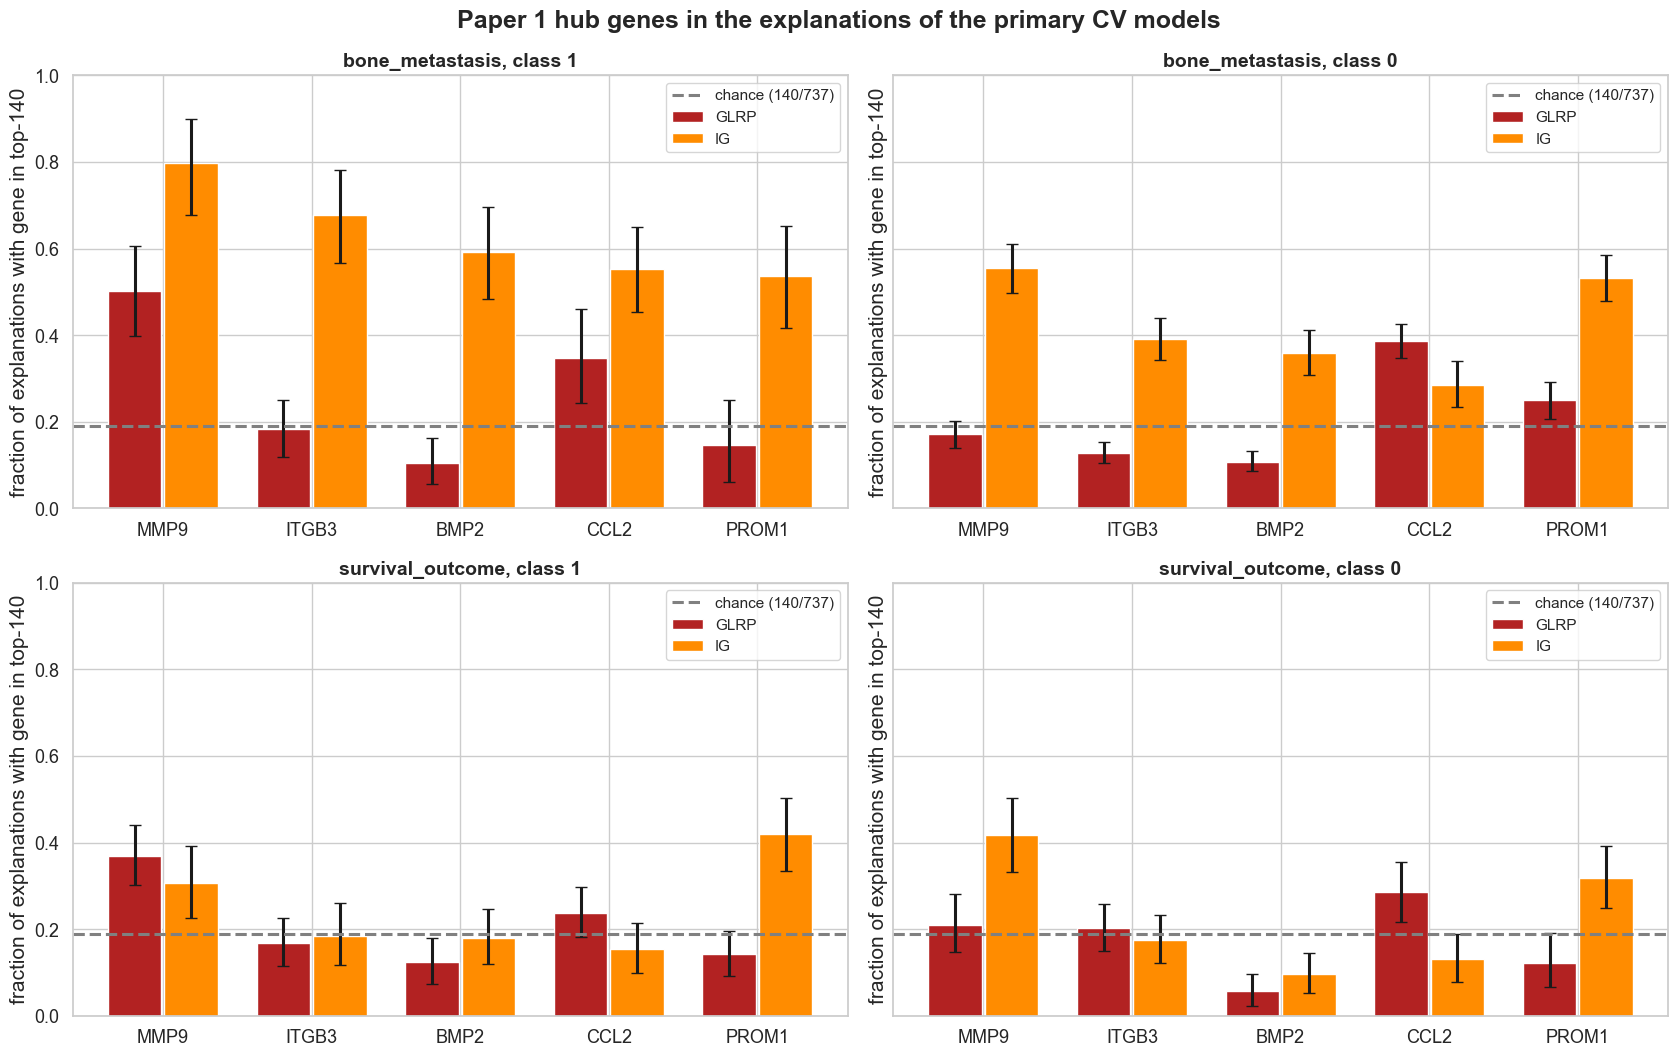

In [44]:
def perm_gap(sets1, sets0, n_perm=2000, seed=0):
    allS = sets1 + sets0; n1, n = len(sets1), len(allS)
    if n1 < 2 or n - n1 < 2:
        return np.nan, np.nan, np.nan, np.nan
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            M[i, j] = M[j, i] = len(allS[i] & allS[j]) / len(allS[i] | allS[j])
    def gap(lab):
        a, b = np.where(lab)[0], np.where(~lab)[0]
        w = np.concatenate([M[np.ix_(a, a)][np.triu_indices(len(a), 1)], M[np.ix_(b, b)][np.triu_indices(len(b), 1)]])
        return w.mean(), M[np.ix_(a, b)].mean()
    lab = np.zeros(n, bool); lab[:n1] = True
    w0, b0 = gap(lab); obs = w0 - b0; rng = np.random.default_rng(seed)
    perm = np.array([np.subtract(*gap(rng.permutation(lab))) for _ in range(n_perm)])
    return w0, b0, obs, (1 + np.sum(np.abs(perm) >= abs(obs))) / (n_perm + 1)

het = []
for task in TASKS:
    d = EXPL[(EXPL.family == "A") & (EXPL.task == task) & (EXPL.repeat == 0) & EXPL.correct]
    for meth in METHODS:
        s1 = [topk_idx(v, 140) for v in d[d.y == 1][meth]]; s0 = [topk_idx(v, 140) for v in d[d.y == 0][meth]]
        w, b, g, p = perm_gap(s1, s0)
        het.append({"task": task, "method": meth, "n_class1": len(s1), "n_class0": len(s0), "within_class_jaccard": w,
                    "between_class_jaccard": b, "gap": g, "permutation_P": p, "chance": expected_random_jaccard(140, N)})
heterogeneity = save_table(pd.DataFrame(het), "HETEROGENEITY_within_vs_between_class")
display(heterogeneity.round(4))

deg_set = set(deg_sig.gene) & set(gene_list)
cons_rows, hub_rows = [], []
for task in TASKS:
    for meth in METHODS:
        for y_ in [1, 0]:
            d = A_ok[(A_ok.task == task) & (A_ok.y == y_)]
            if d.empty:
                continue
            ind = np.zeros((len(d), N), bool)
            for i, v in enumerate(d[meth]):
                ind[i, list(topk_idx(v, 140))] = True
            per_sample = pd.DataFrame(ind, columns=gene_list).groupby(d.sample_id.values).mean()
            freq = per_sample.mean(0)
            consensus = set(freq[freq >= 0.5].index)
            kk = len(consensus & deg_set)
            p = hypergeom.sf(kk - 1, N, len(deg_set), len(consensus)) if consensus else np.nan
            cons_rows.append({"task": task, "method": meth, "class": y_, "n_samples": len(per_sample),
                              "n_consensus_genes_freq>=0.5": len(consensus), "consensus_genes_that_are_DEGs": kk,
                              "expected_by_chance": len(consensus) * len(deg_set) / N, "hypergeometric_P": p,
                              "top15_consensus_genes": ", ".join(freq.sort_values(ascending=False).head(15).index)})
            for g in HUB_GENES:
                lo, hi = boot_ci(per_sample[g].values)
                hub_rows.append({"task": task, "method": meth, "class": y_, "gene": g, "top140_frequency": freq[g],
                                 "CI95_lo": lo, "CI95_hi": hi, "chance": 140 / N})
consensus_summary = save_table(pd.DataFrame(cons_rows), "CONSENSUS_genes_and_DEG_overlap")
hub_freq = save_table(pd.DataFrame(hub_rows), "HUBGENE_top140_frequency")
display(consensus_summary)

fig, axes = plt.subplots(len(TASKS), 2, figsize=(17, 5.4 * len(TASKS)), squeeze=False, sharey=True)
for i, task in enumerate(TASKS):
    for j, y_ in enumerate([1, 0]):
        ax = axes[i, j]; x = np.arange(len(HUB_GENES))
        for k, meth in enumerate(METHODS):
            d = hub_freq[(hub_freq.task == task) & (hub_freq.method == meth) & (hub_freq["class"] == y_)].set_index("gene").reindex(HUB_GENES)
            ax.bar(x + (k - 0.5) * 0.38, d.top140_frequency, 0.36, color=METHOD_COLORS[meth], label=meth,
                   yerr=[d.top140_frequency - d.CI95_lo, d.CI95_hi - d.top140_frequency], capsize=4)
        ax.axhline(140 / N, color="grey", ls="--", label="chance (140/737)")
        ax.set_xticks(x); ax.set_xticklabels(HUB_GENES); ax.set_ylim(0, 1)
        ax.set_ylabel("fraction of explanations with gene in top-140")
        ax.set_title(f"{task}, class {y_}", fontsize=14); ax.legend(fontsize=11)
fig.suptitle("Paper 1 hub genes in the explanations of the primary CV models"); fig.tight_layout()
save_fig(fig, "06_hubgene_attribution_frequency")

## 9. Readable sample-specific subnetworks (replaces v14 Figure 10)

One typical correctly classified bone-metastasis sample is shown: the class-1 sample with the median predicted probability in repeat 0, not the most confident one. Panels show its **top 30** genes by |attribution| for each method, with STRING edges among them. Thirty genes, unlike v14's 140, keep every label legible.

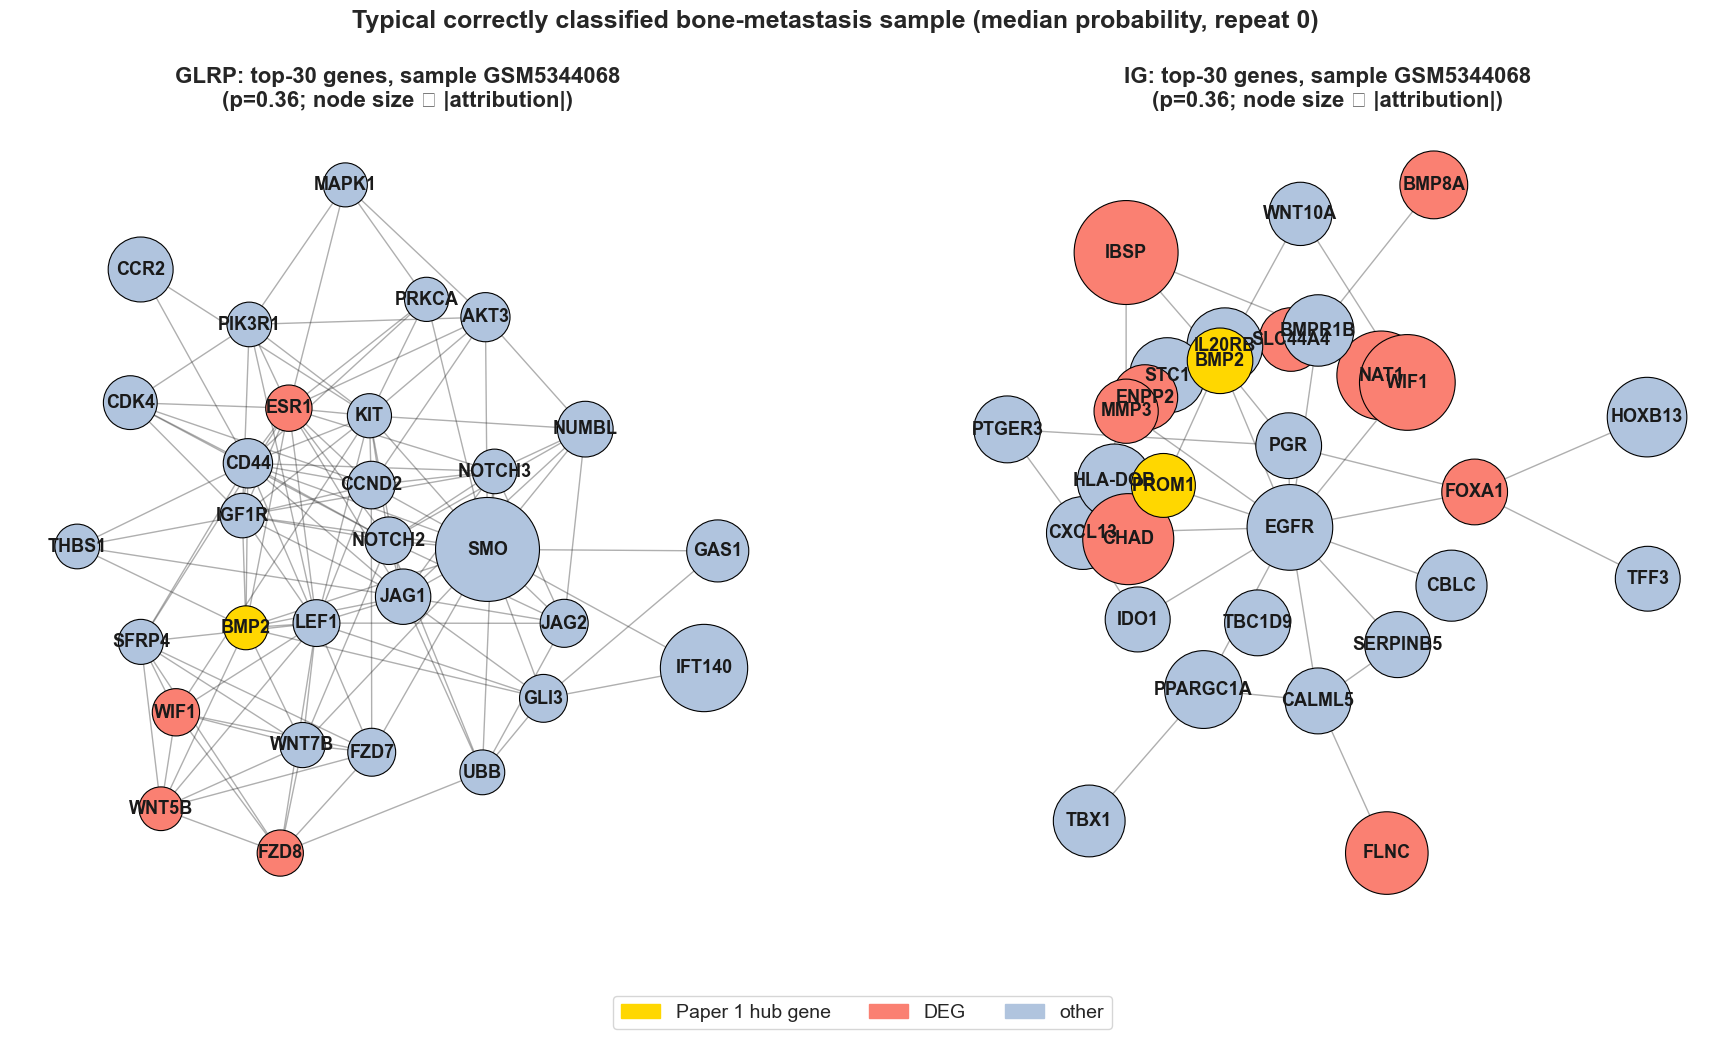

In [45]:
r0 = EXPL[(EXPL.family == "A") & (EXPL.task == "bone_metastasis") & (EXPL.repeat == 0) & EXPL.correct & (EXPL.y == 1)]
if len(r0):
    rep = r0.iloc[(r0.prob - r0.prob.median()).abs().argsort().iloc[0]]
    fig, axes = plt.subplots(1, 2, figsize=(22, 10.5))
    for ax, meth in zip(axes, METHODS):
        v = np.abs(rep[meth]); top = list(gene_arr[np.argsort(-v)[:30]])
        H = G_main.subgraph(top).copy(); H.add_nodes_from(top)
        pos = nx.kamada_kawai_layout(H) if H.number_of_edges() else nx.circular_layout(H)
        sizes = 600 + 5000 * v[[GIDX[g] for g in H.nodes()]] / v.max()
        cols = ["gold" if g in HUB_GENES else ("salmon" if g in deg_set else "lightsteelblue") for g in H.nodes()]
        nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.35, width=1.0)
        nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=cols, edgecolors="black", linewidths=0.8)
        nx.draw_networkx_labels(H, pos, ax=ax, font_size=13, font_weight="bold")
        ax.set_title(f"{meth}: top-30 genes, sample {rep.sample_id}\n(p={rep.prob:.2f}; node size ∝ |attribution|)", fontsize=16)
        ax.axis("off")
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color="gold", label="Paper 1 hub gene"), Patch(color="salmon", label="DEG"),
                        Patch(color="lightsteelblue", label="other")], loc="lower center", ncol=3, fontsize=14)
    fig.suptitle("Typical correctly classified bone-metastasis sample (median probability, repeat 0)")
    save_fig(fig, "07_representative_subnetworks_top30")

## 10. Complementary datasets (reviewer comment 6): what each can and cannot show

The frozen gene panel is fixed before these datasets are opened: DEGs ∪ Paper 1 hubs ∪ top-40 within-bone Cox genes ∪ IG consensus genes for the bone class (frequency ≥ 0.5). IG is used because it passed the stability and deletion checks better; Sections 3 and 5 show the numbers.
* **GSE131007** (scRNA-seq, PDX): bone-site cells come from **one** PDX model, so the comparison is summarized per model and site (pseudobulk) and is descriptive only. Cell-level P values would treat thousands of cells from one xenograft as independent replicates.
* **GSE334772** (NF1+ vs NF1-KO, n = 2 vs 2): descriptive log2FC, plus a hypergeometric test of whether the panel is enriched for NF1-responsive genes.
* **GSE190772** (bulk: 1 primary tumor vs 2 bone metastases): descriptive only; n = 1 patient.

In [46]:
ig_cons = set()
for task in ["bone_metastasis"]:
    d = A_ok[(A_ok.task == task) & (A_ok.y == 1)]
    if len(d):
        ind = np.zeros((len(d), N), bool)
        for i, v in enumerate(d["IG"]):
            ind[i, list(topk_idx(v, 140))] = True
        f_ = pd.DataFrame(ind, columns=gene_list).groupby(d.sample_id.values).mean().mean(0)
        ig_cons = set(f_[f_ >= 0.5].index)
frozen = {"DEG": set(deg_sig.gene), "Paper1_hub": set(HUB_GENES),
          "within_bone_Cox_top40": set(A1["within_bone_cox"].head(40).gene), "IG_consensus_bone": ig_cons}
panel = sorted(set().union(*frozen.values()))
frozen_panel = pd.DataFrame({"gene": panel, **{k: [g in v for g in panel] for k, v in frozen.items()}})
save_table(frozen_panel, "frozen_complementary_panel")
print(f"Frozen panel: {len(panel)} genes ({ {k: len(v) for k, v in frozen.items()} })")
comp_counts = []

# ---- GSE131007 ----
g131 = os.path.join(DATA_DIR, "GSE131007")
if os.path.isdir(g131):
    CODES = {"T": "Primary", "L": "Liver", "BO": "Bone", "BR": "Brain"}
    pb_rows, cell_counts = [], []
    for fn in sorted(os.listdir(g131)):
        if not fn.endswith(".tsv.gz"):
            continue
        m = pd.read_csv(os.path.join(g131, fn), sep="\t", index_col=0); m.index = m.index.astype(str).str.upper()
        m = m.groupby(level=0).sum() if m.index.duplicated().any() else m
        site = pd.Series([CODES.get(re.match(r"^UCD\d+([A-Za-z]+)_", c).group(1).upper()) if re.match(r"^UCD\d+([A-Za-z]+)_", c) else None
                          for c in m.columns], index=m.columns)
        model_id = re.search(r"(ucd\d+)", fn, re.I).group(1).upper()
        lib = m.sum(0)                                   # library size from all genes, then keep only what is needed
        keep = [g for g in dict.fromkeys(panel + HUB_GENES) if g in m.index]
        lognorm = np.log1p(m.loc[keep].div(lib, axis=1) * 1e4); del m
        genes_here = [g for g in panel if g in lognorm.index]
        z = lognorm.loc[genes_here]; z = z.sub(z.mean(1), axis=0).div(z.std(1).replace(0, np.nan), axis=0)
        sig = z.mean(0)
        for s_, idx in site.dropna().groupby(site.dropna()).groups.items():
            pb_rows.append({"PDX_model": model_id, "site": s_, "n_cells": len(idx), "pseudobulk_panel_score": sig[idx].mean(),
                            **{f"{g}_mean_lognorm": lognorm.loc[g, idx].mean() for g in HUB_GENES if g in lognorm.index}})
    pb = save_table(pd.DataFrame(pb_rows), "GSE131007_pseudobulk_by_model_site")
    display(pb.round(3))
    n_bone_models = pb[pb.site == "Bone"].PDX_model.nunique()
    comp_counts.append({"dataset": "GSE131007 scRNA-seq (PDX)", "groups": "; ".join(f"{s}: {pb[pb.site == s].PDX_model.nunique()} model(s), "
                                                                                   f"{int(pb[pb.site == s].n_cells.sum())} cells" for s in pb.site.unique()),
                        "biological replicates for bone": n_bone_models,
                        "permissible claim": "descriptive context only" if n_bone_models <= 1 else "pseudobulk comparison across models"})

# ---- GSE334772 ----
g334 = os.path.join(DATA_DIR, "GSE334772")
if os.path.isdir(g334):
    files = {"NF1_plus_rep1": "GSM9796867_M1", "NF1_plus_rep2": "GSM9796868_M2", "NF1_KO_rep1": "GSM9796869_MKO1", "NF1_KO_rep2": "GSM9796870_MKO2"}
    tpm = {}
    for k, stem in files.items():
        df_ = pd.read_csv(os.path.join(g334, stem + ".rsem.genes.results.gz"), sep="\t")
        df_["gene"] = df_.gene_id.astype(str).str.split("_", n=1).str[1].str.upper()
        tpm[k] = df_.groupby("gene").TPM.sum()
    tpm = pd.DataFrame(tpm)
    lfc = np.log2((tpm.filter(like="KO").mean(1) + 0.1) / (tpm.filter(like="plus").mean(1) + 0.1))
    universe = set(lfc.index) & set(gene_list); resp = set(lfc[lfc.abs() >= 1].index) & universe
    pri = set(panel) & universe; k_ = len(pri & resp)
    p_nf1 = hypergeom.sf(k_ - 1, len(universe), len(resp), len(pri))
    nf1 = save_table(pd.DataFrame([{"universe (panel genes measured)": len(universe), "NF1-responsive (|log2FC|>=1)": len(resp),
                                    "frozen-panel genes": len(pri), "overlap": k_, "expected": len(pri) * len(resp) / len(universe),
                                    "hypergeometric_P": p_nf1}]), "GSE334772_NF1_overlap")
    display(nf1.round(4))
    comp_counts.append({"dataset": "GSE334772 bulk RNA-seq (NF1+ vs NF1-KO)", "groups": "2 vs 2", "biological replicates for bone": 0,
                        "permissible claim": "mechanistic context; no enrichment" if p_nf1 >= 0.05 else "panel enriched for NF1-responsive genes"})

# ---- GSE190772 ----
g190 = os.path.join(DATA_DIR, "GSE190772_BoM_primary_bulkRNA.txt.gz")
if os.path.exists(g190):
    b = pd.read_csv(g190, sep="\t", index_col=0); b.index = b.index.astype(str).str.upper()
    b = b.groupby(level=0).mean()                       # a few symbols occur twice in the deposited table
    hub_b = b.reindex(HUB_GENES)
    hub_b["BoM_mean_minus_primary"] = hub_b[[c for c in b.columns if c.startswith("BoM")]].mean(1) - hub_b["Primary"]
    save_table(hub_b.reset_index().rename(columns={"index": "gene"}), "GSE190772_hubgenes_descriptive")
    display(hub_b.round(3))
    comp_counts.append({"dataset": "GSE190772 bulk (1 primary, 2 bone metastases)", "groups": "1 vs 2 samples, 1 patient",
                        "biological replicates for bone": 1, "permissible claim": "descriptive only"})
complementary = save_table(pd.DataFrame(comp_counts), "COMPLEMENTARY_datasets_sample_counts")
display(complementary)

Frozen panel: 114 genes ({'DEG': 68, 'Paper1_hub': 5, 'within_bone_Cox_top40': 40, 'IG_consensus_bone': 45})


,PDX_model,site,n_cells,pseudobulk_panel_score,MMP9_mean_lognorm,ITGB3_mean_lognorm,BMP2_mean_lognorm,PROM1_mean_lognorm,CCL2_mean_lognorm
0,UCD46,Liver,276,0.041,0.017,0.006,0.004,0.022,NaN
1,UCD46,Primary,470,-0.024,0.011,0.001,0.015,0.372,NaN
2,UCD4,Liver,3038,0.004,0.122,NaN,NaN,0.002,0.004
3,UCD4,Primary,3656,-0.003,0.144,NaN,NaN,0.001,0.018
4,UCD65,Bone,598,-0.027,0.014,NaN,0.006,NaN,0.000
5,UCD65,Brain,110,0.031,0.013,NaN,0.000,NaN,0.008
6,UCD65,Primary,1159,0.011,0.015,NaN,0.001,NaN,0.004


,universe (panel genes measured),NF1-responsive (|log2FC|>=1),frozen-panel genes,overlap,expected,hypergeometric_P
0,733,194,112,37,29.6426,0.0572


,Primary,BoM1,BoM2,BoM_mean_minus_primary
converted,,,,
MMP9,2.262,8.870,9.690,7.018
ITGB3,2.965,6.121,6.143,3.167
BMP2,0.876,5.027,4.358,3.817
CCL2,3.989,6.218,4.104,1.172
PROM1,4.358,0.232,2.517,-2.983


,dataset,groups,biological replicates for bone,permissible claim
0,GSE131007 scRNA-seq (PDX),"Liver: 2 model(s), 3314 cells; Primary: 3 model(s), 5285 cells; Bone: 1 mode...",1,descriptive context only
1,GSE334772 bulk RNA-seq (NF1+ vs NF1-KO),2 vs 2,0,mechanistic context; no enrichment
2,"GSE190772 bulk (1 primary, 2 bone metastases)","1 vs 2 samples, 1 patient",1,descriptive only


## 11. Explanation summary: stability, faithfulness, label sensitivity, plausibility

One row per task and method. These are separate properties and are reported separately:
* **stability** — does the same explanation come back when the model is retrained?
* **faithfulness** — does removing the top genes change the model's output more than removing random genes?
* **label sensitivity** — do the explanations depend on the learned labels?
* **plausibility** — do the top genes overlap known biology?

A method can be plausible without being faithful or stable.

In [47]:
summ = []
ps = A2["primary_summary"]
for task in TASKS:
    perf = ps[(ps.task == task) & (ps.model == "GCN_real_K7")].iloc[0]
    for meth in METHODS:
        g = lambda fam, m: gene_stab_summary[(gene_stab_summary.task == task) & (gene_stab_summary.family == fam) &
                                             (gene_stab_summary.method == meth) & (gene_stab_summary.metric == m)].iloc[0]
        a20, b20, a140 = g("A", "jac_top20"), g("B", "jac_top20"), g("A", "jac_top140")
        pw = pw_summary[(pw_summary.task == task) & (pw_summary.family == "A") & (pw_summary.method == meth)].set_index("metric")
        dl = deletion_summary[(deletion_summary.task == task) & (deletion_summary.method == meth) & (deletion_summary.baseline == "train_median")]
        ao = aopc_summary[(aopc_summary.task == task) & (aopc_summary.method == meth) & (aopc_summary.baseline == "train_median")].iloc[0]
        lc = label_ctrl_summary[(label_ctrl_summary.task == task) & (label_ctrl_summary.method == meth) & (label_ctrl_summary.top_k == 140)].iloc[0]
        cs = consensus_summary[(consensus_summary.task == task) & (consensus_summary.method == meth) & (consensus_summary["class"] == 1)]
        summ.append({"task": task, "method": meth,
                     "model fold-avg AUC [95% CI]": f"{perf.fold_avg_AUC:.3f} [{perf.fold_avg_CI_lo:.3f}, {perf.fold_avg_CI_hi:.3f}]",
                     "STABILITY top-20 Jaccard, diff. data [CI] (chance)": f"{a20['mean']:.3f} [{a20.CI95_lo:.3f}, {a20.CI95_hi:.3f}] ({a20.chance:.3f})",
                     "STABILITY top-20 Jaccard, same data [CI]": f"{b20['mean']:.3f} [{b20.CI95_lo:.3f}, {b20.CI95_hi:.3f}]",
                     "STABILITY top-140 Jaccard, diff. data": f"{a140['mean']:.3f} ({a140.fold_over_chance:.1f}x chance)",
                     "PATHWAY score Spearman, diff. data": f"{pw.loc['pathway_score_spearman', 'mean']:.3f}",
                     "PATHWAY enrichment Jaccard (uncond.)": f"{pw.loc['enrich_jaccard_unconditional', 'mean']:.3f}",
                     "FAITHFULNESS budgets passing (of 12)": int(dl.passes.sum()),
                     "FAITHFULNESS AOPC top−random [CI]": f"{ao.AOPC_top_minus_random:+.4f} [{ao.CI95_lo:+.4f}, {ao.CI95_hi:+.4f}]",
                     "LABEL SENSITIVITY real−null top-140 Jaccard (P_Holm)": f"{lc.difference:+.3f} ({lc.P_Holm:.2g})",
                     "follows input expression (Spearman)": f"{lc.spearman_attribution_vs_input:.2f}",
                     "PLAUSIBILITY consensus∩DEG (class 1)": (f"{int(cs['consensus_genes_that_are_DEGs'].iloc[0])}/{int(cs['n_consensus_genes_freq>=0.5'].iloc[0])}"
                                                             if len(cs) else "n/a"),
                     "status": "exploratory (weak model)" if perf.fold_avg_CI_lo < 0.6 else "primary"})
EXPLANATION_SUMMARY = save_table(pd.DataFrame(summ), "EXPLANATION_SUMMARY_TABLE")
display(EXPLANATION_SUMMARY.set_index(["task", "method"]).T)

print("Generated wording:")
for r in EXPLANATION_SUMMARY.itertuples():
    print(f"  [{r.task} | {r.method}] stability top-20 (different data) {r[4]}; faithfulness: {r[9]} of 12 budgets passed, "
          f"AOPC {r[10]}; label sensitivity {r[11]}; status: {r.status}.")
print(f"\nPart 3 finished in {(time.time() - T0_NOTEBOOK) / 60:.1f} min. Tables: {OUT_DIR}  Figures: {FIG_DIR}")

task                                                               bone_metastasis                                            survival_outcome                              
method                                                                        GLRP                            IG                          GLRP                            IG
model fold-avg AUC [95% CI]                                   0.883 [0.776, 0.989]          0.883 [0.776, 0.989]          0.693 [0.585, 0.801]          0.693 [0.585, 0.801]
STABILITY top-20 Jaccard, diff. data [CI] (chance)    0.029 [0.027, 0.031] (0.014)  0.148 [0.142, 0.155] (0.014)  0.032 [0.028, 0.036] (0.014)  0.152 [0.144, 0.159] (0.014)
STABILITY top-20 Jaccard, same data [CI]                      0.027 [0.026, 0.028]          0.146 [0.140, 0.151]          0.055 [0.052, 0.059]          0.177 [0.169, 0.184]
STABILITY top-140 Jaccard, diff. data                          0.164 (1.6x chance)           0.299 (2.8x chance)           0.153 (1.5x chance)           0.286 (2.7x chance)
PATHWAY score Spearman, diff. data                                           0.181                         0.526                         0.132                         0.525
PATHWAY enrichment Jaccard (uncond.)                                         0.050                         0.001                         0.037                         0.001
FAITHFULNESS budgets passing (of 12)                                             1                            11                             1                             9
FAITHFULNESS AOPC top−random [CI]                       +0.0048 [+0.0032, +0.0065]    +0.0117 [+0.0088, +0.0150]    +0.0060 [+0.0039, +0.0083]    +0.0164 [+0.0117, +0.0214]
LABEL SENSITIVITY real−null top-140 Jaccard (P_Holm)              +0.006 (0.00039)              +0.015 (1.5e-27)                    -0.021 (1)              +0.036 (1.9e-15)
follows input expression (Spearman)                                           0.37                         -0.09                          0.36                         -0.10
PLAUSIBILITY consensus∩DEG (class 1)                                          1/12                         34/45                           0/8                          7/30
status                                                                     primary                       primary      exploratory (weak model)      exploratory (weak model)

Generated wording:
  [bone_metastasis | GLRP] stability top-20 (different data) 0.029 [0.027, 0.031] (0.014); faithfulness: 1 of 12 budgets passed, AOPC +0.0048 [+0.0032, +0.0065]; label sensitivity +0.006 (0.00039); status: primary.
  [bone_metastasis | IG] stability top-20 (different data) 0.148 [0.142, 0.155] (0.014); faithfulness: 11 of 12 budgets passed, AOPC +0.0117 [+0.0088, +0.0150]; label sensitivity +0.015 (1.5e-27); status: primary.
  [survival_outcome | GLRP] stability top-20 (different data) 0.032 [0.028, 0.036] (0.014); faithfulness: 1 of 12 budgets passed, AOPC +0.0060 [+0.0039, +0.0083]; label sensitivity -0.021 (1); status: exploratory (weak model).
  [survival_outcome | IG] stability top-20 (different data) 0.152 [0.144, 0.159] (0.014); faithfulness: 9 of 12 budgets passed, AOPC +0.0164 [+0.0117, +0.0214]; label sensitivity +0.036 (1.9e-15); status: exploratory (weak model).

Part 3 finished in 9.9 min. Tables: /Users/soumyasriperepu/researchAgent/version 15/output/nb

# Reviewer checklist (generated from this run)

This last cell reads the results of the run that just finished and reports, for each reviewer comment, the key numbers and whether the run is **final**. A run is final when it used the full settings: QUICK_TEST off, 5 × 5-fold CV, 30 epochs, 20 shuffled graphs, 20 permutation seeds, 10 retraining seeds. Paste these numbers into the response letter only when the status says FINAL.

In [48]:
_cfg = A2["config"]
_quick = bool(globals().get("QUICK_TEST", False))
_full = (not _quick) and _cfg["N_REPEATS"] == 5 and _cfg["N_EPOCHS"] == 30
_status = ("NOT FINAL - rerun with QUICK_TEST off" if not _full else
           ("FINAL (fast profile: %d shuffled graphs, %d permutation seeds)" % (_cfg.get("N_SHUFFLED_GRAPHS", 20), _cfg.get("N_NULL_SEEDS", 20))
            if _cfg.get("FAST_PROFILE") else "FINAL (full settings)"))
_ps = A2["primary_summary"]
def _g(task, model, col):
    d = _ps[(_ps.task == task) & (_ps.model == model)]
    return d[col].iloc[0] if len(d) else np.nan
rows = []
for task in TASKS:
    rows.append(("1 Performance consistency", task,
                 f"Graph-CNN fold-avg AUC {_g(task, 'GCN_real_K7', 'fold_avg_AUC'):.3f} "
                 f"[{_g(task, 'GCN_real_K7', 'fold_avg_CI_lo'):.3f}, {_g(task, 'GCN_real_K7', 'fold_avg_CI_hi'):.3f}]; pooled OOF "
                 f"{_g(task, 'GCN_real_K7', 'pooled_OOF_AUC'):.3f}; rank-pooled {_g(task, 'GCN_real_K7', 'rank_pooled_AUC'):.3f}; "
                 f"RF {_g(task, 'RandomForest', 'fold_avg_AUC'):.3f}"))
    sn = A2["shuffle_null"]; sn = sn[sn.task == task]
    tt = A2["topo_tests"]; tt = tt[(tt.task == task) & tt.comparison.str.contains("mean of")]
    kn = A2["k_nested"]
    kn_txt = ""
    if kn is not None and len(kn[kn.task == task]):
        r = kn[kn.task == task].iloc[0]
        kn_txt = f"; nested-K AUC {r.nested_fold_avg_AUC:.3f}, K=7 chosen {int(r.times_K7_chosen)}/{int(r.n_outer_folds)}"
    rows.append(("2 Topology and filter order", task,
                 f"{int(sn.n_shuffled.iloc[0])} shuffled graphs; empirical P "
                 + " / ".join(f"{s.statistic}: {s.empirical_P_one_sided:.3f}" for s in sn.itertuples())
                 + (f"; real minus shuffled-mean ΔAUC {tt.A_fold_AUC_diff.iloc[0]:+.3f}, P_Holm {tt.A_P_Holm.iloc[0]:.3g}" if len(tt) else "")
                 + kn_txt))
    for meth in METHODS:
        st = gene_stab_summary[(gene_stab_summary.task == task) & (gene_stab_summary.family == "A") &
                               (gene_stab_summary.method == meth) & (gene_stab_summary.metric == "jac_top20")]
        pw = pw_summary[(pw_summary.task == task) & (pw_summary.family == "A") & (pw_summary.method == meth) &
                        (pw_summary.metric == "pathway_score_spearman")]
        ao = aopc_summary[(aopc_summary.task == task) & (aopc_summary.method == meth) & (aopc_summary.baseline == "train_median")]
        nb_ = deletion_summary[(deletion_summary.task == task) & (deletion_summary.method == meth) &
                               (deletion_summary.baseline == "train_median")]
        rows.append(("3 Explanation reliability", f"{task} | {meth}",
                     f"top-20 Jaccard {st['mean'].iloc[0]:.3f} [{st.CI95_lo.iloc[0]:.3f}, {st.CI95_hi.iloc[0]:.3f}] (chance "
                     f"{expected_random_jaccard(20, N):.3f}); pathway-score Spearman {pw['mean'].iloc[0]:.3f}; deletion budgets passed "
                     f"{int(nb_.passes.sum())}/{nb_.budget.nunique()}; AOPC {ao.AOPC_top_minus_random.iloc[0]:+.4f} "
                     f"[{ao.CI95_lo.iloc[0]:+.4f}, {ao.CI95_hi.iloc[0]:+.4f}]"))
    cm = A2["composition_models"]
    if cm is not None:
        c = cm[cm.task == task]
        g = c[c.model == "GCN_real_K7"].set_index("variant")
        co = c[c.variant.str.startswith("composition")]
        rows.append(("4 Tissue composition", task,
                     f"composition-only AUC {co.fold_avg_AUC.iloc[0]:.3f}; Graph-CNN original {g.loc['original', 'fold_avg_AUC']:.3f} -> "
                     f"neutralized {g.loc['markers neutralized', 'fold_avg_AUC']:.3f}, residualized "
                     f"{g.loc['residualized on composition', 'fold_avg_AUC']:.3f}; attribution: see COMPOSITION_combined_verdict"))
    ns = A2["null_summary"]
    if ns is not None:
        a = ns[(ns.task == task) & (ns.model == "GCN_real_K7") & ns["mode"].str.startswith("A")]
        b = ns[(ns.task == task) & (ns.model == "GCN_real_K7") & ns["mode"].str.startswith("B")]
        lc = label_ctrl_summary[(label_ctrl_summary.task == task) & (label_ctrl_summary.top_k == 140)]
        rows.append(("5 Label-shuffled controls", task,
                     f"{int(a.n_seeds.iloc[0])} seeds; null test AUC {a.null_test_AUC_mean.iloc[0]:.3f} vs real "
                     f"{a.real_model_test_AUC_repeat0.iloc[0]:.3f} (P={a.empirical_P_real_vs_null.iloc[0]:.3f}); checkpoint optimism "
                     f"{b.selection_optimism_best_minus_last.iloc[0]:+.3f}; explanation real-null ΔJaccard "
                     + ", ".join(f"{r.method} {r.difference:+.3f}" for r in lc.itertuples())))
sv = A1["SURVIVAL_EVIDENCE"]
for gene in ["PROM1", "CCL2"]:
    u = sv[(sv.cohort == "GSE175692") & (sv.analysis == "univariate") & (sv.term == gene)].iloc[0]
    a = sv[(sv.cohort == "GSE175692") & sv.analysis.str.startswith("adjusted (HR") & (sv.term == gene)].iloc[0]
    rows.append(("6 Survival evidence", gene, f"univariate {u.estimate}, FDR {u.FDR:.3g} (n={u.n}, {u.events} events); "
                 f"adjusted {a.estimate}, P {a.P:.3g} (n={a.n}, {a.events} events)"))
rows.append(("7 Figures", "all", f"300-dpi PNG + vector PDF in {os.path.join(PROJECT_ROOT, 'figures')}"))
REVIEWER_CHECKLIST = pd.DataFrame(rows, columns=["reviewer comment", "scope", "key result from this run"])
REVIEWER_CHECKLIST.insert(0, "status", _status)
REVIEWER_CHECKLIST.to_csv(os.path.join(PROJECT_ROOT, "output", "REVIEWER_CHECKLIST.csv"), index=False)
with pd.option_context("display.max_colwidth", 400):
    display(REVIEWER_CHECKLIST)
print(f"Run status: {_status}")

,status,reviewer comment,scope,key result from this run
0,FINAL (full settings),1 Performance consistency,bone_metastasis,"Graph-CNN fold-avg AUC 0.883 [0.776, 0.989]; pooled OOF 0.779; rank-pooled 0.882; RF 0.927"
1,FINAL (full settings),2 Topology and filter order,bone_metastasis,"20 shuffled graphs; empirical P fold-averaged AUC: 0.667 / pooled OOF AUC: 0.429; real minus shuffled-mean ΔAUC -0.001, P_Holm 1; nested-K AUC 0.872, K=7 chosen 5/25"
2,FINAL (full settings),3 Explanation reliability,bone_metastasis | GLRP,"top-20 Jaccard 0.029 [0.027, 0.031] (chance 0.014); pathway-score Spearman 0.181; deletion budgets passed 1/12; AOPC +0.0048 [+0.0032, +0.0065]"
3,FINAL (full settings),3 Explanation reliability,bone_metastasis | IG,"top-20 Jaccard 0.148 [0.142, 0.155] (chance 0.014); pathway-score Spearman 0.526; deletion budgets passed 11/12; AOPC +0.0117 [+0.0088, +0.0150]"
4,FINAL (full settings),4 Tissue composition,bone_metastasis,"composition-only AUC 0.911; Graph-CNN original 0.883 -> neutralized 0.886, residualized 0.670; attribution: see COMPOSITION_combined_verdict"
5,FINAL (full settings),5 Label-shuffled controls,bone_metastasis,"10 seeds; null test AUC 0.475 vs real 0.855 (P=0.091); checkpoint optimism +0.069; explanation real-null ΔJaccard GLRP +0.006, IG +0.015"
6,FINAL (full settings),1 Performance consistency,survival_outcome,"Graph-CNN fold-avg AUC 0.693 [0.585, 0.801]; pooled OOF 0.621; rank-pooled 0.694; RF 0.711"
7,FINAL (full settings),2 Topology and filter order,survival_outcome,"20 shuffled graphs; empirical P fold-averaged AUC: 0.333 / pooled OOF AUC: 0.143; real minus shuffled-mean ΔAUC +0.009, P_Holm 1; nested-K AUC 0.676, K=7 chosen 5/25"
8,FINAL (full settings),3 Explanation reliability,survival_outcome | GLRP,"top-20 Jaccard 0.032 [0.028, 0.036] (chance 0.014); pathway-score Spearman 0.132; deletion budgets passed 1/12; AOPC +0.0060 [+0.0039, +0.0083]"
9,FINAL (full settings),3 Explanation reliability,survival_outcome | IG,"top-20 Jaccard 0.152 [0.144, 0.159] (chance 0.014); pathway-score Spearman 0.525; deletion budgets passed 9/12; AOPC +0.0164 [+0.0117, +0.0214]"


Run status: FINAL (full settings)
